# Set up

In [ ]:
### Load - Plot and Save compaction data from Big Biax experiments ###
import os,random,warnings,sys,io,re, json,glob
import matplotlib
matplotlib.use('Agg')  # Must be before importing plt
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import numpy as np
import ast
import pandas as pd
from pathlib import Path
from obspy.signal.trigger import classic_sta_lta, trigger_onset
# Ignore all warnings
warnings.filterwarnings("ignore")
sys.path.append('/home/giacomomastella/Documents/BigBiax/Code/previous/')
sys.path.append('/home/giacomomastella/Documents/BigBiax/Code/')
from Utilities import *
from Big_biax_block import *
import math
import pickle
from scipy.signal import find_peaks
%matplotlib widget
import matplotlib.cm as cm
from scipy.interpolate import griddata


# Picking setup

In [49]:

def loading_infoB(folder_path,metadata_file,verbose=False):
    '''
    Loading information of the experiment 

    Parameters:
    ----------
        folder_path: folder of the data
        metadata_file: .txt metadata file

    Returns:
    ----------
        fs: sampling frequency
        f_chunk: number of samples of one chunk
        info_data: info 
        float_type: float format of saved data
        channels_names: list of channels names

    '''

    info_line = None  # define outside
    float_type = None
    channels_names=None
    with open(folder_path +metadata_file, "r") as file:
        z=0
        for line in file:
            if z>0:
                if "Selected Sample frequency" in line:
                    fs= line.strip()  # save the line
                    match = re.search(r'([\d\.]+)\s*MHz', fs)

                    if match:
                        value_mhz = float(match.group(1))  # e.g., 6.25
                        fs = value_mhz * 1e6         # convert MHz to Hz

                if " Chunks length" in line:
                    f_chunk= line.strip()  # save the line
                    f_chunk = int(re.search(r'\d+', f_chunk).group())

                if "float type" in line:
                    float_type= line.split(':')[1]
                    float_type = float_type.strip(" '\"\n")

                if "channel_names" in line:
                    list_str = line.split(':')[1].strip()

                    # Convert string to actual Python list
                    channels_names = ast.literal_eval(list_str)


                if "Info" in line:
                    info_line = line.strip()  # save the line
                    break
            z+=1

    if info_line is not None:
        # Split at the first colon
        parts = info_line.split(":", 1)
        if len(parts) > 1:
            info_data = parts[1].strip()
            if verbose==True:
                print("Extracted Info:", info_data)
        else:
            print("Colon not found in line:", info_line)
    else:
        print("No Info line found.")

    if verbose==True:
        print('\nSample frequency: ',fs/1e6,' MHz')
        print('\nChunk size: ', f_chunk/1e6,' megasamples')
        print('\nfloat type: ', float_type)
        print('\nchannels_names: ', channels_names)
  
    return fs, f_chunk,float_type,channels_names,info_data

def create_data_chunkB(input_folder,list_channels,chunk,float_type=None):
    
    '''
    Parameters
    ---------
       input_folder: folder of experiment
       list_channels: list channels to consider (e.g. [1,2,5], consider channels 1,2,5)
       chunk: chunk number
       float_type: or 'float16' o 'float32' or 'float64'
       
    Returns
    ---------
       data_chunk: array of the chunk with shape=(number_ch,1/fs*len(1chunck)) 
    
    '''
    #list_channels=range(1,len(list_channels)+1)
    number_ch=len(list_channels)
    data_chunk=[[] for i in range(number_ch)]
    chunk_name='ball_drop_segment_'+str(chunk)
    
    
    for i in range(len(data_chunk)):
        ch_n=int(list_channels[i])
        fileName=os.path.join(input_folder,chunk_name+'_ch'+str(ch_n)+'.bin')
        
        if not os.path.exists(fileName) or not os.path.isfile(fileName):
            raise FileNotFoundError(f"The file '{fileName}' does not exist.")
  
        with open(fileName, mode='rb') as file: # b is important -> binary
            if float_type=='float32':
                content=np.frombuffer(file.read(),dtype='float32')
                content=np.array(content[32::].tolist())
            elif float_type=='float16':
                content=np.frombuffer(file.read(),dtype='float16')
                content=np.array(content[64::].tolist())
            elif float_type=='float64':
                content=np.frombuffer(file.read(),dtype='float64')
                content=np.array(content[16::].tolist())
                
            else:
                raise ValueError("float type is not valid! Put float32 or float16")
        data_chunk[i]=content
    return np.array(data_chunk)
    
def compute_aic_fast(signal):
    """
    Computes the Akaike Information Criterion (AIC) for a signal trace using 
    a highly optimized vectorized approach.
    
    This function splits the signal at every possible index 'k' and calculates 
    the variance of the two resulting segments to find the point where the 
    statistical properties change (the optimal pick time).

    Parameters
    ----------
    signal : numpy.ndarray
        The input signal segment (usually centered around an onset).

    Returns
    -------
    aic : numpy.ndarray
        The AIC curve. The global minimum typically represents the 
        precise arrival time of the wave.
    """
    N = len(signal)
    
    # Safety check: AIC requires a minimum number of samples for statistical validity
    if N < 10: 
        return np.zeros(N)
    
    # --- Vectorized Variance Calculation ---
    # We use cumulative sums (cumsum) of the signal and its square to calculate 
    # running variances without using slow Python loops.
    s = np.cumsum(signal)
    s2 = np.cumsum(signal**2)
    
    # Array of indices from 1 to N-1
    k = np.arange(1, N)
    
    # Calculate variance for the 'left' segment (from start to k)
    # var = E[X^2] - (E[X])^2
    var1 = np.maximum((s2[:-1] / k) - (s[:-1] / k)**2, 1e-12)
    
    # Calculate variance for the 'right' segment (from k to end)
    num_back = N - k
    var2 = np.maximum(((s2[-1] - s2[:-1]) / num_back) - ((s[-1] - s[:-1]) / num_back)**2, 1e-12)
    
    # --- AIC Formula ---
    # AIC(k) = k * log(var(signal[0:k])) + (N-k-1) * log(var(signal[k:N]))
    aic = np.zeros(N)
    
    # Compute AIC for all indices except the boundaries
    aic[1:-1] = k[:-1] * np.log(var1[:-1]) + (N - k[:-1] - 1) * np.log(var2[:-1])
    
    # Penalize boundaries to ensure the minimum is found within the signal body
    aic[0] = aic[-1] = aic[1:-1].max()
    
    return aic

# --- 2. CALCOLO PICKING (SENZA PLOT - ISTANTANEO) ---

def get_picks_only(data_chunk, fs, channel_ids, sta_sec=0.0002, lta_sec=0.1, thr_on=5, thr_off=3, AIC_window=0.001):
    """
    Performs fast, production-grade event picking using STA/LTA and AIC refinement 
    without generating any plots, optimized for speed and real-time processing.
    Supports both float values and dictionaries for per-channel parameter configuration.

    Parameters
    ----------
    data_chunk : numpy.ndarray
        Input signal data with shape (n_channels, n_samples).
    fs : float
        Sampling frequency in Hz.
    channel_ids : list
        List of identifiers/labels for each channel.
    sta_sec : float or dict, optional
        Short-Term Average window in seconds. Can be float or dict {'CH_NAME': val, 'DEFAULT': default_val}.
    lta_sec : float or dict, optional
        Long-Term Average window in seconds. Can be float or dict {'CH_NAME': val, 'DEFAULT': default_val}.
    thr_on : float or dict, optional
        Threshold ratio to trigger the start of an event. Can be float or dict.
    thr_off : float or dict, optional
        Threshold ratio to de-trigger (end of event). Can be float or dict.
    AIC_window: float or dict, optional
        Define a window in seconds around the onset to pinpoint arrival with AIC. Can be float or dict.

    Returns
    -------
    all_picks : list of list of float
        A list containing the picked arrival times (in seconds) for each channel.
    cft_list : list of numpy.ndarray
        The Characteristic Function (CFT) array calculated for each channel.
    onsets_list : list of list of tuple
        The raw (onset, offset) index pairs detected by the trigger for each channel.
    """

    n_ch = data_chunk.shape[0]
    n_samples = data_chunk.shape[1]
    all_picks = []
    cft_list = []
    onsets_list = []

    # Funzione helper interna per estrarre il parametro dal canale o dal default
    def _parse_param(param, ch_name, default_fallback):
        if isinstance(param, dict):
            return param.get(ch_name, param.get('DEFAULT', default_fallback))
        return param

    for i in range(n_ch):
        trace = data_chunk[i]
        current_ch_name = channel_ids[i]
        
        # --- ESTRAZIONE DINAMICA DEI PARAMETRI PER CANALE ---
        current_sta_sec    = _parse_param(sta_sec, current_ch_name, 0.0002)
        current_lta_sec    = _parse_param(lta_sec, current_ch_name, 0.1)
        current_thr_on     = _parse_param(thr_on, current_ch_name, 5)
        current_thr_off    = _parse_param(thr_off, current_ch_name, 3)
        current_AIC_window = _parse_param(AIC_window, current_ch_name, 0.001)
        # ----------------------------------------------------
        
        # --- Conversione Finestre STA/LTA in campioni ---
        nsta, nlta = int(current_sta_sec * fs), int(current_lta_sec * fs)
        
        # Calcola la Characteristic Function (CFT) e estrae i trigger
        cft = classic_sta_lta(trace, nsta, nlta)
        
        # Estrazione onset con soglie specifiche
        onsets = trigger_onset(cft, current_thr_on, current_thr_off)
        
        ch_picks = []
        for onset in onsets:
            # --- High-Speed AIC Windowing con ampiezza specifica ---
            win = int(current_AIC_window * fs) 
            idx_l, idx_h = max(0, onset[0] - win), min(n_samples, onset[0] + win)
            
            # Affinamento del tempo di arrivo con AIC
            if (idx_h - idx_l) > 10:
                aic_curve = compute_aic_fast(trace[idx_l:idx_h])
                ch_picks.append((idx_l + np.argmin(aic_curve)) / fs)
        
        all_picks.append(ch_picks)
        cft_list.append(cft)
        onsets_list.append(onsets)
        
    return all_picks, cft_list, onsets_list

def associate_picks_unique(all_picks, channel_ids, tolerance=0.001):
    """
    Associates chronological signal picks into unique event groups based on a 
    time tolerance, ensuring each channel appears only once per event group.

    Parameters
    ----------
    all_picks : list of list of float
        A nested list where each sublist contains the picked arrival times (in seconds) 
        for a specific channel.
    channel_ids : list
        List of identifiers corresponding to each channel index.
    tolerance : float, optional
        The maximum time window (in seconds) allowed between consecutive picks 
        to consider them part of the same event. Default is 0.001s (1 ms). It dependes on the maximum source/receiver travel time distance.

    Returns
    -------
    groups : list of list of dict
        A list of grouped events, where each group contains dictionaries with 
        'time' and 'ch' for the associated unique picks.
    """
    # Flatten the nested list of picks into a single list of dictionaries
    flat_picks = []
    for i, picks in enumerate(all_picks):
        for p_time in picks:
            flat_picks.append({'time': p_time, 'ch': channel_ids[i]})
    
    # Sort all picks globally by their arrival time
    flat_picks.sort(key=lambda x: x['time'])
    
    # Quick exit if no picks were found
    if not flat_picks: 
        return []

    # Initialize grouping variables
    groups, current_group = [], [flat_picks[0]]
    channels_in_group = {flat_picks[0]['ch']}
    
    # Iterate through the sorted picks to cluster them into events
    for i in range(1, len(flat_picks)):
        pick = flat_picks[i]
        
        # Calculate time delta between the current pick and the previous one
        dt = pick['time'] - flat_picks[i-1]['time']
        
        # Condition: check if the pick falls within the tolerance window 
        # AND its channel hasn't already contributed to the current event group
        if dt <= tolerance and pick['ch'] not in channels_in_group:
            current_group.append(pick)
            channels_in_group.add(pick['ch'])
        else:
            # Close the current group and start a new one
            groups.append(current_group)
            current_group = [pick]
            channels_in_group = {pick['ch']}
            
    # Don't forget to append the final open group
    groups.append(current_group)
    
    return groups

def plot_full_resolution_picking(data_chunk, fs, channel_ids, sta_sec=0.0002, lta_sec=0.1, thr_on=5, thr_off=3,AIC_window=0.001):
    """
    Performs event picking using STA/LTA and AIC refinement, and plots the high-resolution results.

    Parameters
    ----------
    data_chunk : numpy.ndarray
        Input signal data with shape (n_channels, n_samples).
    fs : float
        Sampling frequency in Hz.
    channel_ids : list
        List of identifiers/labels for each channel.
    sta_sec : float, optional
        Short-Term Average window in seconds.
    lta_sec : float, optional
        Long-Term Average window in seconds.
    thr_on : float, optional
        Threshold ratio to trigger the start of an event.
    thr_off : float, optional
        Threshold ratio to de-trigger (end of event).
    AIC_window: float, optional
        Define a narrow window (0.001s) around the onset to pinpoint the arrival with AIC

    Returns
    -------
    all_picks : list of list
        A list containing the picked arrival times (in seconds) for each channel.
    """
    plt.style.use('fast')
    n_ch = data_chunk.shape[0]
    n_samples = data_chunk.shape[1]
    
    # Create the time axis based on sampling frequency
    time_axis = np.linspace(0, n_samples/fs, n_samples)
    
    # Initialize subplots: 2 rows per channel (Signal + Characteristic Function)
    fig, axes = plt.subplots(n_ch * 2, 1, figsize=(14, 3.5 * n_ch), sharex=True)
    if n_ch == 1: 
        axes = [axes[0], axes[1]] # Handle single-channel indexing edge case
    
    all_picks = []

    for i in range(n_ch):
        trace = data_chunk[i]
        real_id = channel_ids[i]
        
        # --- STA/LTA Analysis ---
        # Convert window durations from seconds to number of samples
        nsta, nlta = int(sta_sec * fs), int(lta_sec * fs)
        
        # Calculate Characteristic Function (CFT) and detect onsets
        cft = classic_sta_lta(trace, nsta, nlta)
        onsets = trigger_onset(cft, thr_on, thr_off)
        
        ch_picks = []
        for onset in onsets:
            # --- AIC Refinement ---
            # Define a narrow window (0.001s) around the onset to pinpoint the arrival
            win = int(AIC_window * fs) 
            idx_l, idx_h = max(0, onset[0] - win), min(n_samples, onset[0] + win)
            
            # Compute AIC only if the window contains enough samples
            if (idx_h - idx_l) > 10:
                aic_curve = compute_aic_fast(trace[idx_l:idx_h])
                # The pick is identified where the AIC curve is minimized
                ch_picks.append((idx_l + np.argmin(aic_curve)) / fs)
        
        all_picks.append(ch_picks)

        # --- Plotting: Signal Trace ---
        ax_sig = axes[i*2]
        ax_sig.plot(time_axis, trace, color='black', lw=0.5)
        
        # Add vertical lines and text labels for each pick
        for p in ch_picks:
            ax_sig.axvline(p, color='red', ls='--', lw=1.2)
            ax_sig.text(p, ax_sig.get_ylim()[1]*0.7, f' {p:.4f}s', color='red', fontsize=8)
        ax_sig.set_ylabel(f"CH {real_id}\nAmp")

        # --- Plotting: STA/LTA Ratio ---
        ax_cft = axes[i*2 + 1]
        ax_cft.plot(time_axis, cft, color='blue', lw=0.6)
        
        # Draw trigger threshold line and highlight detected onset zones
        ax_cft.axhline(thr_on, color='orange', ls='--', alpha=0.6)
        for onset in onsets:
            ax_cft.axvspan(onset[0]/fs, onset[1]/fs, color='yellow', alpha=0.15)
        ax_cft.set_ylabel(f"Ratio CH {real_id}")

    axes[-1].set_xlabel("Time [s]")
    plt.tight_layout()
    plt.show()
    
    return all_picks

def prepare_event_data(event_picks,
                       all_sensors_coords,
                       channel_to_sensor_idx):
    """
    Synchronizes arrival times and sensor coordinates, and computes the 
    Differential Time of Arrival (DTOA) for all active sensor pairs.

    Parameters
    ----------
    event_picks : list of dict
        List of detected event picks. Each dict must contain 'ch' (channel ID) 
        and 'time' (arrival time).
    all_sensors_coords : numpy.ndarray
        Array containing the spatial coordinates of all available sensors.
    channel_to_sensor_idx : dict
        Mapping dictionary to look up a sensor's index using its channel ID.

    Returns
    -------
    tuple
        (dtoa_array, active_coords, pairs, active_times)
    """

    # Initialize arrival times for all sensors with NaN (Not a Number)
    arrival_times = np.full(len(all_sensors_coords), np.nan)

    # Track sensors that have already been processed to prevent duplicates
    used_sensors = set()

    for pick in event_picks:

        ch = pick['ch']

        # Skip if the channel is not mapped to any sensor
        if ch not in channel_to_sensor_idx:
            continue

        sensor_idx = channel_to_sensor_idx[ch]

        # Avoid duplicates / double-processing the same sensor
        if sensor_idx in used_sensors:
            continue

        used_sensors.add(sensor_idx)

        # Assign the arrival time to the correct sensor index
        arrival_times[sensor_idx] = pick['time']

    # Filter for active sensors (those that registered a valid time)
    active_mask = ~np.isnan(arrival_times)

    active_times = arrival_times[active_mask]
    active_coords = all_sensors_coords[active_mask]

    # DTOA (Differential Time of Arrival) computation
    n_active = len(active_times)

    dtoa_list = []
    pairs = []

    # Combinatorial loop to calculate time differences between all unique pairs
    for i in range(n_active):
        for j in range(i + 1, n_active):

            # Time difference between sensor j and sensor i
            dtoa_list.append(
                active_times[j] - active_times[i]
            )

            pairs.append((i, j))

    return (
        np.array(dtoa_list),
        active_coords,
        pairs,
        active_times
    )


### Load Block Properties

In [50]:
#home_dir='/home/giacomomastella/Documents/BigBiax/Experiments'
Verbose=False
home_dir='/mnt/scratch/oreios/Experiments'
experiment_name='R0028_N_N'
normal_load='6'
upper_block = 'PMMA'
lower_block = 'PMMA'
gouge_thickness_mm= 5
loading_point_velocity=10


folder_path=os.path.join(home_dir, f"{experiment_name}_{normal_load}MPa/")
# Load assembly properties
assembly_path = os.path.join(home_dir.split('/Experiments')[0], 'Assembly_properties', f"{upper_block}_on_{lower_block}.json")
Exp_info_path = os.path.join(folder_path, "Mechanical_data", "Experimental_info.json")

# Load the JSON file
with open(assembly_path, 'r') as f:
    assembly = json.load(f)


if os.path.isfile(Exp_info_path):
    try:
        with open(Exp_info_path, 'r') as f:
            Exp_info = json.load(f)
        print("Loaded Experimental_info.json successfully.")
    except Exception as e:
        print(f"Error loading Experimental_info.json: {e}")
else:
    print(f"Experimental_info.json not found at: {Exp_info_path}")
    Exp_info = {
        "gouge_material": "Minusil40",
        "gouge_thickness_mm": gouge_thickness_mm,
        "nominal_normal_stress_MPa": float(normal_load),
        "loading_point_velocity (micron/s)": loading_point_velocity,
        "humidity_percent": 100,
        "assembly": assembly
    }


if Verbose==True:
    print(json.dumps(assembly, indent=4))
    print("\nUpper block material:", assembly["upper_block"]["material"])
    print("Lower block material:", assembly["lower_block"]["material"])
    print("Fault area (m²):", assembly["fault_area"])
    print("Upper block shear modulus (Pa):", assembly["upper_block"]["rigidity_modulus [Pa]"])

Loaded Experimental_info.json successfully.


In [51]:
folder_path='/mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/'
material='PMMA'
block='Lower_block'
position='[37.6, 0, 7.5]'
size='3'
dropN='drop_1'

AE_recording_path=os.path.join(folder_path, material)
AE_recording_path=os.path.join(AE_recording_path, block)
POSPATH='ball_drop_'+size+'_'+position
AE_recording_path=os.path.join(AE_recording_path, POSPATH)
AE_recording_path=os.path.join(AE_recording_path, dropN)+'/'
print('You are working with Data from: ',AE_recording_path)
metadata_file=[file for file in id_names_txt(AE_recording_path) if 'metadata' in file][0]+'.txt'
fs, f_chunk,float_type,channels_names,info_data=loading_infoB(AE_recording_path,metadata_file,verbose=True)


You are working with Data from:  /mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/PMMA/Lower_block/ball_drop_3_[37.6, 0, 7.5]/drop_1/
Extracted Info: ch1 PB11 - ch8: PB21 - ch16: PB31 - ch20: SB21 - ch24: PU11 - ch28: tau - ch29: side camera_to_window - ch30: camera_to_window2 - ch31: camera_to_window3 - ch32: camera_to_piston4 - ch33: camera_up_to_window - ch34: camera_up_to_piston

Sample frequency:  6.25  MHz

Chunk size:  18.75  megasamples

float type:  float16

channels_names:  ['trigger', 'PB28', 'PB14', 'PB25', 'SB23', 'PB15', 'PB35', 'PB26', 'PB16', 'PB36', 'PB27', 'SB24', 'PB17', 'PB37', 'PB21', 'PB31', 'PB11', 'PB22', 'PB32', 'PB12', 'PB23', 'SB22', 'PB13', 'PB24', 'PB33', 'PB34']


In [52]:
def plot_single_channel_data(data_chunk, fs, channel_id="3"):
    """
    Plots the high-resolution signal data for a single channel without picking or thresholds.

    Parameters
    ----------
    data_chunk : numpy.ndarray
        Input signal data (1D array of samples, or 2D array with shape (1, n_samples)).
    fs : float
        Sampling frequency in Hz.
    channel_id : str or int, optional
        Identifier or label for the channel.

    Returns
    -------
    fig, ax : tuple
        The matplotlib figure and axis objects.
    """
    # Handle both 1D arrays and 2D arrays with a single channel
    trace = data_chunk[0] if data_chunk.ndim > 1 else data_chunk
    n_samples = len(trace)
    
    # Create the time axis based on sampling frequency
    time_axis = np.linspace(0, n_samples / fs, n_samples)
    
    plt.style.use('fast')
    fig, ax = plt.subplots(figsize=(12, 3))
    
    # Plot the signal trace
    ax.plot(time_axis, trace, color='black', lw=0.5)
    ax.set_ylabel(f"CH {channel_id}\nPB14\nAmplitude [V]")
    ax.set_xlabel("Time [s]")
    
    plt.tight_layout()
    filename = f"signalfull.tif"
    filepath = os.path.join('/mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/', filename)
    
    plt.savefig(filepath, format='tif', dpi=300, bbox_inches='tight')
    print(f"Grafico di localizzazione salvato con successo in: {filepath}")
    plt.show()
    
    return fig, ax

plot_single_channel_data(data_chunk, fs) 


NameError: name 'data_chunk' is not defined

## Apply to some channels to check the robustness of your picking procedure

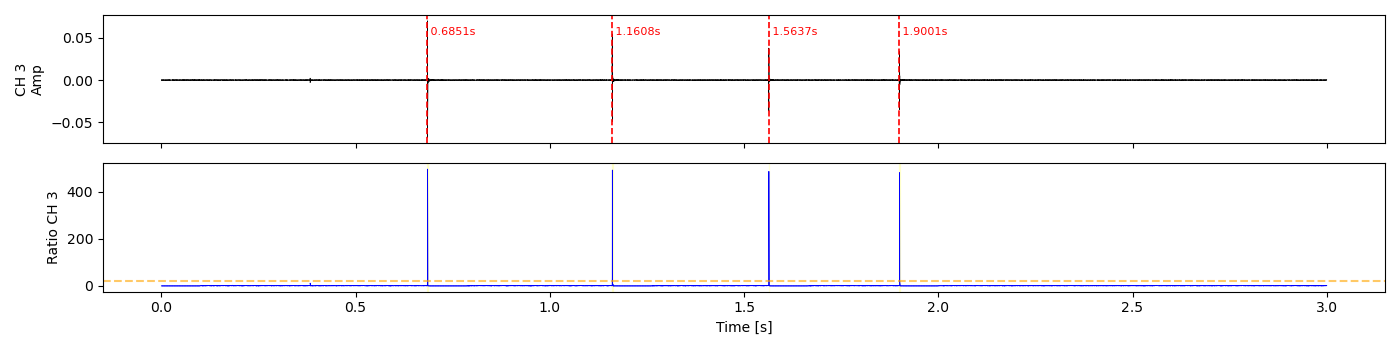


EVENTO   | TEMPO [s]    | CANALI COINVOLTI
--------------------------------------------------
000      | 0.685061   | [3]
001      | 1.160831   | [3]
002      | 1.563668   | [3]
003      | 1.900131   | [3]


In [53]:
# --- ESECUZIONE ---
# 1. Preparazione parametri e canali
my_channels = [3]

# 2. Caricamento dati (usando la tua funzione create_data_chunkB)
data_chunk = create_data_chunkB(AE_recording_path, my_channels, extract_number(dropN), float_type=float_type)

# 3. Picking (STA/LTA + AIC)
# play with sta_sec, lta_sec, thr_on, thr_off, AIC_window parameters.
raw_picks = plot_full_resolution_picking(data_chunk, fs, channel_ids=my_channels, thr_on=20) 

# 4. Associazione (Tolleranza 1ms, max un pick per canale)
final_groups = associate_picks_unique(raw_picks, channel_ids=my_channels, tolerance=0.001)

# 5. Report Finale
print("\n" + "="*50)
print(f"{'EVENTO':<8} | {'TEMPO [s]':<12} | {'CANALI COINVOLTI'}")
print("-" * 50)
for i, g in enumerate(final_groups):
    # Esempio: mostriamo solo eventi confermati da almeno 1 canale (regolabile)
    if len(g) >= 1:
        t_min = min(p['time'] for p in g)
        ch_list = sorted([p['ch'] for p in g])
        print(f"{i:03d}      | {t_min:.6f}   | {ch_list}")
print("="*50)

# Plot a zoomed in section of data

Grafico salvato con successo in: /mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/signal_sta_0.0002_lta_0.001_thr_10_aic_0.001.png


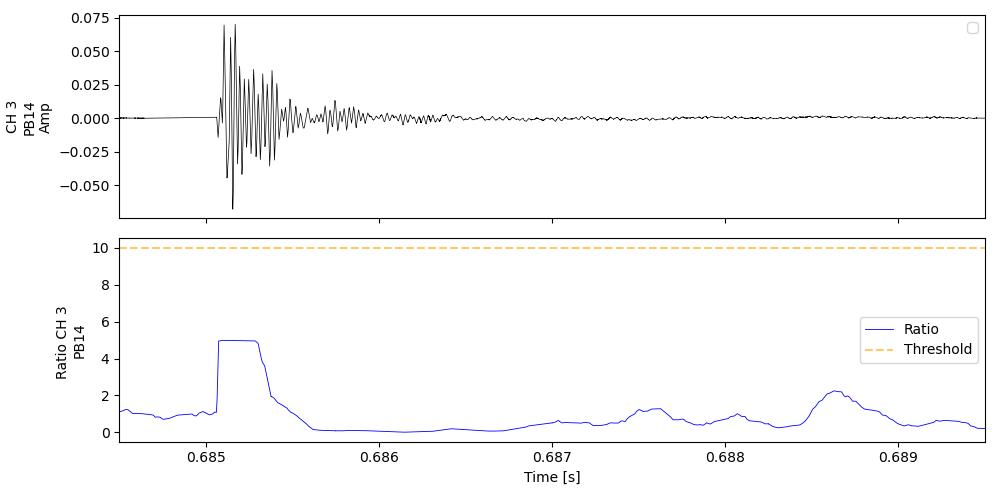

[[]]

In [69]:
def plot_data_segment(data_chunk, fs, channel_ids, sta_sec=0.0002, lta_sec=0.001, 
                      thr_on=10, thr_off=3, AIC_window=0.001, 
                      t_start=0.6845, t_end=0.6895, window_mode=True):
    """
    Performs event picking using STA/LTA and AIC refinement on the full data chunk, 
    and plots the results with a custom view window.

    Parameters
    ----------
    data_chunk : numpy.ndarray
        Input signal data with shape (n_channels, n_samples).
    fs : float
        Sampling frequency in Hz.
    channel_ids : list
        List of identifiers/labels for each channel.
    sta_sec : float, optional
        Short-Term Average window in seconds.
    lta_sec : float, optional
        Long-Term Average window in seconds.
    thr_on : float, optional
        Threshold ratio to trigger the start of an event.
    thr_off : float, optional
        Threshold ratio to de-trigger (end of event).
    AIC_window : float, optional
        Define a narrow window around the onset to pinpoint the arrival with AIC.
    t_start : float, optional
        Start time of the plot x-axis limit in seconds.
    t_end : float, optional
        End time of the plot x-axis limit in seconds.
    window_mode : bool, optional
        If True, highlights a box starting 50 points before the pick and ending 4 ms after.
    
    Returns
    -------
    all_picks : list of list
        A list containing the picked arrival times (in seconds) for each channel.
    """
    plt.style.use('fast')
    n_ch = data_chunk.shape[0]
    n_samples = data_chunk.shape[1]
    
    # Create the full time axis
    time_axis = np.linspace(0, n_samples/fs, n_samples)
    
    # Initialize subplots: 2 rows per channel (Signal + Characteristic Function)
    fig, axes = plt.subplots(n_ch * 2, 1, figsize=(10, 5 * n_ch), sharex=True)
    if n_ch == 1: 
        axes = [axes[0], axes[1]] # Handle single-channel indexing edge case
    
    all_picks = []

    for i in range(n_ch):
        trace = data_chunk[i]
        real_id = channel_ids[i]
        
        # --- STA/LTA Analysis ---
        nsta, nlta = int(sta_sec * fs), int(lta_sec * fs)
        
        cft = classic_sta_lta(trace, nsta, nlta)
        onsets = trigger_onset(cft, thr_on, thr_off)
        
        ch_picks = []
        for onset in onsets:
            win = int(AIC_window * fs) 
            idx_l, idx_h = max(0, onset[0] - win), min(n_samples, onset[0] + win)
            
            if (idx_h - idx_l) > 10:
                aic_curve = compute_aic_fast(trace[idx_l:idx_h])
                ch_picks.append((idx_l + np.argmin(aic_curve)) / fs)
        
        all_picks.append(ch_picks)

# --- Plotting: Signal Trace ---
        ax_sig = axes[i*2]
        ax_sig.plot(time_axis, trace, color='black', lw=0.5)
        
        for idx_p, p in enumerate(ch_picks):
            label_text = 'Picked arrival' if idx_p == 0 else ""
            ax_sig.axvline(p, color='red', ls='--', lw=1.2, label=label_text)
            ax_sig.text(p, ax_sig.get_ylim()[1]*0.7, f' {p:.4f}s', color='red', fontsize=8)
            
# --- Window Mode Line ---
            if window_mode:
                box_start = p - 8.3e-5             # 83 microseconds before the pick
                box_end = p + 0.004                # 4 ms (0.004s) after the pick
                
                ylim = ax_sig.get_ylim()
                y_base = ylim[0] + (ylim[1] - ylim[0]) * 0.05
                y_peak = ylim[0] + (ylim[1] - ylim[0]) * 1
                
                window_x = [box_start, box_start, box_end, box_end]
                window_y = [y_base, y_peak, y_peak, y_base]
                
                box_label = 'Extraction Window' if idx_p == 0 else ""
                ax_sig.plot(window_x, window_y, color='green', lw=1.5, label=box_label)
            
        ax_sig.set_ylabel(f"CH {real_id}\nPB14\nAmp")
        ax_sig.legend(loc='best')

        # --- Plotting: STA/LTA Ratio ---
        ax_cft = axes[i*2 + 1]
        ax_cft.plot(time_axis, cft, color='blue', lw=0.6, label='Ratio')
        ax_cft.axhline(thr_on, color='orange', ls='--', alpha=0.6, label='Threshold')
        
        for idx_o, onset in enumerate(onsets):
            span_label = 'Trigger Window' if idx_o == 0 else ""
            ax_cft.axvspan(onset[0]/fs, onset[1]/fs, color='yellow', alpha=0.15, label=span_label)
            
        ax_cft.set_ylabel(f"Ratio CH {real_id} \nPB14")
        ax_cft.legend(loc='best')

    axes[-1].set_xlabel("Time [s]")
    
# --- Set X-limits across all shared axes properly ---
    if t_start is not None or t_end is not None:
        xlim_left = t_start if t_start is not None else 0
        xlim_right = t_end if t_end is not None else n_samples / fs
        for ax in axes:
            ax.set_xlim(xlim_left, xlim_right)
            
    plt.tight_layout()

    fig.canvas.draw()
    filename = f"signal_sta_{sta_sec}_lta_{lta_sec}_thr_{thr_on}_aic_{AIC_window}.png"
    filepath = os.path.join('/mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/', filename)
    
    # Use fig.savefig instead of plt.savefig and lower dpi to prevent memory/blank export issues
    fig.savefig(filepath, format='png', dpi=300)
    print(f"Grafico salvato con successo in: {filepath}")
    
    plt.show()
    
    return all_picks

plot_data_segment(data_chunk, fs, channel_ids=my_channels) 

## Apply to all channels without plot

In [9]:
# Load all files
my_channels = list(np.arange(len(channels_names)-1) + 2)
data_chunk = create_data_chunkB(AE_recording_path, my_channels, extract_number(dropN), float_type=float_type)

# Verifica che la lunghezza corrisponda
print(f"Righe in data_chunk: {data_chunk.shape[0]}, ID in my_channels: {len(my_channels)}")

# Picking
# play with sta_sec, lta_sec, thr_on, thr_off, AIC_window parameters.
raw_picks, cfts, onsets = get_picks_only(data_chunk, fs, my_channels, thr_on=10)

# Associazione (usa la versione che usa channel_ids[i])
final_groups = associate_picks_unique(raw_picks, channel_ids=my_channels, tolerance=0.001)
# 4. Report Testuale (Immediato)


print(f"\nTotale eventi salvati: {len(final_groups)}")

print(f"\n{'EVENTO':<8} | {'TEMPO [s]':<12} | {'CANALI'}")
print("-" * 40)
for i, g in enumerate(final_groups):
    if len(g) >= 1:
        print(f"{i:03d}      | {min(p['time'] for p in g):.6f}   | {[p['ch'] for p in g]}")

Righe in data_chunk: 25, ID in my_channels: 25


KeyboardInterrupt: 

# Picking process/plotting/save output/load output

In [ ]:
def output(folder_path, material, block, position, size, dropN, sta_sec, lta_sec, thr_on, thr_off, AIC_window):
    """
    Runs the automatic arrival-time picking on ball-drop acoustic emission (AE)
    recordings, keeps only the events that are spatially/temporally coherent across
    channels, reorganises the data by event, and produces diagnostic plots.

    Processing outline:
        1. Build the data path and load the acquisition metadata.
        2. Load the raw multichannel data and pick arrival times on every channel
           (STA/LTA trigger refined by an AIC picker).
        3. Associate the single-channel picks into unique events (picks falling
           within a short time tolerance of each other belong to the same event).
        4. For every channel and every event, clip a time window around the arrival
           and extract amplitude/timing features.
        5. Invert the nesting of the results so they are indexed by event first.
        6. Plot every event, one panel per channel.

    INPUT PARAMETERS:
    ----------------
    folder_path : str
        Root directory containing the acquisition data.
    material : str
        Name of the material of the block under analysis (e.g. 'PMMA'); used to
        rebuild the directory path.
    block : str
        Identifier of the specific block (e.g. 'Lower_block' or 'Upper_block').
    position : str
        String with the spatial coordinates of the release point
        (e.g. '[48.8, 0, 1]'); used to rebuild the directory path.
    size : str or int
        Size/diameter of the ball used in the ball-drop test (e.g. '3'); also used
        to rebuild the path and to select the plot amplitude limits.
    dropN : str
        Sequential identifier of the specific drop to analyse (e.g. 'drop_5').
    sta_sec : float or dict
        Short-Term Average (STA) window length in seconds. Either a single float
        applied to all channels, or a per-channel dict {'CH': val, 'DEFAULT': val}.
    lta_sec : float or dict
        Long-Term Average (LTA) window length in seconds. Either a single float or a
        per-channel dict {'CH': val, 'DEFAULT': val}.
    thr_on : float or dict
        STA/LTA ratio above which the trigger is switched ON. Either a single number
        or a per-channel dict {'CH': val, 'DEFAULT': val}.
    thr_off : float or dict
        STA/LTA ratio below which the trigger is switched OFF. Either a single number
        or a per-channel dict {'CH': val, 'DEFAULT': val}.
    AIC_window : float or dict
        Width in seconds of the window used by the Akaike Information Criterion (AIC)
        picker to refine the onset time. Either a single float or a per-channel dict
        {'CH': val, 'DEFAULT': val}.

    OUTPUT PARAMETERS:
    -----------------
    drops : dict
        Nested dictionary organised by event:
        {event_id: {channel_name: {signal_features}}}.
        Each feature dict contains the arrival times and amplitudes, the first-peak
        amplitude/time, the maximum amplitude/time, and the clipped time axis and
        waveform ('time', 'trace').
    parameters : dict
        Dictionary with the picking parameters actually used (for traceability) and,
        under the key 'events_summary', a per-event statistical summary (strongest
        channel, earliest channel and their first-peak amplitudes).
        If no event is detected, an empty dict and the parameters are returned.
    """
    # ==========================================
    # 1. PATH CONSTRUCTION AND METADATA LOADING
    # ==========================================
    # Build the path to the recording folder: <root>/<material>/<block>/ball_drop_<size>_<position>/<drop>/
    AE_recording_path = os.path.join(folder_path, material, block)
    POSPATH = 'ball_drop_' + str(size) + '_' + position
    AE_recording_path = os.path.join(AE_recording_path, POSPATH, dropN) + '/'
    print('You are working with Data from: ', AE_recording_path)
    
    # Locate the metadata text file in the folder (the first file whose name contains 'metadata')
    # and read the acquisition info: sampling frequency, chunk size, data type, channel names.
    metadata_file = [file for file in id_names_txt(AE_recording_path) if 'metadata' in file][0] + '.txt'
    fs, f_chunk, float_type, channels_names, info_data = loading_infoB(AE_recording_path, metadata_file, verbose=True)

    # ==========================================
    # 2. DATA LOADING AND PICKING ALGORITHM
    # ==========================================
    # Column indices of the data channels in the raw file. They start at 2 and there is one
    # fewer than the entries in channels_names, because the first entry of channels_names is
    # not a sensor channel (it is skipped below with channels_names[1:]).
    my_channels = list(np.arange(len(channels_names) - 1) + 2)
    # Load the multichannel waveform matrix (rows = channels, columns = time samples) for the selected drop.
    data_chunk = create_data_chunkB(AE_recording_path, my_channels, extract_number(dropN), float_type=float_type)
    
    # Names of the sensor channels, in the same order as the rows of data_chunk.
    chnameidx = list(channels_names[1:])
    
    # Run the automatic arrival-time picking algorithm on every channel.
    # get_picks_only internally resolves the parameters whether they are single floats or
    # per-channel dicts. It returns the raw picks, the characteristic functions (cfts) and the onsets.
    raw_picks, cfts, onsets = get_picks_only(
        data_chunk, fs, channel_ids=chnameidx, sta_sec=sta_sec, lta_sec=lta_sec, 
        thr_on=thr_on, thr_off=thr_off, AIC_window=AIC_window
    )
    
    # Group the single-channel picks into unique events: picks from different channels
    # whose arrival times differ by less than `tolerance` (seconds, here 1 ms) are assigned
    # to the same event.
    final_groups = associate_picks_unique(raw_picks, channel_ids=my_channels, tolerance=0.001)
    
    # eventi: {event_id: global first arrival time (earliest pick of the event)}
    eventi = {} 
    # eventi_canali: {event_id: {channel_name: pick time on that channel}}
    eventi_canali = {} 
    # earliest_channels_dict: {event_id: [names of the channel(s) that picked the earliest arrival]}
    earliest_channels_dict = {} 
    # Progressive counter used to renumber the events that pass the coherence filter (0, 1, 2, ...)
    id_evento_sequenziale = 0 

    for g in final_groups:
        # Coherence filter: a group of picks is accepted as a REAL event only if it was
        # detected on at least 2 channels (len(g) >= 2). Isolated single-channel picks are
        # discarded as noise. (This minimum number of channels can be raised to be stricter.)
        if len(g) >= 2:
            tempi_gruppo = [p['time'] for p in g]
            # Global first arrival of the event = earliest pick among all channels in the group
            pick_globale = min(tempi_gruppo)
            eventi[id_evento_sequenziale] = pick_globale
            
            eventi_canali[id_evento_sequenziale] = {}
            canali_primissimo_arrivo = []
            
            for pick_info in g:
                # 'ch' is the channel column index; convert it to the channel name
                ch_idx = pick_info['ch']
                try:
                    array_idx = my_channels.index(ch_idx)
                    ch_name = chnameidx[array_idx]
                    eventi_canali[id_evento_sequenziale][ch_name] = pick_info['time']
                    
                    # Keep track of the channel(s) whose pick coincides with the global first arrival
                    if pick_info['time'] == pick_globale:
                        canali_primissimo_arrivo.append(ch_name)
                except ValueError:
                    # Channel index not in my_channels: ignore this pick
                    pass
            
            earliest_channels_dict[id_evento_sequenziale] = canali_primissimo_arrivo
            id_evento_sequenziale += 1 

    # Store the picking parameters that were used, for traceability of the analysis
    parameters = {
        'sta_sec': sta_sec,
        'lta_sec': lta_sec,
        'thr_on': thr_on,
        'thr_off': thr_off,
        'AIC': AIC_window,
    }

    # If no group passed the coherence filter, stop here and return an empty result
    if len(eventi) == 0:
        print('Nessun evento rilevato con i parametri attuali. Ritorno dizionario vuoto.')
        return {}, parameters
            
    # ==========================================
    # 3. CLIPPING WINDOW SETTINGS
    # ==========================================
    # window: time (s) kept BEFORE the global first arrival of the event.
    window = 8.3e-5 
    # tail: time (s) kept AFTER the last channel pick of the event, so the coda is included.
    tail = 0.003916  
    # Number of time samples per channel and the corresponding time axis (s), common to all channels
    n_samples = data_chunk.shape[1]
    time_axis = np.linspace(0, n_samples / fs, n_samples)

    # trace: {channel index: full waveform of that channel}
    trace = {}
    for a in range(len(my_channels)):
        trace[a] = data_chunk[a]

    # ==========================================
    # 4. PER-CHANNEL SIGNAL FEATURE EXTRACTION
    # ==========================================
    # temp: {channel_name: {event_id: features}} (inverted into `drops` in section 5)
    temp = {}
    # first_amps_per_evento: {event_id: {channel_name: first-peak amplitude}}, used for the event summary
    first_amps_per_evento = {k: {} for k in eventi.keys()}

    for b, chname in enumerate(chnameidx):
        # clip: {event_id: features} for the current channel
        clip = {}
        for idx, (k, value) in enumerate(eventi.items()):
            pick_globale = value  
            
            # Pick time of this specific channel for this event; NaN if the channel
            # did not detect the event.
            if chname in eventi_canali[k]:
                pick_canale = eventi_canali[k][chname]
            else:
                pick_canale = np.nan  
                
            # Start of the clip: a short window before the global first arrival
            tstart = pick_globale - window
            
            # End of the clip: the latest pick among all channels of the event plus the tail,
            # so that the clip covers the arrival at the farthest sensor and its coda.
            tempi_effettivi_gruppo = list(eventi_canali[k].values())
            ultimo_pick = max(tempi_effettivi_gruppo) if tempi_effettivi_gruppo else pick_globale
            tend = ultimo_pick + tail
            
            # Extract the time and amplitude samples inside [tstart, tend]
            mask = (time_axis >= tstart) & (time_axis <= tend)
            timeclip = time_axis[mask]
            ampclip = trace[b][mask]
            
            # Amplitude of the waveform at the global first arrival time
            # (sample of the clip closest to pick_globale; 0 if the clip is empty)
            idx_primo_arrivo_globale = np.abs(timeclip - pick_globale).argmin()
            ampiezze_p_a_g = ampclip[idx_primo_arrivo_globale] if len(ampclip) > 0 else 0
            
            # Amplitude of the waveform at this channel's own pick time
            # (0 if the channel has no pick or the clip is empty)
            idx_primo_arrivo_canale = np.abs(timeclip - pick_canale).argmin() if not np.isnan(pick_canale) else 0
            ampiezze_p_a_c = ampclip[idx_primo_arrivo_canale] if (len(ampclip) > 0 and not np.isnan(pick_canale)) else 0
            
            # Maximum (signed) amplitude in the clip and its sample index
            ampeak = ampclip.max() if len(ampclip) > 0 else 0
            ampeakidx = ampclip.argmax() if len(ampclip) > 0 else 0
            
            #if int(size) == 3:
            #else:
            #    soglia_rumore = 0.01
            #else:
            # Noise threshold used as the minimum peak prominence (same units as the trace).
            # The channel PBB4 uses a higher threshold (0.005) than all the others (0.001).
            soglia_rumore = 0.005 if chname == 'PBB4' else 0.001
                
            # Find the peaks of the absolute waveform that stand out from the noise by at least
            # the prominence threshold; the FIRST such peak is taken as the first significant
            # amplitude (first motion) of the event on this channel.
            segno_modulo = np.abs(ampclip)
            indices, _ = find_peaks(segno_modulo, prominence=soglia_rumore)

            if len(indices) > 0:
                primo_picco_idx = indices[0]
                # Signed amplitude (not absolute value) of the waveform at the first peak, and its time
                firstmax = ampclip[primo_picco_idx]
                tempo_primo_picco = timeclip[primo_picco_idx] 
            else:
                # No peak above the noise threshold: amplitude set to 0 and time to NaN
                firstmax = 0.0
                tempo_primo_picco = np.nan 

            first_amps_per_evento[k][chname] = firstmax

            # Collect all the features of this channel/event pair
            clip[k] = {
                'global_first_arrival': pick_globale,              # earliest pick of the event over all channels [s]
                'arrival_amplitude': ampiezze_p_a_g,               # amplitude of this channel at the global first arrival
                'channel_specific_arrival': pick_canale,           # this channel's own pick time [s] (NaN if none)
                'channel_arrival_amplitude': ampiezze_p_a_c,       # amplitude at this channel's own pick time
                'first_amp': firstmax,                             # amplitude of the first peak above the noise threshold
                'first_peak_time': tempo_primo_picco,              # time of that first peak [s] (NaN if none)
                'peak_amplitude': ampeak,                          # maximum amplitude within the clip
                'peak_time': timeclip[ampeakidx] if len(ampclip) > 0 else np.nan,  # time of the maximum amplitude [s]
                'time': timeclip,                                  # time axis of the clipped waveform [s]
                'trace': ampclip,                                  # clipped waveform
            }
                
        temp[chname] = clip
        
    # Per-event summary: strongest channel and earliest channel, with their first-peak amplitudes
    parameters['events_summary'] = {}
    for k in eventi.keys():
        canali_evento_corrente = first_amps_per_evento[k]
        
        # Channel(s) with the largest first-peak amplitude. If several channels share the same
        # maximum, the list of all of them is returned instead of a single name.
        if canali_evento_corrente:
            max_first_amp = max(canali_evento_corrente.values())
            max_channels = [ch for ch, amp in canali_evento_corrente.items() if amp == max_first_amp]
            max_ch_output = max_channels[0] if len(max_channels) == 1 else max_channels
        else:
            max_first_amp = 0.0
            max_ch_output = "Unknown"
            
        # Channel(s) that recorded the earliest arrival of the event, and that arrival time
        earliest_ch_list = earliest_channels_dict.get(k, [])
        earliest_ch_time = eventi[k] 
        
        # First-peak amplitude(s) of the earliest channel(s); as above, a single value if there
        # is one earliest channel, otherwise a list (one entry per channel).
        if earliest_ch_list:
            earliest_ch_first_amp_list = [canali_evento_corrente.get(ch, 0.0) for ch in earliest_ch_list]
            earliest_ch_first_amp = earliest_ch_first_amp_list[0] if len(earliest_ch_first_amp_list) == 1 else earliest_ch_first_amp_list
            earliest_ch_output = earliest_ch_list[0] if len(earliest_ch_list) == 1 else earliest_ch_list
        else:
            earliest_ch_output = "Unknown"
            earliest_ch_first_amp = 0.0

        parameters['events_summary'][k] = {
            'max_first_amp_event': max_first_amp,              # largest first-peak amplitude among the channels
            'max_first_amp_channel': max_ch_output,            # channel(s) where that maximum occurs
            'earliest_channel': earliest_ch_output,            # channel(s) with the earliest arrival
            'earliest_channel_time': earliest_ch_time,         # time of the earliest arrival [s]
            'earliest_channel_first_amp': earliest_ch_first_amp  # first-peak amplitude on the earliest channel(s)
        }

    # ==========================================
    # 5. DICTIONARY INVERSION (drops)
    # ==========================================
    # Invert the nesting from {channel: {event: features}} to {event: {channel: features}},
    # so that the data can be accessed event by event. Only channels that contain the event are kept.
    if temp and next(iter(temp.values())):
        # Event ids, taken from the first channel
        key = next(iter(temp.values())).keys()
        drops = {
            intid: {
                extid: temp[extid][intid]
                for extid in temp
                if intid in temp[extid]
            }
            for intid in key
        }
    else:
        drops = {}

    # ==========================================
    # 6. MULTI-PANEL PLOT GENERATION
    # ==========================================
    # One figure per event, with one panel per channel
    for c in eventi.keys():
        # Subplot grid: 2 rows if there are up to 10 channels, otherwise 5 rows
        if len(chnameidx) <= 10:
            f, axes = plt.subplots(2, math.ceil(len(chnameidx) / 2), figsize=(16, 5))
        else:
            f, axes = plt.subplots(5, math.ceil(len(chnameidx) / 5), figsize=(24, 8))
            
        # Flatten the axes array so that the panels can be indexed with a single integer
        # (with one channel, plt.subplots returns a single Axes object, not an array)
        axes_flat = [axes] if len(chnameidx) == 1 else axes.flatten()

        for d, chname in enumerate(chnameidx):
            ax = axes_flat[d]
            # Clipped waveform of this channel for the current event
            ax.plot(drops[c][chname]['time'], drops[c][chname]['trace'], color='k')
            
            t_arrivo = drops[c][chname]['global_first_arrival']
            amp_arrivo = drops[c][chname]['arrival_amplitude']
            t_canale = drops[c][chname]['channel_specific_arrival']
            amp_canale = drops[c][chname]['channel_arrival_amplitude']
            
            # Red dot: global first arrival of the event (earliest pick over all channels)
            ax.plot(t_arrivo, amp_arrivo, 'ro', markersize=5, label='Inizio Evento Globale')
            # Blue star: this channel's own pick (only if the channel detected the event)
            if not np.isnan(t_canale):
                ax.plot(t_canale, amp_canale, 'b*', markersize=7, label='Pick Specifico Canale')
            
            # Red vertical line: time of the first peak above the noise threshold (if any)
            if not np.isnan(drops[c][chname]['first_peak_time']):
                ax.axvline(drops[c][chname]['first_peak_time'], c='red')
                
            ax.set_ylabel(f'Trace {chname}')
            ax.set_xlabel('Time [s]')
            # Fixed amplitude range for readability: wider for the 3 mm ball, narrower otherwise
            if int(size) == 3:
                ax.set_ylim(-0.08, 0.08)
            else:
                ax.set_ylim(-0.05, 0.05)
            ax.grid(True)
            ax.legend(loc='upper right', fontsize='small') 
        plt.tight_layout()
        plt.show()

        # Remove the unused empty panels of the grid
        for j in range(len(chnameidx), len(axes_flat)):
            f.delaxes(axes_flat[j])

    return drops, parameters


def saveoutput(drops, metadata, base_folder, position, size, dropN):
    """
    Saves the `drops` data in binary format (pickle) and the related metadata in a
    plain-text (.txt) file.

    INPUT PARAMETERS:
    ----------------
    drops : dict
        Structured dictionary with the signal features and clipped waveforms generated
        by `output()`.
    metadata : dict
        Dictionary of global experiment metadata to be written in text format
        (one 'key:value' line per entry, after a 'metadati' header line).
    base_folder : str
        Path of the main destination folder on disk.
    position : str
        String with the spatial position (e.g. '[48.8, 0, 1]').
    size : str
        Ball size/diameter (e.g. '3').
    dropN : str
        Sequential identifier of the drop (e.g. 'drop_5').

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function writes directly to disk (a .bin and a .txt file) and returns nothing.
        Files are saved in <base_folder>/data_ball_drop_<size>_<position>/<dropN>/.
    """
    # Build the destination folder from the ball size, the spatial position and the drop number
    folder_pos_size = f'data_ball_drop_{size}_{position}'
    target_folder = os.path.join(base_folder, folder_pos_size, dropN)
    # Create the folder on disk if it does not exist yet (avoids write errors)
    os.makedirs(target_folder, exist_ok=True)
    print(f'Struttura cartelle verificata/creata in: {target_folder}')

    # Names of the two output files: .bin for the Python object, .txt for the human-readable metadata
    namebin = os.path.join(target_folder, f'{position}_{size}_{dropN}.bin')
    nametxt = os.path.join(target_folder, f'{position}_{size}_{dropN}.txt')

    # Serialise the nested `drops` dictionary with pickle. The binary format preserves the
    # NumPy arrays and the dictionary structure exactly and is fast to reload.
    with open(namebin, 'wb') as file_bin:
        pickle.dump(drops, file_bin)
    print(f'Clip salvate in binario su {namebin}')
    
    # Write the ASCII text file with the metadata (and the operating parameters of the test):
    # a header line followed by one 'key:value' line per entry.
    with open(nametxt, "w", encoding="utf-8") as file_txt:
        file_txt.write('metadati\n')
        for chiave, valore in metadata.items():
            file_txt.write(f'{chiave}:{valore}\n')
    print(f'Metadati salvati su {nametxt}')


def loadoutput(directory, position, size, dropN):
    """
    Loads the files written by `saveoutput` and `saveloc` and returns the `drops`
    dictionary together with the metadata and the localization results.

    INPUT PARAMETERS:
    ----------------
    directory : str
        Main folder in which the saved ball-drop data folders are stored
        (the same path given as `base_folder` to `saveoutput` / `saveloc`).
    position : str
        Descriptive string of the geometric position of the test (e.g. '[48.8, 0, 1]').
    size : str
        Ball size associated with the files to load (e.g. '3').
    dropN : str
        Name of the folder of the specific drop (e.g. 'drop_5').

    OUTPUT PARAMETERS:
    -----------------
    drops : dict
        The restored dictionary of signals and the related picks.
    metadata : dict
        Metadata dictionary rebuilt with native Python types (float, list, str).
    localization : dict
        Localization dictionary rebuilt with native Python types (float, list, str).

    Raises:
    ------
    FileNotFoundError
        If any of the three required files (.bin, metadata .txt, localization .txt)
        is missing from the target folder.
    """
    # Rebuild the folder and file paths using the same naming convention as the saving functions
    folder_pos_size = f'data_ball_drop_{size}_{position}'
    target_folder = os.path.join(directory, folder_pos_size, dropN)
    
    namebin = os.path.join(target_folder, f'{position}_{size}_{dropN}.bin')
    nametxt = os.path.join(target_folder, f'{position}_{size}_{dropN}.txt')
    loctxt = os.path.join(target_folder, f'localization_{position}_{size}_{dropN}.txt')
    
    # Integrity check: all three required files must exist
    missing_files = [f for f in [namebin, nametxt, loctxt] if not os.path.exists(f)]
    if missing_files:
        raise FileNotFoundError(f"Impossibile trovare i file richiesti in: {target_folder}")
        
    # Deserialise the binary file
    with open(namebin, 'rb') as file_bin:
        payload = pickle.load(file_bin)
    
    # Backward compatibility: older files may store a 2-element tuple whose first item is `drops`;
    # in that case take the first element, otherwise use the loaded object as is.
    drops = payload[0] if isinstance(payload, tuple) and len(payload) == 2 else payload
    print('Dati binari ripristinati correttamente.')
    
    # Internal helper that parses a 'key:value' text file into a dictionary (avoids duplicating the parsing)
    def parse_txt_to_dict(filepath):
        data = {}
        with open(filepath, 'r', encoding='utf-8') as file_txt:
            linee = file_txt.readlines()
            # Skip the first line (the header: 'metadati' or 'localization')
            for linea in linee[1:]:
                linea = linea.strip()
                if ":" in linea:
                    # Split only at the first ':' so that values may themselves contain colons
                    chiave, valore = linea.split(":", 1)
                    if valore.startswith('[') and valore.endswith(']'):
                        # Value written as a list: split it into elements and strip spaces and quotes
                        elementi = valore[1:-1].split(',')
                        data[chiave] = [el.strip().replace("'", "").replace('"', '') for el in elementi if el.strip()]
                    else:
                        # Try to convert the value to float; otherwise keep it as a string
                        try:
                            data[chiave] = float(valore)
                        except ValueError:
                            data[chiave] = valore
        return data

    metadata = parse_txt_to_dict(nametxt)
    localization = parse_txt_to_dict(loctxt)
    
    return drops, metadata, localization

def plot_picks_together_sep(drops, parameters, position, drop, size, sort_by='channel', colormap_name='viridis', output_dir='.', skipped_channels=None):
    """
    Generates a waterfall plot for the first available event.
    The traces are separated by a fixed vertical offset so that each one is distinct,
    and they are sorted either in a fixed sensor order or by arrival time. Time is on
    the X axis and amplitude on the Y axis (positive values point upwards).
    The figure is saved as a PNG file and then displayed.

    INPUT PARAMETERS:
    ----------------
    drops : dict
        Sensor data dictionary, either for a single event ({channel: features}) or for
        multiple events ({event_id: {channel: features}}). Only the first event is plotted.
    parameters : dict
        Configuration dictionary. The optional key 'ignored_channels' lists channels to
        exclude from the plot.
    position, drop, size :
        Metadata used in the plot title and in the name of the saved file.
    sort_by : str
        'channel' (fixed sensor order, defined inside the function) or
        'arrival_time' (ascending channel-specific arrival time; channels without a
        pick are placed last).
    colormap_name : str
        Name of the matplotlib colormap applied to the traces (e.g. 'viridis', 'tab20', 'plasma').
    output_dir : str
        Path of the destination folder in which the image is saved (created if missing).
    skipped_channels : list, tuple, set or str, optional
        Channels to exclude manually from the plot, in addition to those listed in
        parameters['ignored_channels'].

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function saves '<output_dir>/pos_<position>_size_<size>_drop_<drop>_arrivals.png'
        (300 dpi) and shows the figure; it returns nothing.

    Plot markers:
        Star   : pick time of the channel (channel-specific arrival).
        Circle : first peak above the noise threshold.
        Dotted horizontal line : zero-amplitude baseline of each trace.
    """
    # Nothing to plot if the dictionary is empty
    if not drops:
        print("Dizionario 'drops' vuoto. Impossibile generare il grafico.")
        return

    # Merge the channels ignored via `parameters` with those excluded manually,
    # removing duplicates (via set).
    ignored_channels = list(parameters.get('ignored_channels', []))
    if skipped_channels:
        if isinstance(skipped_channels, (list, tuple, set)):
            ignored_channels.extend(list(skipped_channels))
        else:
            ignored_channels.append(skipped_channels)
    ignored_channels = list(set(ignored_channels))
    
    # 1. DEFINITION OF THE FIXED SENSOR ORDER
    # Order in which the sensors are stacked in the plot when sort_by='channel'.
    ordine_sensori_fisso = [
        "PUF11", "PUF12", "PUF13", "PUF14", "PUB11", "PUB12",
        "PB11", "PB12", "PB13", "PB14", "PB15", "PB16", "PB17",
        "PB21", "PB22", "PB23", "PB24", "PB25", "PB26", "PB27",
        "PB31", "PB32", "PB33", "PB34", "PB35", "PB36", "PB37",
        "PBB1", "PBB2", "PBB3", "PBB4"
    ]

    # --- INPUT NORMALISATION (single-event or multi-event input) ---
    # Heuristic: if the first key of `drops` is a sensor name (starts with 'P' or 'S'),
    # then `drops` is a single event {channel: features}; otherwise it is a
    # multi-event dict {event_id: {channel: features}}.
    is_single_event = False
    if isinstance(drops, dict) and len(drops) > 0:
        prima_chiave = list(drops.keys())[0]
        if isinstance(prima_chiave, str):
            chiave_pulita = prima_chiave.strip().upper()
            if chiave_pulita.startswith("P") or chiave_pulita.startswith("S"):
                is_single_event = True

    # Wrap a single event in a dict so that both cases are handled by the same loop below
    if is_single_event:
        dataset_elaborabile = {"Singolo Evento": drops}
    else:
        dataset_elaborabile = drops

    # Fixed vertical offset between consecutive traces (same units as the amplitude)
    offset_spaziatura = 0.03

    # Make sure the destination folder exists
    if output_dir and not os.path.exists(output_dir):
        os.makedirs(output_dir, exist_ok=True)

    # Plotting loop (only the first event is processed, then the loop stops)
    for id_evento, canali_dati in dataset_elaborabile.items():
        # 2. COLLECTION AND FILTERING OF THE VALID CHANNELS
        # Keep only the channels that are not in the ignore list
        valid_channels = []
        for chname, ch_data in canali_dati.items():
            if chname not in ignored_channels:
                valid_channels.append((chname, ch_data))

        # 3. SORTING (by channel or by arrival time)
        if sort_by == 'arrival_time':
            # Sort by channel-specific arrival time; channels with no pick (NaN) go last
            def get_arrival(item):
                t = item[1].get('channel_specific_arrival', np.nan)
                return t if not np.isnan(t) else float('inf')
            canali_ordinati = sorted(valid_channels, key=get_arrival)
        else:
            # Follow the fixed sensor order. Channels not present in the fixed list are also
            # appended (once each, thanks to the `not in canali_ordinati` check) so that they
            # are not lost; note that this happens inside the loop, so they are inserted right
            # after the first fixed-order sensor rather than at the end of the list.
            canali_ordinati = []
            for chname in ordine_sensori_fisso:
                match = next((item for item in valid_channels if item[0] == chname), None)
                if match:
                    canali_ordinati.append(match)
                for item in valid_channels:
                    if item[0] not in ordine_sensori_fisso and item not in canali_ordinati:
                        canali_ordinati.append(item)

        # posizioni_canali: {channel_name: vertical offset}, used later for the Y-axis tick labels
        posizioni_canali = {}
        num_canali = len(canali_ordinati)

        # Scale the figure height with the number of channels to avoid squeezing the traces
        fig_height = max(9.0, num_canali * 0.3)
        plt.figure(figsize=(14, fig_height))

        # Initialise the chosen colormap
        cmap = plt.get_cmap(colormap_name)

        # 4. APPLICATION OF THE OFFSET AND DRAWING OF THE TRACES
        for i, (chname, ch_data) in enumerate(canali_ordinati):
            # The first channel in the list gets the largest offset, so it is drawn at the top
            current_offset = (num_canali - 1 - i) * offset_spaziatura
            posizioni_canali[chname] = current_offset
            
            # Features of this channel (without offset)
            t_canale = ch_data.get('channel_specific_arrival', np.nan)
            amp_canale_pura = ch_data.get('channel_arrival_amplitude', 0)
            first_amp = ch_data.get('first_amp', 0)
            first_amp_time = ch_data.get('first_peak_time', np.nan)
            
            # Shift the waveform and the marker amplitude by the vertical offset of the channel
            traccia_con_offset = ch_data['trace'] + current_offset
            amp_canale_con_offset = amp_canale_pura + current_offset
            
            # Colour of this trace, sampled evenly along the colormap
            color = cmap(i / max(1, num_canali - 1)) if num_canali > 1 else cmap(0.5)
            
            # Dotted baseline marking the zero level of the trace
            plt.axhline(y=current_offset, color=color, linestyle=':', alpha=0.4)
            # Waveform (limited to the first 10000 samples of the clip)
            plt.plot(ch_data['time'][:10000], traccia_con_offset[:10000], color=color, alpha=0.8, label=chname)
            
            # Star: arrival pick of this channel (if present)
            if not np.isnan(t_canale):
                plt.scatter(t_canale, amp_canale_con_offset, color=color, marker='*', s=150, edgecolors='k', zorder=5)

            # Circle: first peak above the noise threshold (if present)
            if not np.isnan(first_amp_time):
                plt.scatter(first_amp_time, first_amp + current_offset, color=color, marker='o', s=50, edgecolors='k', zorder=5)

        # 5. AXES CONFIGURATION
        plt.title(f"Ball drop: Size {size} mm; Position {position} {drop}", fontsize=14, fontweight='bold')
        plt.xlabel("Time [s]", fontsize=12)
        plt.ylabel("Channels (Amplitude + Offset)", fontsize=12)
        
        # Replace the numeric Y ticks with the channel names at their offsets
        plt.yticks(list(posizioni_canali.values()), list(posizioni_canali.keys()))
        
        # Extended upper margin so that the topmost trace is not cut off
        if canali_ordinati:
            plt.ylim(-offset_spaziatura * 0.5, (num_canali * offset_spaziatura) + (offset_spaziatura * 0.5))
        
        plt.grid(True, axis='x', linestyle='--', alpha=0.5) 
        plt.tight_layout()

        # 6. SAVING THE IMAGE AS A 300 DPI PNG IN THE TARGET FOLDER
        # Sanitise the metadata strings so they are safe to use in a file name
        safe_position = str(position).replace("/", "_").replace(" ", "_")
        safe_size = str(size).replace("/", "_").replace(" ", "_")
        safe_drop = str(drop).replace("/", "_").replace(" ", "_")
        
        filename = f"pos_{safe_position}_size_{safe_size}_drop_{safe_drop}_arrivals.png"
        filepath = os.path.join(output_dir, filename)
        
        plt.savefig(filepath, format='png', dpi=300, bbox_inches='tight')
        print(f"Grafico salvato con successo in: {filepath}")

        plt.show()
        plt.close()
        
        # Stop after the first event has been processed
        break
    
def saveloc(localization, base_folder, position, size, dropN):
    """
    Saves the localization dictionary in a .txt file inside the dedicated drop folder.

    INPUT PARAMETERS:
    ----------------
    localization : dict
        Dictionary with the localization results of the drop (written as one
        'key:value' line per entry, after a 'localization' header line).
    base_folder : str
        Path of the main destination folder on disk.
    position : str
        String with the spatial position (e.g. '[48.8, 0, 1]').
    size : str
        Ball size/diameter (e.g. '3').
    dropN : str
        Sequential identifier of the drop (e.g. 'drop_5').

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function writes directly to disk (a .txt file named
        'localization_<position>_<size>_<dropN>.txt') and returns nothing.
        The file can be read back with `loadoutput`.
    """
    # Build the destination folder from the ball size, the spatial position and the drop number
    folder_pos_size = f'data_ball_drop_{size}_{position}'
    target_folder = os.path.join(base_folder, folder_pos_size, dropN)
    # Create the folder on disk if it does not exist yet (avoids write errors)
    os.makedirs(target_folder, exist_ok=True)
    print(f'Struttura cartelle verificata/creata in: {target_folder}')

    # Name of the output file for the localization data
    nametxt = os.path.join(target_folder, f'localization_{position}_{size}_{dropN}.txt')
    
    # Write the ASCII text file with the localization data: a header line followed by one 'key:value' line per entry
    with open(nametxt, "w", encoding="utf-8") as file_txt:
        file_txt.write('localization\n')
        for chiave, valore in localization.items():
            file_txt.write(f'{chiave}:{valore}\n')
    print(f'Localizzazione salvata su {nametxt}')

# Data loading
- Function loadoutput takes directory, position, size and dropN arguments
- Returns arrival and amplitude data, picking parameters and localization
- Relevant data: Channel_arrival_amplitude, channel_specific_arrival

In [66]:
directory = '/home/oreios/Calibrations/pzt_calibration_alessia/Lower_block_results'
position = '[37.6, 0, 7.5]'
size = '3'
dropN = 'drop_1'

dropdata_caricato, parameters_caricati, localization_caricata = loadoutput(directory, position, size, dropN)
print(dropdata_caricato) # picking
print(parameters_caricati)
print(localization_caricata)

Dati binari ripristinati correttamente.
{'PB28': {'global_first_arrival': 0.68506112, 'arrival_amplitude': -9.191036224365234e-05, 'channel_specific_arrival': 0.6851568, 'channel_arrival_amplitude': -0.0004105567932128906, 'first_amp': -0.0012989044189453125, 'first_peak_time': 0.6851656365421673, 'peak_amplitude': 0.007732391357421875, 'peak_time': 0.685485636559234, 'time': array([0.68497828, 0.68497844, 0.6849786 , ..., 0.68907748, 0.68907764,
       0.6890778 ]), 'trace': array([-0.00010419, -0.0001471 , -0.00014091, ..., -0.00024509,
       -0.00022054, -0.00018382])}, 'PB14': {'global_first_arrival': 0.68506112, 'arrival_amplitude': 0.0005373954772949219, 'channel_specific_arrival': 0.68506112, 'channel_arrival_amplitude': 0.0005373954772949219, 'first_amp': -0.01433563232421875, 'first_peak_time': 0.685070756537107, 'peak_amplitude': 0.07012939453125, 'peak_time': 0.6851693165423636, 'time': array([0.68497828, 0.68497844, 0.6849786 , ..., 0.68907748, 0.68907764,
       0.6890778

# Output section
## Picking

In [33]:
folder_path = '/mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/'
block = 'Upper_block'       # Seleziona l'oggetto dell'analisi: 'Lower_block' (blocco inf.) o 'Upper_block' (blocco sup.)
position = '[17, 0, 13]'  # Coordinate spaziali [X, Y, Z] in cm dove è avvenuto il drop (sorgente dell'evento)
size = '3'                  # Parametro dimensionale associato al test eseguito (es. diametro o tipo di sorgente)
dropN = 'drop_1'            # Identificativo specifico del drop (lancio/evento ripetuto) da analizzare
material = 'PMMA'   

sta_config = {'DEFAULT': 0.001}
lta_config = {'DEFAULT': 0.005}
#threshold = {'PB14': 100, 'PB15': 100, 'PB16': 100, 'PB24': 100, 'PB26': 100, 'PB27': 100, 'PB28': 100, 'PB31': 2.5, 'PB33': 2.5, 'PB34': 100, 'PB35': 100, 'PB36': 100, 'PB37': 100, 'DEFAULT': 2.5}
#threshold = {'PB12': 2.5, 'PB13': 2.5, 'PB16': 100, 'PB17': 100, 'PB26': 2, 'PB27': 100, 'PB28': 100, 'PB31': 5, 'PB32': 5, 'PB33': 100, 'PB36': 100, 'PB37': 100, 'DEFAULT': 5}
threshold = {'DEFAULT': 2}
thr_off= 1.2
AIC = {'DEFAULT': 0.001}

You are working with Data from:  /mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/PMMA/Upper_block/ball_drop_3_[17, 8.65, 13]/drop_1/
Extracted Info: ch1 PB11 - ch8: PB21 - ch16: PB31 - ch20: SB21 - ch24: PU11 - ch28: tau - ch29: side camera_to_window - ch30: camera_to_window2 - ch31: camera_to_window3 - ch32: camera_to_piston4 - ch33: camera_up_to_window - ch34: camera_up_to_piston

Sample frequency:  6.25  MHz

Chunk size:  18.75  megasamples

float type:  float16

channels_names:  ['trigger', 'PUF14', 'PUF13', 'PUF12', 'PUF11']


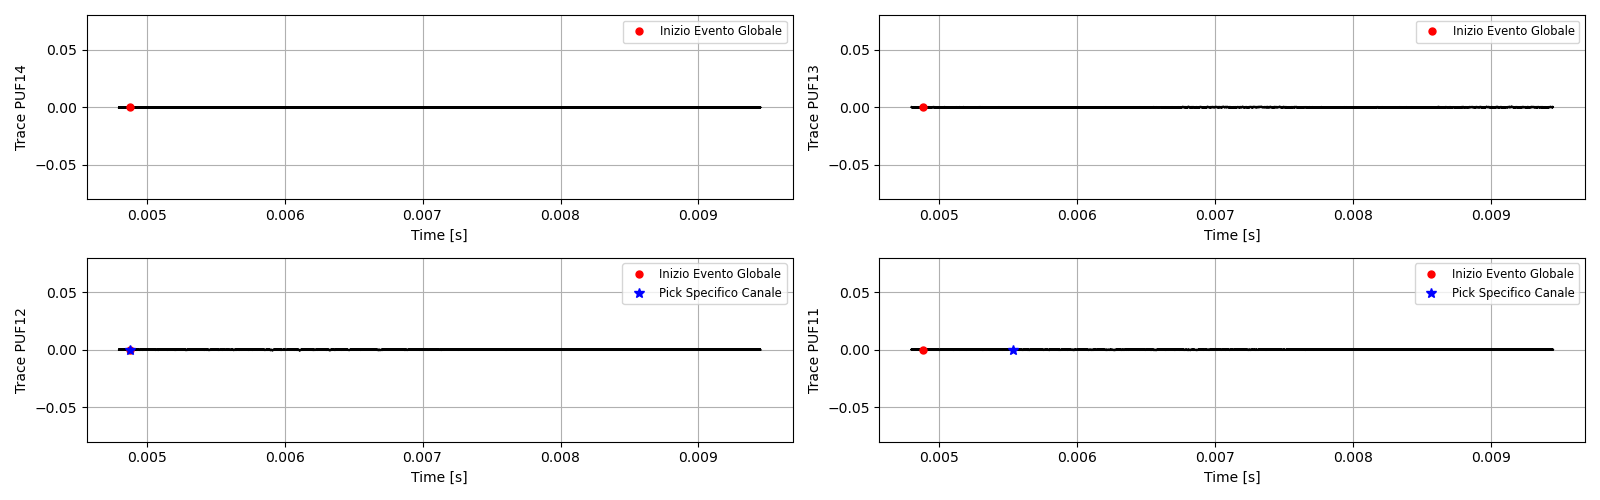

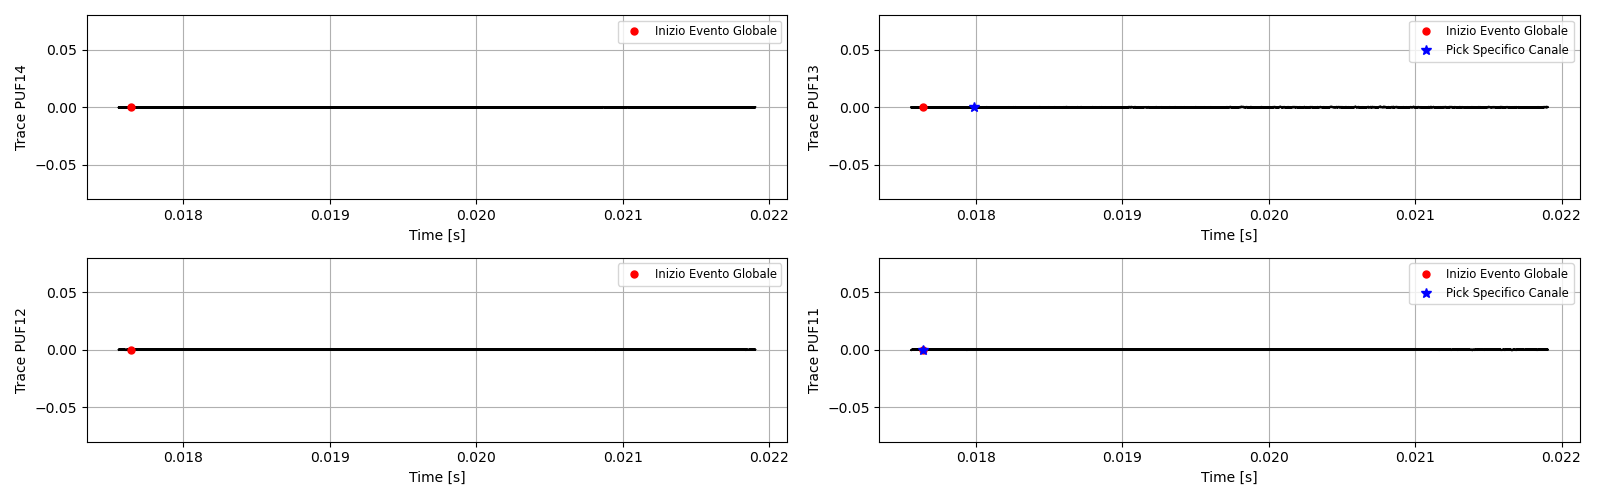

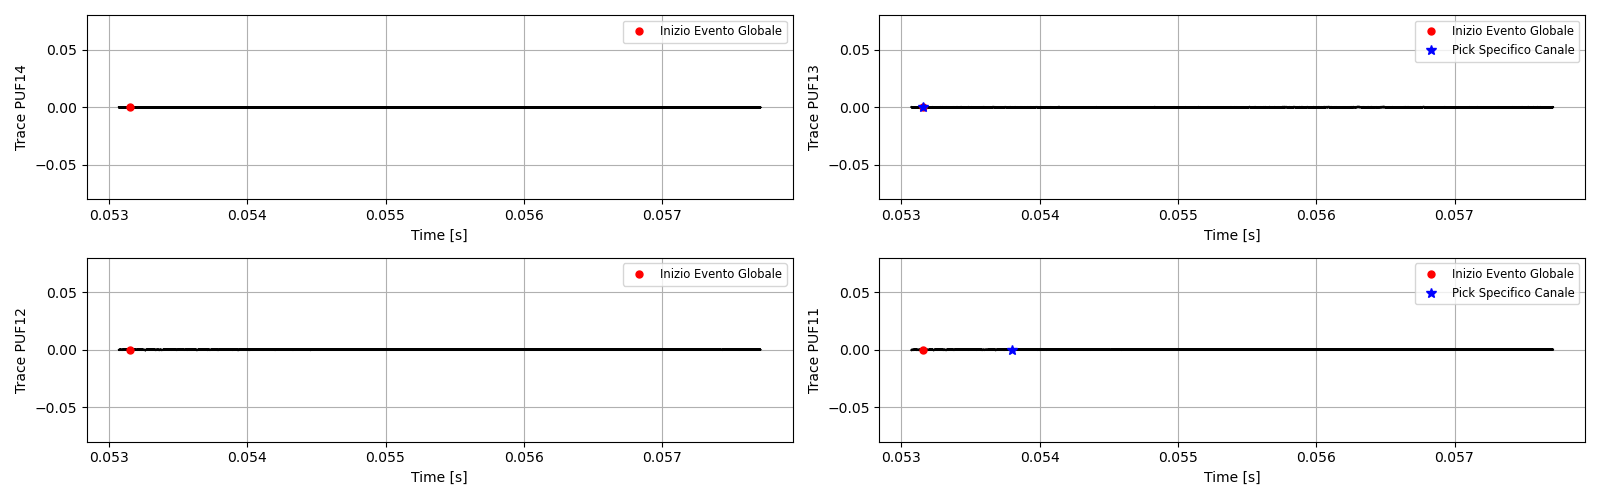

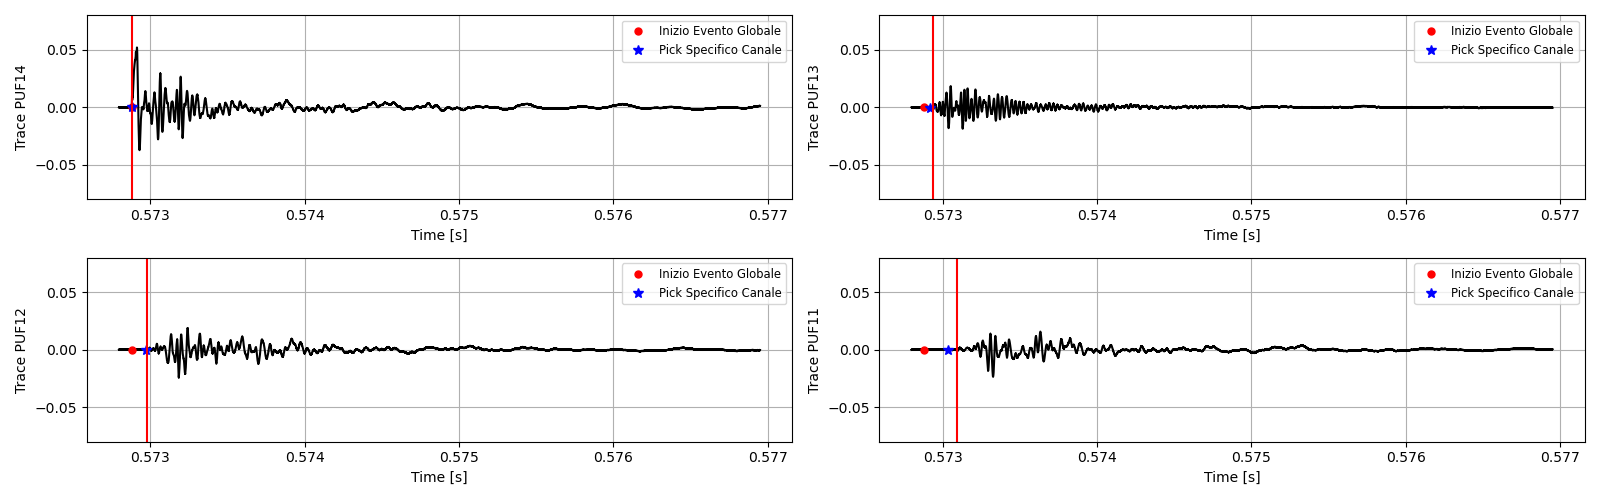

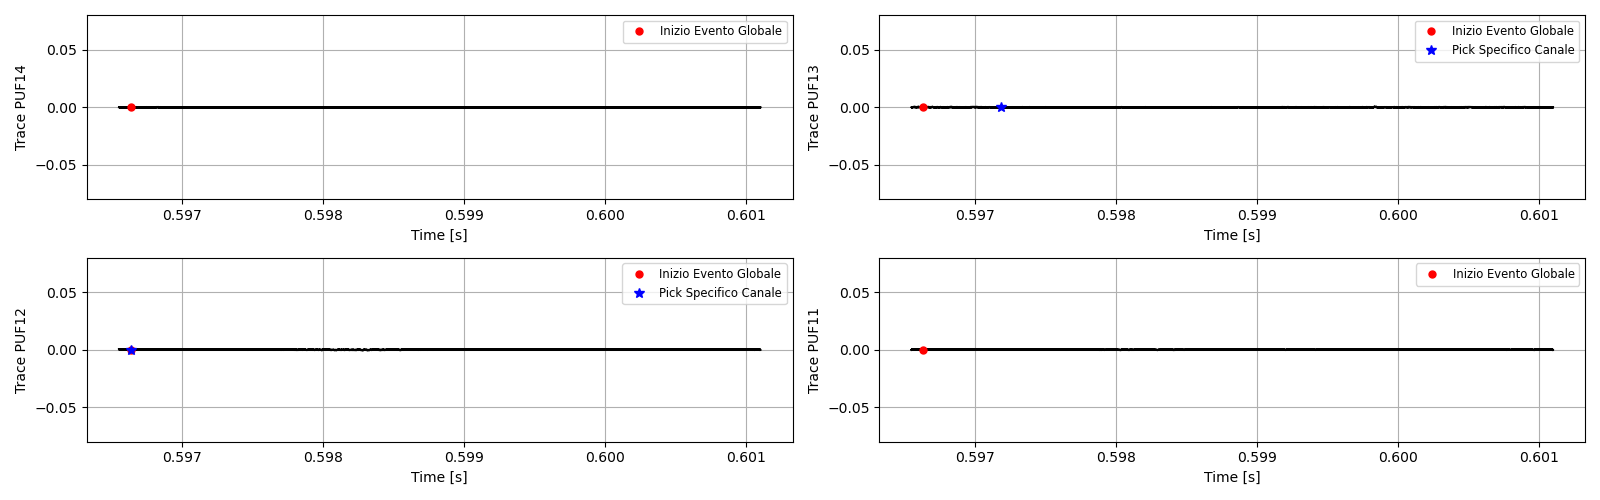

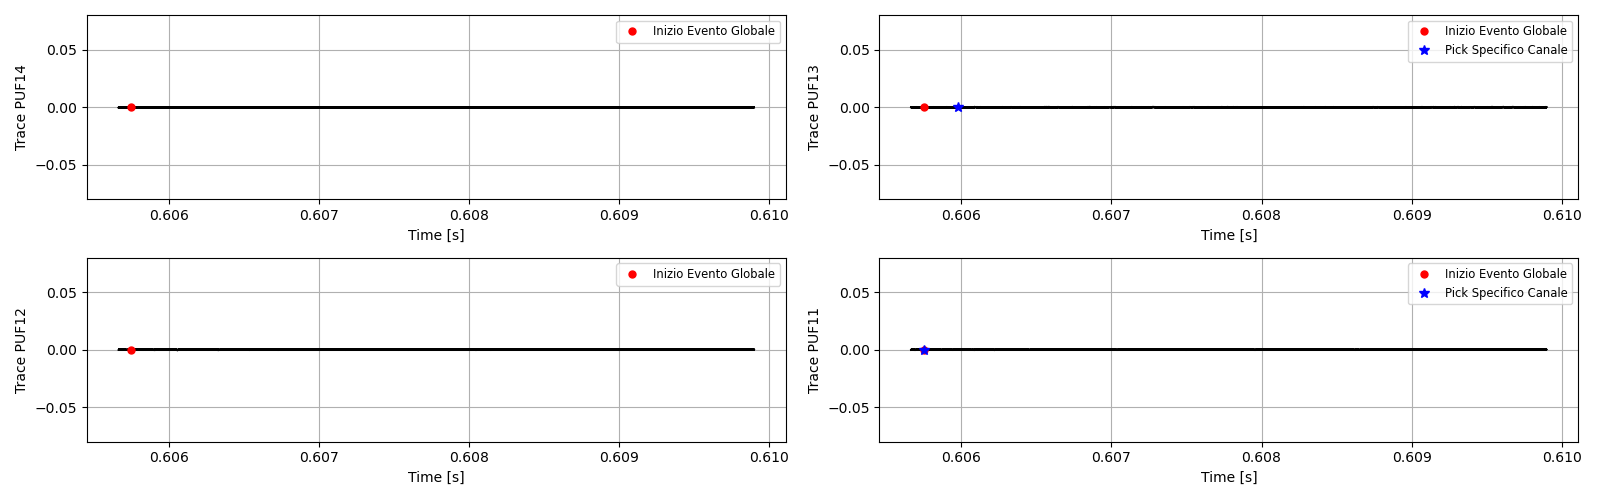

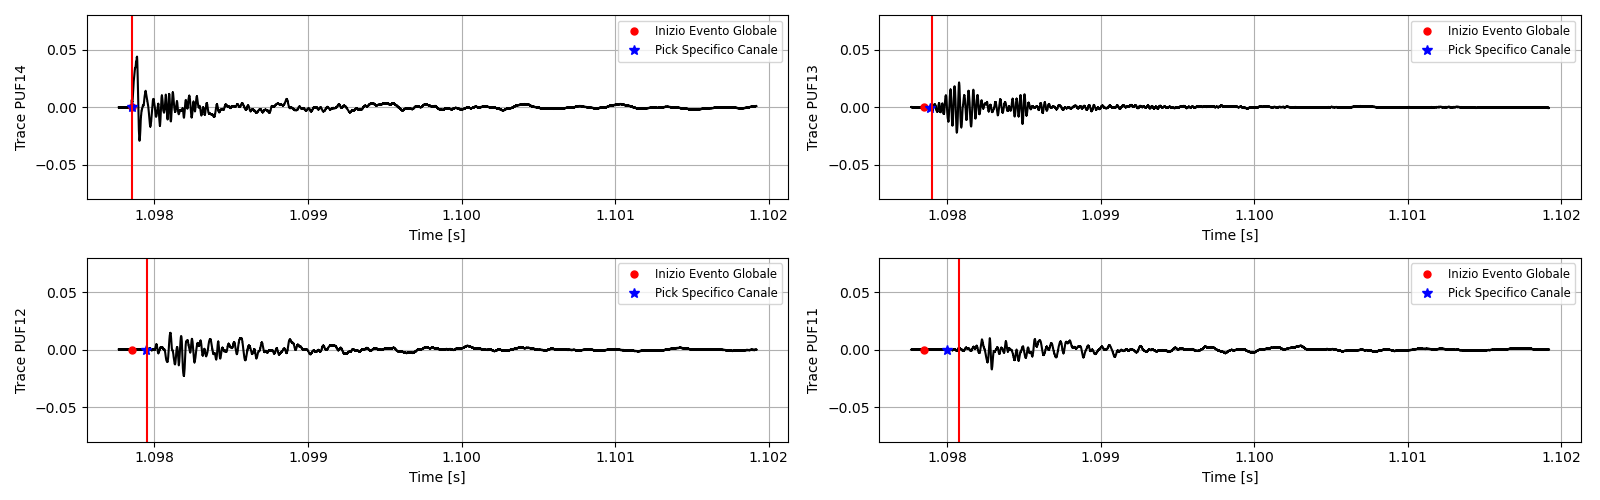

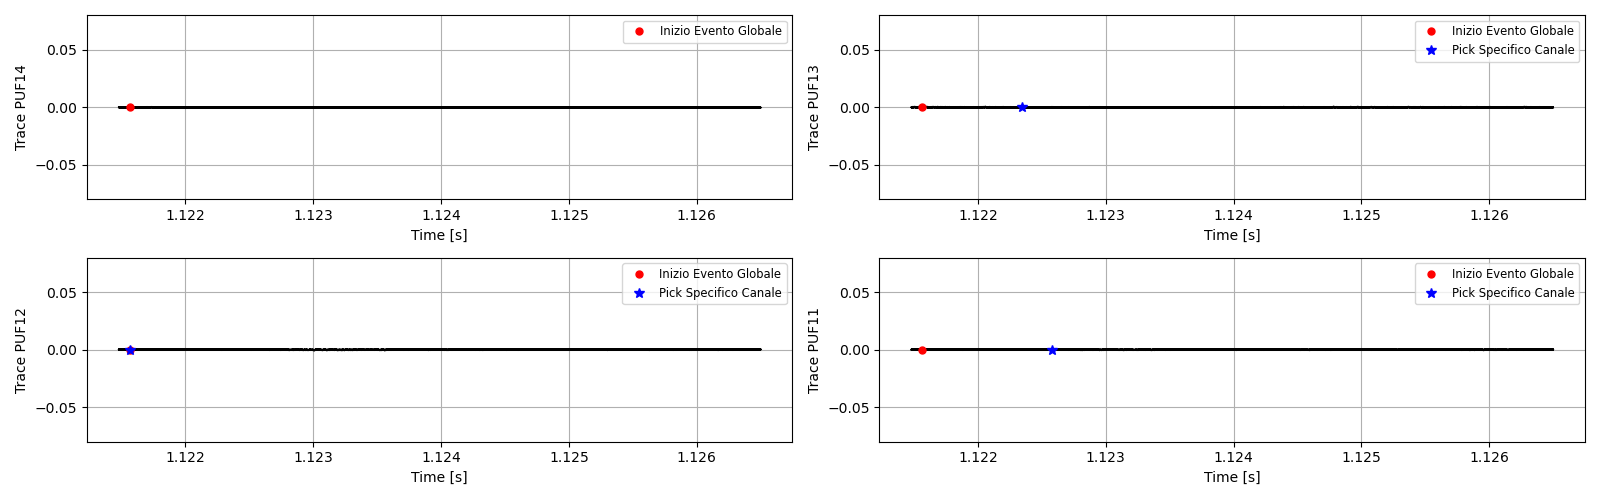

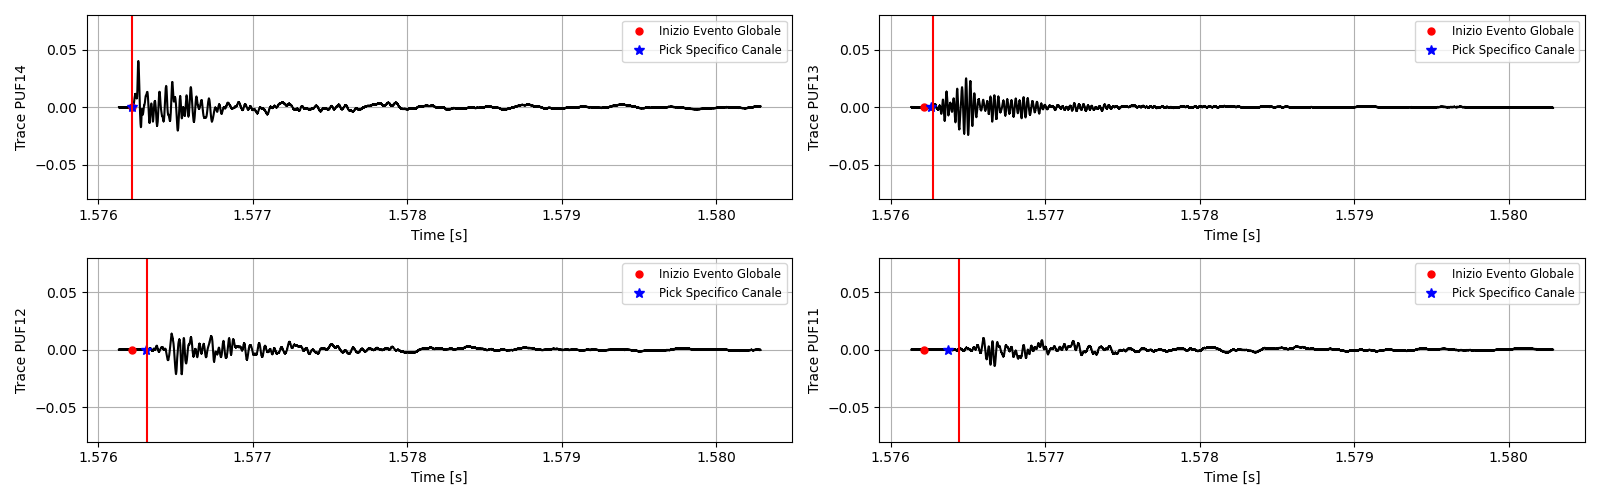

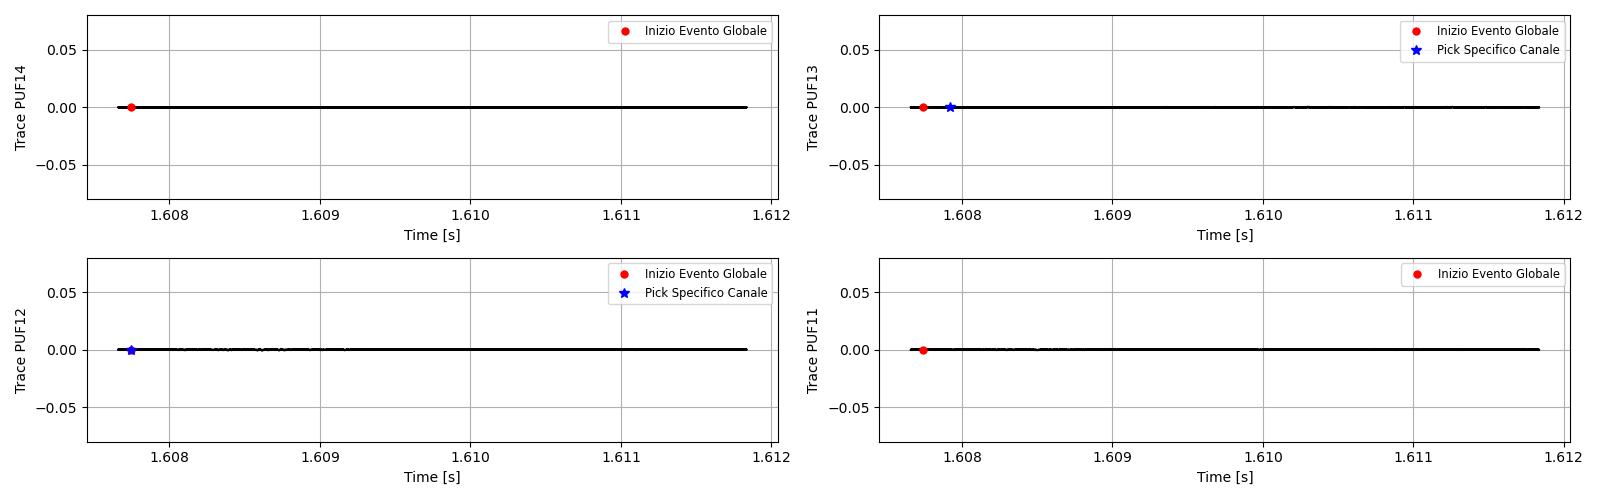

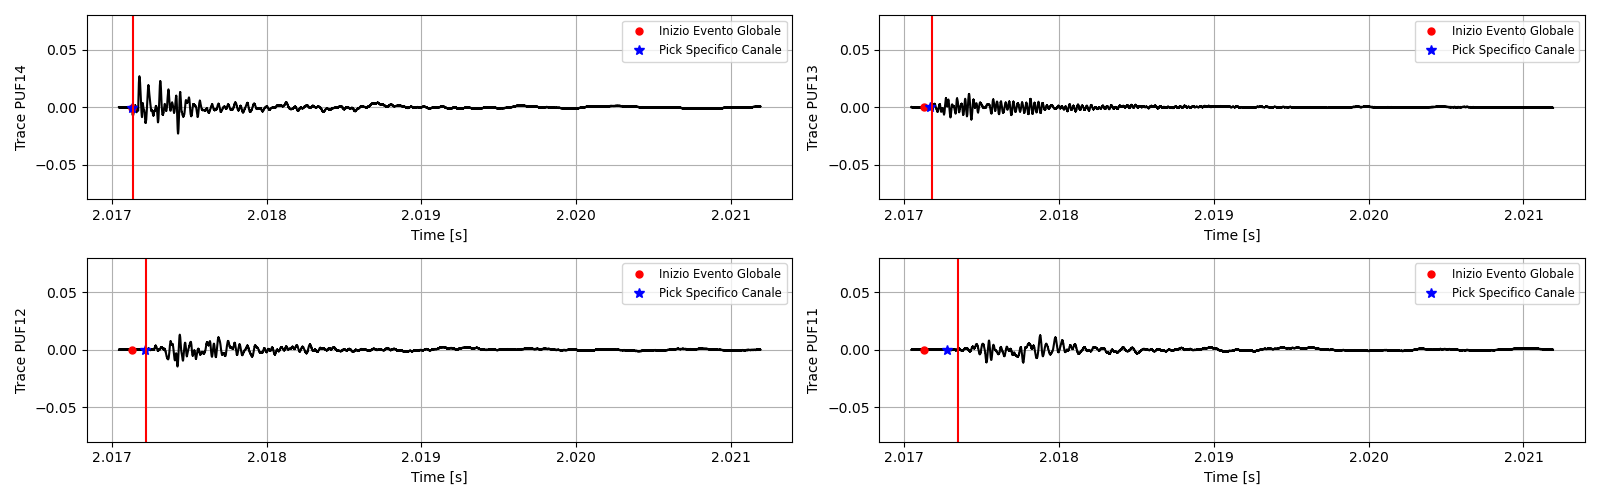

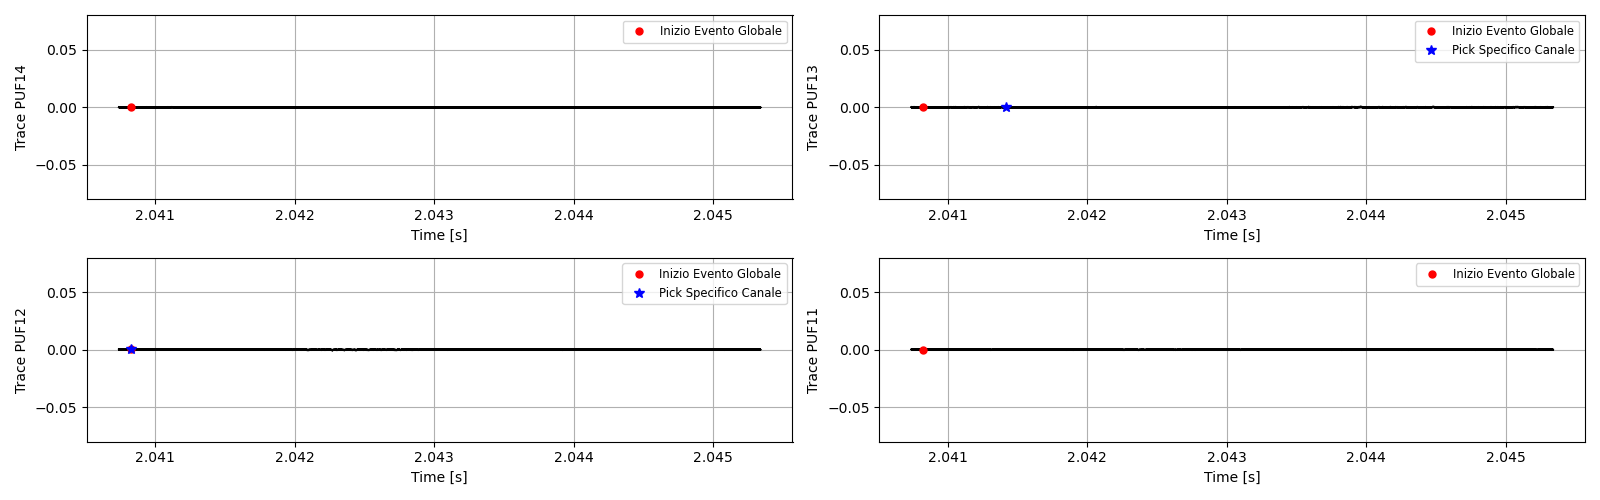

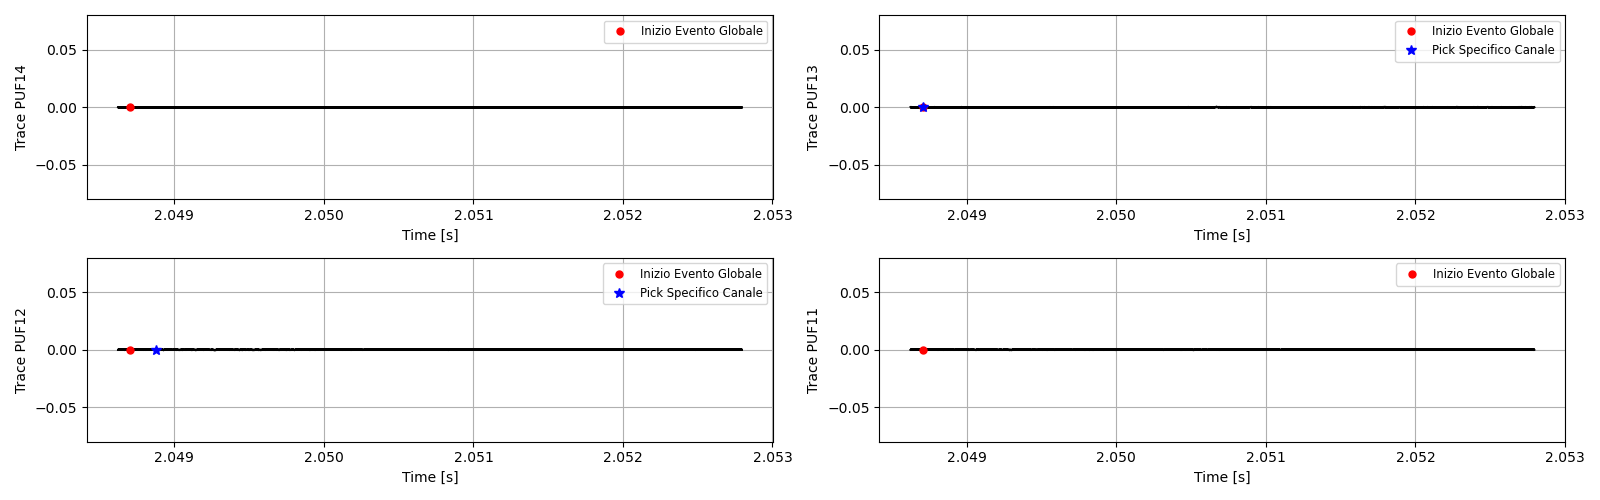

{0: {'PUF14': {'global_first_arrival': 0.0048824, 'arrival_amplitude': -0.00026345252990722656, 'channel_specific_arrival': nan, 'channel_arrival_amplitude': 0, 'first_amp': 0.0, 'first_peak_time': nan, 'peak_amplitude': 6.127357482910156e-05, 'peak_time': 0.007091200378197354, 'time': array([0.00479952, 0.00479968, 0.00479984, ..., 0.0094488 , 0.00944896,
       0.00944912]), 'trace': array([-3.79800797e-04, -2.69651413e-04, -2.02178955e-04, ...,
       -1.53183937e-04, -8.57710838e-05, -1.47104263e-04])}, 'PUF13': {'global_first_arrival': 0.0048824, 'arrival_amplitude': 8.028745651245117e-05, 'channel_specific_arrival': nan, 'channel_arrival_amplitude': 0, 'first_amp': 0.0, 'first_peak_time': nan, 'peak_amplitude': 0.0003273487091064453, 'peak_time': 0.008619840459724824, 'time': array([0.00479952, 0.00479968, 0.00479984, ..., 0.0094488 , 0.00944896,
       0.00944912]), 'trace': array([ 3.70740891e-05,  1.85370445e-05, -4.32729721e-05, ...,
       -1.23381615e-05, -6.79492950e-05,  

In [27]:
dropdata, parameters = output(folder_path, material, block, position, size, dropN, sta_config, lta_config, threshold, thr_off, AIC)

print(dropdata)
print(parameters)

Function that calculates arrival time differences from the above output

In [ ]:
def calculate_arrival_time_differences(dataset, idx1, idx2):
    """
    Computes, channel by channel, the difference between the arrival times picked for
    two different events (e.g. two ball-drop events stored in the same `drops` dictionary).

    For every channel that has a valid pick in BOTH events, the function returns the two
    arrival times and their difference, defined as (time of event idx2) - (time of event idx1).
    A positive value therefore means that the signal arrives later in event idx2 than in event idx1.

    Requires numpy (as np) and pandas (as pd) to be imported.

    INPUT PARAMETERS:
    ----------------
    dataset : dict
        Event-indexed dictionary with the structure produced by `output()`:
        {event_id: {channel_name: {features}}}. Each feature dictionary must be able to
        provide the key 'channel_specific_arrival' (the pick time of that channel, in seconds).
    idx1 : int
        Identifier (key in `dataset`) of the first, or reference, event.
    idx2 : int
        Identifier (key in `dataset`) of the second event, compared against the first.

    OUTPUT PARAMETERS:
    -----------------
    results : dict
        {channel_name: {f'time_index_{idx1}': arrival time in event idx1 [s],
                        f'time_index_{idx2}': arrival time in event idx2 [s],
                        'time_difference': time_index_idx2 - time_index_idx1 [s]}}
        Only channels with a valid pick in both events are included. If either event is
        missing from the dataset, or no channel has valid picks in both, an empty dict is returned.
    """
    results = {}
    # Collect all unique channel names across the dataset dictionary
    # (union of the channels of every event, so that no channel is missed)
    all_channels = set()
    for drop_idx in dataset.values():
        all_channels.update(drop_idx.keys())
    
    for ch in all_channels:
        # Check that both events exist in the dataset and that both contain data for this channel
        if idx1 in dataset and idx2 in dataset and ch in dataset[idx1] and ch in dataset[idx2]:
            # Channel-specific pick time in each event; NaN if the key is missing
            time1 = dataset[idx1][ch].get('channel_specific_arrival', np.nan)
            time2 = dataset[idx2][ch].get('channel_specific_arrival', np.nan)
            
            # Validate that both times are not NaN and not 0
            # (NaN means that the channel did not pick the event; 0 is also treated as "no valid pick")
            is_valid_1 = pd.notna(time1) and time1 != 0
            is_valid_2 = pd.notna(time2) and time2 != 0
            
            # Store the result only if both picks are valid
            if is_valid_1 and is_valid_2:
                # Arrival time difference [s]: event idx2 minus event idx1
                time_diff = time2 - time1
                results[ch] = {
                    f'time_index_{idx1}': time1,
                    f'time_index_{idx2}': time2,
                    'time_difference': time_diff
                }
    return results

In [15]:
treb = calculate_arrival_time_differences(dropdata, idx1=0, idx2=1)

NameError: name 'calculate_arrival_time_differences' is not defined

## Save output

In [35]:
directory = '/home/oreios/Calibrations/pzt_calibration_alessia/Upper_block_results'

In [63]:
saveoutput(dropdata[2], parameters, directory, position, size, dropN)

Struttura cartelle verificata/creata in: /home/oreios/Calibrations/pzt_calibration_alessia/examplesbad/data_ball_drop_3_[26.7, 0, 1]/drop_5
Clip salvate in binario su /home/oreios/Calibrations/pzt_calibration_alessia/examplesbad/data_ball_drop_3_[26.7, 0, 1]/drop_5/[26.7, 0, 1]_3_drop_5.bin
Metadati salvati su /home/oreios/Calibrations/pzt_calibration_alessia/examplesbad/data_ball_drop_3_[26.7, 0, 1]/drop_5/[26.7, 0, 1]_3_drop_5.txt


## Plot picks in order

Dati binari ripristinati correttamente.
{0: {'PB28': {'global_first_arrival': 0.68288176, 'arrival_amplitude': 0.00014090538024902344, 'channel_specific_arrival': 0.68288176, 'channel_arrival_amplitude': 0.00014090538024902344, 'first_amp': 0.00392913818359375, 'first_peak_time': 0.6828835564204564, 'peak_amplitude': 0.004962921142578125, 'peak_time': 0.6830078764270868, 'time': array([0.68279892, 0.68279908, 0.68279924, ..., 0.6871802 , 0.68718036,
       0.68718052]), 'trace': array([-8.57710838e-05, -2.51293182e-04, -1.04188919e-04, ...,
       -1.04188919e-04, -6.74128532e-05, -1.28626823e-04])}, 'PB14': {'global_first_arrival': 0.68288176, 'arrival_amplitude': 6.794929504394531e-05, 'channel_specific_arrival': 0.68312624, 'channel_arrival_amplitude': 0.0003459453582763672, 'first_amp': -0.0032501220703125, 'first_peak_time': 0.6831419564342377, 'peak_amplitude': 0.0038547515869140625, 'peak_time': 0.6831851564365418, 'time': array([0.68279892, 0.68279908, 0.68279924, ..., 0.687180

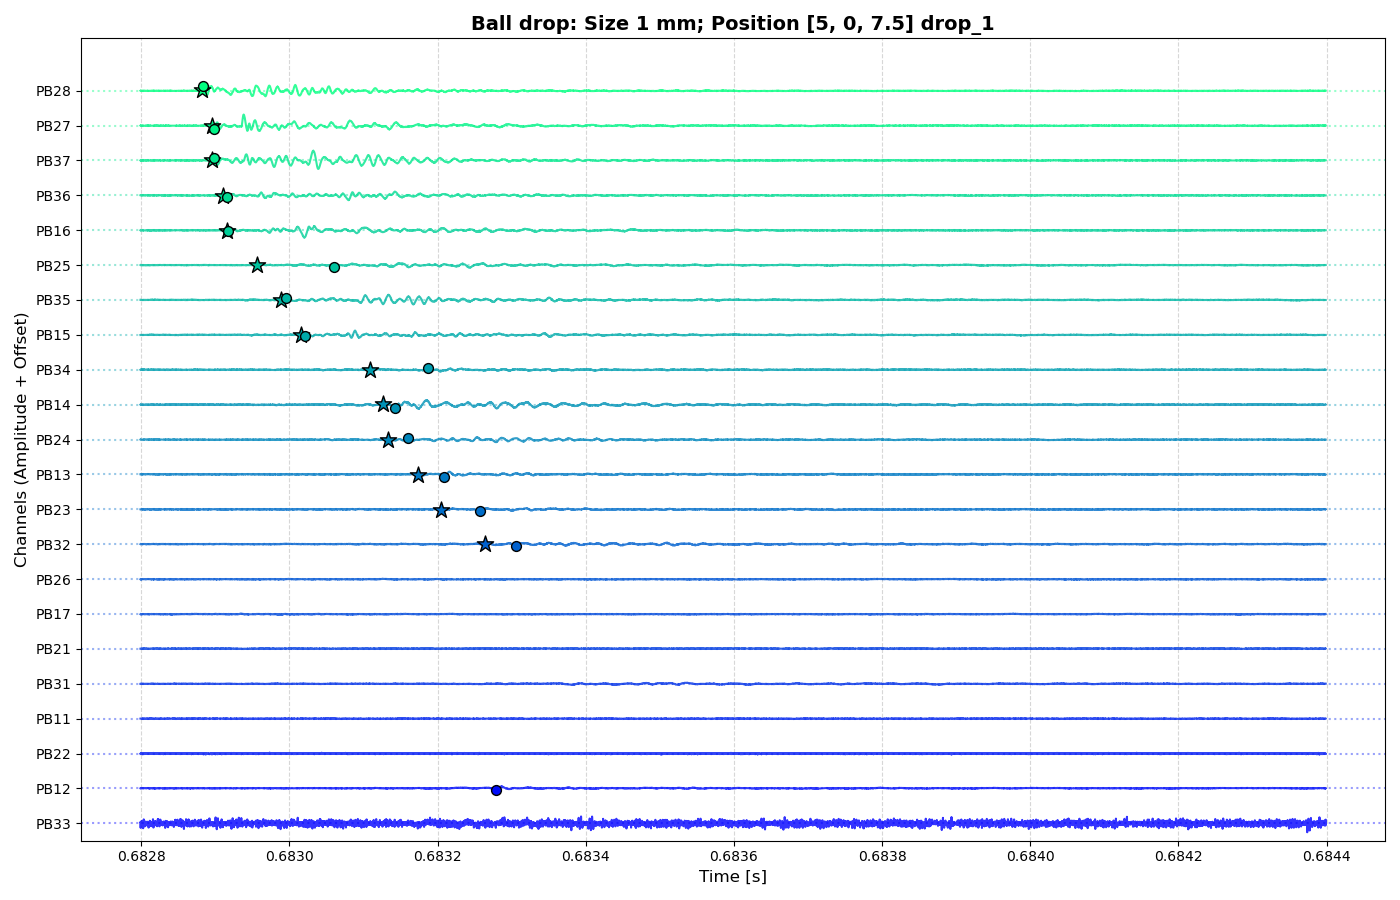

In [84]:
directory = '/home/oreios/Calibrations/pzt_calibration_alessia/Upper_block_results'
position = '[5, 0, 7.5]'
size = '1'
dropN = 'drop_1'
direct = '/mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/'

dropdata_caricato, parameters_caricati, loc = loadoutput(directory, position, size, dropN)
print(dropdata_caricato) # picking
print(parameters_caricati)
plot_picks_together_sep(dropdata_caricato,parameters_caricati, position, dropN, size, sort_by='arrival_time', colormap_name='winter_r', output_dir=direct, skipped_channels=['SB21', 'SB22', 'SB23', 'SB24'])



# Plot channel arrival amplitudes

In [ ]:
# Fixed ordering of the sensors, used as the X-axis order in the amplitude plot.
# The names follow the sensor naming convention of the array (PUF/PUB/PB/PBB prefixes),
# listed group by group.
ordine_sensori_fisso = [
    "PUF11", "PUF12", "PUF13", "PUF14", "PUB11", "PUB12",
    "PB11", "PB12", "PB13", "PB14", "PB15", "PB16", "PB17",
    "PB21", "PB22", "PB23", "PB24", "PB25", "PB26", "PB27", "PB28",
    "PB31", "PB32", "PB33", "PB34", "PB35", "PB36", "PB37",
    "PBB1", "PBB2", "PBB3", "PBB4"
]

def plot_channel_arrival_amplitudes(base_folder, block, position, size, dropN):    
    """
    Plots, for a single event, the first-peak amplitude (absolute value) recorded by each
    sensor, with the sensors arranged along the X axis in the fixed order defined by
    `ordine_sensori_fisso`. Only sensors with a valid arrival pick are shown.

    This function relies on the global variable `dropdata_caricato`, which must exist
    before the call: a dictionary {channel_name: {features}} for ONE event, with the
    structure produced by `output()` (e.g. one event of the `drops` dictionary returned
    by `output()` or `loadoutput()`). Requires numpy (as np), pandas (as pd) and
    matplotlib.pyplot (as plt) to be imported.

    INPUT PARAMETERS:
    ----------------
    base_folder : str
        Not used inside the function (kept in the signature for consistency with the
        other functions of the workflow).
    block : str
        Identifier of the block (e.g. 'Lower_block'); used only in the plot title.
    position : str
        Spatial position of the drop (e.g. '[48.8, 0, 1]'); used only in the plot title.
    size : str or int
        Ball size/diameter; used only in the plot title.
    dropN : str
        Identifier of the drop (e.g. 'drop_5'); used only in the plot title.

    OUTPUT PARAMETERS:
    -----------------
    amplitudes : list of float
        Absolute first-peak amplitudes ('first_amp'), one per valid channel, in the order
        of `ordine_sensori_fisso`.
    channels : list of str
        Names of the channels that passed the validity check, in the same order as `amplitudes`.
    """
    # Lists that will hold the valid channel names and their amplitudes (same order)
    channels = []
    amplitudes = []
    # Scan the sensors in the fixed order
    for ch in ordine_sensori_fisso:
        # Skip sensors that are not present in the loaded event data
        if ch in dropdata_caricato:
            ch_data = dropdata_caricato[ch]
            # Channel-specific pick time of this sensor (NaN if the key is missing)
            picking_time = ch_data.get('channel_specific_arrival', np.nan)
            # Condition: the picking time must be neither 0 nor NaN
            # (i.e. the channel actually detected the event)
            is_valid_time = pd.notna(picking_time) and picking_time != 0
            if is_valid_time:
                channels.append(ch)
                # Store the absolute value of the first-peak amplitude ('first_amp'),
                # i.e. the first peak above the noise threshold found by `output()`.
                # (Note: this is NOT the amplitude at the pick time, 'channel_arrival_amplitude'.)
                amplitudes.append(abs(ch_data.get('first_amp', 0.0)))

    # Create the plot: one point per sensor, amplitude on the Y axis (despite the
    # "bar chart" heading of the original comment, a scatter plot is drawn)
    plt.figure(figsize=(14, 6))
    plt.scatter(channels, amplitudes, color='crimson', edgecolor='black', alpha=0.8)
    # Dashed grey line at zero amplitude as a reference baseline
    plt.axhline(0, color='grey', linewidth=0.8, linestyle='--')
    plt.xlabel('Sensors', fontsize=12)
    plt.ylabel('Channel Arrival Amplitude', fontsize=12)
    plt.title(f'Channel Arrival Amplitudes\n(Block: {block} | Pos: {position} | Size: {size} | {dropN})', fontsize=14)
    # Rotate the sensor names so that they do not overlap
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()
    return amplitudes, channels


In [8]:
base_folder = '/home/oreios/Calibrations/pzt_calibration_alessia/Lower_block_results'
block = 'Lower_block'
position = '[37.6, 0, 15]'
size = '3'
dropN = 'drop_5'
material = 'PMMA'
dropdata_caricato, parameters_caricati, loc = loadoutput(base_folder, position, size, dropN)
print(dropdata_caricato)
print(parameters_caricati)
plot_channel_arrival_amplitudes(base_folder, block, position, size, dropN)

NameError: name 'loadoutput' is not defined

## Esercizio: save output


### 1. Filtraggio dei Gruppi (`final_groups`)
* **Obiettivo**: Filtrare i dati per individuare gli eventi rappresentati da un **numero minimo di canali**. 
* **Motivazione**: I gruppi con troppi pochi canali attivi sono probabilmente da considerare rumore o falsi positivi (*false detections*).

---

### 2. Salvataggio Output e Convenzione di Naming

> ⚠️ **Importante**: Utilizzare sempre un **nome univoco** per l'output, che permetta di identificare chiaramente a quale specifico *ball drop* si riferiscono i dati.

Per ogni **ball drop** e per ciascun **rimbalzo**, è necessario salvare:

* **Forme d'onda "tagliate" (*clipped*)**: Tracciato per ogni canale, da poco prima del picco fino alla conclusione dell'evento. Tutte le forme d'onda devono avere la stessa durata.
* **Massimi del primo arrivo**: I picchi in ampiezza associati al prim arrivo piccato. Potresti definire una finestra che parte da dopo il primo arrivo e da quella selezionare il massimo in ampiezza.
* **Parametri di picking**: Configurazione utilizzata per il rilevamento (es. *threshold* STA/LTA e parametro di *tolerance* per l'associazione).
* **Tempi di rimbalzo**

* **Potrei aver dimenticato qualcosa, se ti viene in mente qualcosa altro di utile salvalo!!!**


# Localization

In [125]:
# =====================================================================
# CONFIGURAZIONE VARIABILI DI INPUT (MODIFICABILI)
# =====================================================================
# Percorso assoluto della cartella contenente i risultati sperimentali del blocco inferiore
base_folder = '/home/oreios/Calibrations/pzt_calibration_alessia/Upper_block_results'
directory = '/home/oreios/Calibrations/pzt_calibration_alessia/Lower_block_results'

block = 'Lower_block'       # Seleziona l'oggetto dell'analisi: 'Lower_block' (blocco inf.) o 'Upper_block' (blocco sup.)
position = '[5, 0, 7.5]'  # Coordinate spaziali [X, Y, Z] in cm dove è avvenuto il drop (sorgente dell'evento)
size = '1'                  # Parametro dimensionale associato al test eseguito (es. diametro o tipo di sorgente)
dropN = 'drop_1'            # Identificativo specifico del drop (lancio/evento ripetuto) da analizzare
material = 'PMMA'           # Materiale dei blocchi, usato per caricare il file di calibrazione geometrica corrispondente

# Funzione esterna che carica il dizionario degli eventi (dropdata_caricato) e i metadati associati (parameters_caricati)


In [122]:
drops_caricati, parameters_caricati, localization_caricata = loadoutput(base_folder, position, size, dropN)
drops_caricati

FileNotFoundError: Impossibile trovare i file richiesti in: /home/oreios/Calibrations/pzt_calibration_alessia/Upper_block_results/data_ball_drop_1_[5, 0, 7.5]/drop_1

--- CONFIGURAZIONE RILEVATA ---
Blocco Selezionato: Lower_block (Target Char: 'B')
Coordinata Y rilevata: 0.0 -> Faccia: FRONT (Target Char: 'F')
--------------------------------------------------------------------------------
Sensori attivi attesi per questa configurazione (Esclusi 'S'): ['PBF11', 'PBF12', 'PBF13', 'PBF14', 'PBF15', 'PBF16', 'PBF17', 'PBF21', 'PBF22', 'PBF23', 'PBF24', 'PBF25', 'PBF26', 'PBF27', 'PBF28', 'PBF31', 'PBF32', 'PBF33', 'PBF34', 'PBF35', 'PBF36', 'PBF37']
--------------------------------------------------------------------------------
Rilevato dizionario a livello singolo: convertito automaticamente in evento singolo.

Evento: singolo_evento | Sensori Attivi = 16 | DTOA generati = 120
GRID  | singolo_evento | X=25.84, Z=0.88 | Misfit RMS: 2.00e-06 s
FINAL | singolo_evento | X=25.62, Z=0.80 | Misfit RMS: 1.84e-06 s
--------------------------------------------------------------------------------


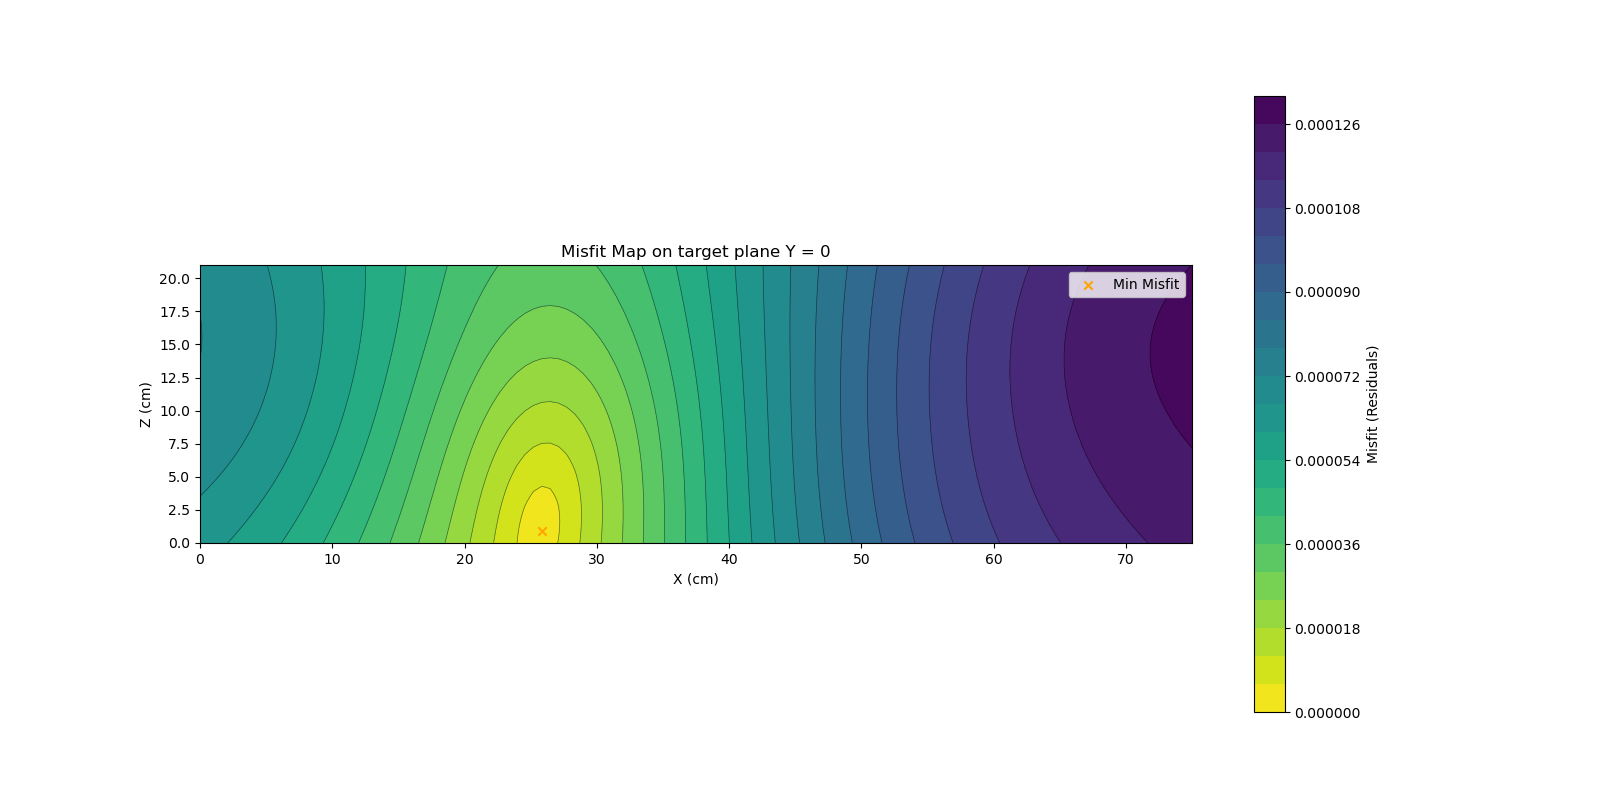

In [101]:
# --- 1. SETTAGGIO CHIAVI E VELOCITÀ DINAMICHE ---
# Converte il nome del blocco in minuscolo per accoppiarlo alle chiavi del dizionario globale 'assembly'
block_key = block.lower()  

# Estrae la velocità delle onde P (Vp) dal dizionario di configurazione e la converte da m/s a cm/s (* 100)
vp = assembly[block_key]['Vp [m/s]'] * 100  

# Estrae la velocità delle onde S (Vs) e la converte in cm/s (usata come riferimento elastico del mezzo)
vs = assembly[block_key]['Vs [m/s]'] * 100  

# Recupera l'altezza nominale del blocco dal dizionario e la converte in cm
altezza_cm = assembly[block_key]['height [m]'] * 100

# --- 2. CARICAMENTO E PARSING DEL CSV SENSORI ---
# Definisce il percorso della cartella contenente le calibrazioni posizionali dei sensori ad emissione acustica (AE)
AE_calib_folder = Path("/mnt/scratch/oreios/Calibrations/AE/")
# Costruisce il percorso del file CSV geometrico specifico per il materiale selezionato
file_path = AE_calib_folder / f"AE_sensors_coordinates_{material}.csv"
# Carica il file CSV in un DataFrame di Pandas
sens_coord = pd.read_csv(file_path)

# Correzione empirica: se nel CSV la coordinata Y è segnata a 8.5, viene corretta a 8.65 per tolleranze geometriche reali
sens_coord.loc[sens_coord['Y'] == 8.5, 'Y'] = 8.65

# Crea un dizionario di mappatura rapida {NOME_SENSORE: array([X, Y, Z])} basato sul CSV.
# REQUISITI DI FILTRAGGIO: la riga deve avere un nome sensore valido e il nome NON deve iniziare con "S" (esclusione sensori S)
sensor_map = {
    row['SENSOR'].strip().upper(): np.array([row['X'], row['Y'], row['Z']]) 
    for _, row in sens_coord.iterrows() 
    if pd.notna(row['SENSOR']) and not str(row['SENSOR']).strip().upper().startswith("S")
}

# --- 3. LOGICA DI DISTINZIONE AGGIORNATA ---
# Identifica il carattere del blocco target basandosi sulla configurazione iniziale ('B' per blocco inferiore, 'U' per superiore)
target_block_char = 'B' if block_key == 'lower_block' else 'U'

# Struttura di controllo per determinare se l'evento è avvenuto sulla faccia Frontale (F) o Posteriore (B) del blocco.
# Regola logica richiesta: Se Y è esattamente 0.0 -> Faccia FRONT ('F'), altrimenti -> Faccia BACK ('B')
try:
    pos_array = eval(position)    # Converte la stringa della posizione in una lista Python computabile
    y_val = float(pos_array[1])   # Estrae la coordinata Y
    
    if y_val == 0.0:
        target_face_char = 'F'    # Se Y == 0 -> Faccia identificata come Front (F)
    else:
        target_face_char = 'B'    # Se Y != 0 -> Faccia identificata come Back (B)
except Exception:
    target_face_char = 'B'        # Fallback difensivo in caso di fallimento del parsing della stringa

# Stampe diagnostiche per verificare a terminale la consistenza dei parametri estratti rispetto all'input
print(f"--- CONFIGURAZIONE RILEVATA ---")
print(f"Blocco Selezionato: {block} (Target Char: '{target_block_char}')")
print(f"Coordinata Y rilevata: {y_val} -> Faccia: {'BACK' if target_face_char == 'B' else 'FRONT'} (Target Char: '{target_face_char}')")
print("-" * 80)

# Isola dal file CSV solo i sensori piezoelettrici associati al blocco e alla faccia attualmente sotto analisi
valid_sensors_csv = []
for s in sens_coord["SENSOR"]:
    if isinstance(s, str):
        s_upper = s.strip().upper()
        # Vincoli stringenti: il nome deve iniziare con 'P', lunghezza minima 3 caratteri,
        # la seconda lettera deve corrispondere al blocco e la terza alla faccia target.
        if len(s_upper) >= 3 and s_upper.startswith("P"):
            if s_upper[1] == target_block_char and s_upper[2] == target_face_char:
                valid_sensors_csv.append(s_upper)

# Rimuove eventuali duplicati e ordina alfabeticamente la lista dei sensori attesi (es. ['PBF11', 'PBF12', ...])
sensor_names = sorted(list(set(valid_sensors_csv)))
# Associa a ciascun nome sensore un indice numerico intero univoco [0, 1, 2...] per la gestione delle matrici dati
sensor_index = {name: i for i, name in enumerate(sensor_names)}

print(f"Sensori attivi attesi per questa configurazione (Esclusi 'S'): {sensor_names}")
print("-" * 80)

# --- 4. CICLO DI INVERSIONE SUGLI EVENTI ---
results = []

# --- NORMALIZZAZIONE INPUT (Gestione singolo evento o multi-evento) ---
# Controlliamo se il dizionario in ingresso rappresenta già un singolo evento.
# Se una qualsiasi delle chiavi di primo livello è un sensore valido (es. inizia con 'P' o 'S' ed è stringa),
# allora l'input è un singolo evento e lo "impacchettiamo" in un dizionario a due livelli fittizio.
is_single_event = False
if isinstance(dropdata_caricato, dict) and len(dropdata_caricato) > 0:
    prima_chiave = list(dropdata_caricato.keys())[0]
    if isinstance(prima_chiave, str):
        chiave_pulita = prima_chiave.strip().upper()
        if chiave_pulita.startswith("P") or chiave_pulita.startswith("S"):
            is_single_event = True

if is_single_event:
    # Trasformiamo l'input nel formato a due livelli atteso dal ciclo successivo
    dataset_elaborabile = {"singolo_evento": dropdata_caricato}
    print("Rilevato dizionario a livello singolo: convertito automaticamente in evento singolo.")
else:
    dataset_elaborabile = dropdata_caricato

# Ora il ciclo scorre sempre su una struttura standardizzata a due livelli
for event_id, evento in dataset_elaborabile.items():
    # Inizializza un array di tempi di arrivo lungo quanto la lista dei nostri sensori attesi, riempiendolo di NaN
    arrival_times = np.full(len(sensor_names), np.nan)

    # Legge i canali che hanno effettivamente registrato un segnale per questo specifico evento
    for sensore, dati in evento.items():
        sensore_dati = sensore.strip().upper()
        
        # Salta e ignora immediatamente la chiave se appartiene a un sensore di tipo 'S'
        if sensore_dati.startswith("S"):
            continue
            
        # --- RICOSTRUZIONE NOME PER MATCH CON CSV ---
        sensore_pulito = None
        
        if len(sensore_dati) >= 2 and sensore_dati.startswith("P"):
            blocco = sensore_dati[1]     # Estrae la seconda lettera (B o U)
            numero = sensore_dati[2:]    # Estrae la componente numerica finale (es. 28)
            
            # Ipotesi 1: Il nome atteso ricostruito con la faccia corrente (es. PBF28)
            ricostruito = f"P{blocco}{target_face_char}{numero}"
            
            if ricostruito in sensor_index:
                sensore_pulito = ricostruito
            # Ipotesi 2: Il nome nel CSV è salvato esattamente come nel file grezzo (es. PB28)
            elif sensore_dati in sensor_index:
                sensore_pulito = sensore_dati
        else:
            if sensore_dati in sensor_index:
                sensore_pulito = sensore_dati

        # Se il sensore non trova corrispondenza nei sensori attesi della configurazione, lo scarta
        if sensore_pulito is None:
            continue

        # Estrae il tempo di arrivo calcolato sul canale specifico
        t = dati.get("channel_specific_arrival", np.nan)
        if pd.isna(t):
            continue

        # Posiziona il tempo trovato nell'indice corretto
        arrival_times[sensor_index[sensore_pulito]] = t

    # Crea una maschera booleana per isolare esclusivamente i sensori che hanno un tempo di arrivo valido (!= NaN)
    active_mask = ~np.isnan(arrival_times)
    arrival_times = arrival_times[active_mask] # Array filtrato contenente solo i tempi di arrivo reali registrati
    
    # Estrae le coordinate XYZ tridimensionali dal dizionario 'sensor_map' solo per i sensori attivi
    coords = []
    for s in np.array(sensor_names)[active_mask]:
        if s in sensor_map:
            coords.append(sensor_map[s])
        else:
            # Fallback: rimuove la lettera della faccia per cercare il sensore nel CSV
            nome_grezzo = s[0:2] + s[3:] if len(s) >= 4 else s
            if nome_grezzo in sensor_map:
                coords.append(sensor_map[nome_grezzo])
            else:
                print(f"Attenzione: coordinate non trovate per il sensore {s} (o {nome_grezzo})")

    coords = np.array(coords)

    # Controllo matematico di solvibilità (almeno 4 stazioni attive)
    if len(coords) < 1:
        print(f"Evento {event_id}: Saltato. Sensori attivi insufficienti ({len(coords)}/4).")
        continue

    print(f"\nEvento: {event_id} | Sensori Attivi = {len(coords)} | DTOA generati = {len(arrival_times) * (len(arrival_times)-1) // 2}")

    # Correzione Geometrica di Sicurezza
    coords_corrette = coords.copy()
    for idx_c in range(len(coords_corrette)):
        if coords_corrette[idx_c, 2] < 0:
            coords_corrette[idx_c, 2] = altezza_cm + coords_corrette[idx_c, 2]

    # Calcolo combinatorio accoppiato delle differenze dei tempi di arrivo osservate (DTOA)
    dtoa = []
    for i in range(len(arrival_times)):
        for j in range(i + 1, len(arrival_times)):
            dtoa.append(arrival_times[j] - arrival_times[i])
    dtoa = np.asarray(dtoa)

    # Istanziazione della classe di simulazione fisica 'SingleBlock'
    event_sim = SingleBlock(
        dimensions=(
            assembly[block_key]['length [m]'] * 100,
            assembly[block_key]['width [m]'] * 100 + 0.15,
            altezza_cm + 1,
        ),
        grid_res=(120, 1, 120),
        AE_sensors=coords_corrette,
        v_p=vp,
        target_y=pos_array[1],  
    )

    try:
        # --- FASE 1: GRID SEARCH SUL PIANO X-Z ---
        grid_points, misfit_values = event_sim.compute_misfit(dtoa)
        best_grid_idx = np.argmin(misfit_values)
        loc_grid = grid_points[best_grid_idx]

        # --- FASE 2: INVERSIONE FINE MATRICIALE (METODO DI GEIGER VINCOLATO IN 2D) ---
        loc_final = event_sim.invert_location(dtoa, initial_guess=loc_grid)

        # Calcolo dei residui RMS finali
        misfit_grid = event_sim.compute_rms_misfit(dtoa, loc_grid)
        misfit_final = event_sim.compute_rms_misfit(dtoa, loc_final)

        print(f"GRID  | {event_id:<4} | X={loc_grid[0]:.2f}, Z={loc_grid[2]:.2f} | Misfit RMS: {misfit_grid:.2e} s")
        print(f"FINAL | {event_id:<4} | X={loc_final[0]:.2f}, Z={loc_final[2]:.2f} | Misfit RMS: {misfit_final:.2e} s")
        print("-" * 80)
        
        event_sim.plot_misfit_xz(dtoa)

    except Exception as e:
        import traceback
        print(f"Evento {event_id}: Errore di computazione o inversione matriciale ({e})")
        traceback.print_exc()

In [ ]:
def process_ae_events(assembly, block, material, position, dropdata_caricato):
  """Elabora gli eventi di emissione acustica (AE), calcola la localizzazione

  tramite Grid Search e inversione di Geiger, e restituisce un dizionario
  strutturato con i risultati, inclusi i residui RMS convertiti in centimetri.
  """
  block_key = block.lower()
  vp = assembly[block_key]["Vp [m/s]"] * 100
  vs = assembly[block_key]["Vs [m/s]"] * 100
  altezza_cm = assembly[block_key]["height [m]"] * 100

  AE_calib_folder = Path("/mnt/scratch/oreios/Calibrations/AE/")
  file_path = AE_calib_folder / f"AE_sensors_coordinates_{material}.csv"
  sens_coord = pd.read_csv(file_path)

  sens_coord.loc[sens_coord["Y"] == 8.5, "Y"] = 8.65

  sensor_map = {
      row["SENSOR"].strip().upper(): np.array([row["X"], row["Y"], row["Z"]])
      for _, row in sens_coord.iterrows()
      if pd.notna(row["SENSOR"])
      and not str(row["SENSOR"]).strip().upper().startswith("S")
  }

  target_block_char = "B" if block_key == "lower_block" else "U"

  try:
    pos_array = eval(position)
    y_val = float(pos_array[1])
    target_face_char = "F" if y_val == 0.0 else "B"
  except Exception:
    target_face_char = "B"
    y_val = 0.0
    pos_array = [0.0, 0.0, 0.0]

  valid_sensors_csv = []
  for s in sens_coord["SENSOR"]:
    if isinstance(s, str):
      s_upper = s.strip().upper()
      if len(s_upper) >= 3 and s_upper.startswith("P"):
        if s_upper[1] == target_block_char and s_upper[2] == target_face_char:
          valid_sensors_csv.append(s_upper)

  sensor_names = sorted(list(set(valid_sensors_csv)))
  sensor_index = {name: i for i, name in enumerate(sensor_names)}

  is_single_event = False
  if isinstance(dropdata_caricato, dict) and len(dropdata_caricato) > 0:
    prima_chiave = list(dropdata_caricato.keys())[0]
    if isinstance(prima_chiave, str):
      chiave_pulita = prima_chiave.strip().upper()
      if chiave_pulita.startswith("P") or chiave_pulita.startswith("S"):
        is_single_event = True

  if is_single_event:
    dataset_elaborabile = {"singolo_evento": dropdata_caricato}
  else:
    dataset_elaborabile = dropdata_caricato

  results_dict = {}

  for event_id, evento in dataset_elaborabile.items():
    arrival_times = np.full(len(sensor_names), np.nan)

    for sensore, dati in evento.items():
      sensore_dati = sensore.strip().upper()
      if sensore_dati.startswith("S"):
        continue

      sensore_pulito = None
      if len(sensore_dati) >= 2 and sensore_dati.startswith("P"):
        b_char = sensore_dati[1]
        numero = sensore_dati[2:]
        ricostruito = f"P{b_char}{target_face_char}{numero}"

        if ricostruito in sensor_index:
          sensore_pulito = ricostruito
        elif sensore_dati in sensor_index:
          sensore_pulito = sensore_dati
      else:
        if sensore_dati in sensor_index:
          sensore_pulito = sensore_dati

      if sensore_pulito is None:
        continue

      t = dati.get("channel_specific_arrival", np.nan)
      if pd.isna(t):
        continue

      arrival_times[sensor_index[sensore_pulito]] = t

    active_mask = ~np.isnan(arrival_times)
    arrival_times = arrival_times[active_mask]

    coords = []
    for s in np.array(sensor_names)[active_mask]:
      if s in sensor_map:
        coords.append(sensor_map[s])
      else:
        nome_grezzo = s[0:2] + s[3:] if len(s) >= 4 else s
        if nome_grezzo in sensor_map:
          coords.append(sensor_map[nome_grezzo])

    coords = np.array(coords)

    if len(coords) < 1:
      continue

    coords_corrette = coords.copy()
    for idx_c in range(len(coords_corrette)):
      if coords_corrette[idx_c, 2] < 0:
        coords_corrette[idx_c, 2] = altezza_cm + coords_corrette[idx_c, 2]

    dtoa = []
    for i in range(len(arrival_times)):
      for j in range(i + 1, len(arrival_times)):
        dtoa.append(arrival_times[j] - arrival_times[i])
    dtoa = np.asarray(dtoa)

    event_sim = SingleBlock(
        dimensions=(
            assembly[block_key]["length [m]"] * 100,
            assembly[block_key]["width [m]"] * 100 + 0.15,
            altezza_cm + 1,
        ),
        grid_res=(120, 1, 120),
        AE_sensors=coords_corrette,
        v_p=vp,
        target_y=pos_array[1],
    )

    try:
      grid_points, misfit_values = event_sim.compute_misfit(dtoa)
      best_grid_idx = np.argmin(misfit_values)
      loc_grid = grid_points[best_grid_idx]

      loc_final = event_sim.invert_location(dtoa, initial_guess=loc_grid)

      misfit_grid = event_sim.compute_rms_misfit(dtoa, loc_grid)
      misfit_final = event_sim.compute_rms_misfit(dtoa, loc_final)

      # Conversione del residuo RMS da secondi a centimetri tramite la velocità Vp (cm/s)
      rms_grid_cm = misfit_grid * vp
      rms_final_cm = misfit_final * vp

      results_dict[event_id] = {
          "grid_location": {"X": loc_grid[0], "Y": pos_array[1], "Z": loc_grid[2]},
          "final_location": {
              "X": loc_final[0],
              "Y": pos_array[1],
              "Z": loc_final[2],
          },
          "rms_grid_s": misfit_grid,
          "rms_grid_cm": rms_grid_cm,
          "rms_final_s": misfit_final,
          "rms_final_cm": rms_final_cm,
          "active_sensors_count": len(coords),
      }

    except Exception as e:
      results_dict[event_id] = {"error": str(e)}

  return results_dict

ANALISI DROP SINGOLO: DROP_5 | X=26.7, Y=0.0, Z=1.0 | Size: 3
Blocco: Lower_block | Materiale: PMMA | Faccia: F
Sensori attivi attesi: 22

---> Processing DROP_5...
Dati binari ripristinati correttamente.
DROP_5 RISULTATO | X=25.62 cm, Z=0.80 cm | Distanza teorico: 1.10 cm | RMS: 1.84e-06 s



{'drop': 'drop_5',
 'x_calc': 25.622344003312783,
 'y_calc': 0.0,
 'z_calc': 0.7969943925764341,
 'x_theo': 26.7,
 'y_theo': 0.0,
 'z_theo': 1.0,
 'distanza_geometrica_cm': 1.0966101056625954,
 'rms_misfit': 1.842118951436501e-06,
 'rms_cm': 0.5032117274724852,
 'coords': array([25.622344  ,  0.        ,  0.79699439]),
 'coords_theo': array([26.7,  0. ,  1. ])}

In [ ]:
# --- FUNCTION FOR THE VERTICAL MULTI-PANEL PLOT WITH SHARED COLORBAR AND GLOBAL NORMALISATION ---
def plot_multiple_misfit_subfigures(results_list, output_dir='.', x_limits=(0, 75), z_limits=(0, 21), colormap_name='plasma_r'):
    """
    Generates vertically stacked subplots of X-Z misfit maps, all normalised on a single
    global colour scale, so that the shared colorbar is accurate for every panel.
    The figure is saved as a 300 DPI .tif file and displayed on screen.

    Each map shows the RMS misfit (converted to cm) between the observed and the predicted
    arrival-time differences, evaluated on the X-Z grid of the block; the gold star marks
    the grid point with the minimum misfit.

    Requires os, numpy (as np), matplotlib.pyplot (as plt) and scipy.interpolate.griddata
    to be imported.

    INPUT PARAMETERS:
    ----------------
    results_list : list of dict
        List of result dictionaries as returned by `localizza_singolo_drop` (first output).
        Each dictionary must contain the keys 'event_sim' (SingleBlock simulation object),
        'dtoa' (observed arrival-time differences), 'vp' (P-wave velocity in cm/s, used to
        convert the misfit from seconds to cm), and 'drop', 'size', 'position' (used in the
        titles and in the file name).
    output_dir : str
        Folder in which the image is saved (created if it does not exist).
    x_limits : tuple of float
        (min, max) of the X axis in cm; also defines the interpolation grid extent.
    z_limits : tuple of float
        (min, max) of the Z axis in cm; also defines the interpolation grid extent.
    colormap_name : str
        Name of the matplotlib colormap used for the filled contours.

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function saves the figure as
        '<output_dir>/localization_pos_<position>_size_<size>_drop_<drop>.tif' and shows it.
        The file name is built from the FIRST element of `results_list` only.
        If the list is empty, or no result can be processed, a message is printed and
        the function returns without plotting.
    """
    num_plots = len(results_list)
    if num_plots == 0:
        print("Nessun risultato disponibile per il plot.")
        return

    # Make sure the destination folder exists
    if output_dir and not os.path.exists(output_dir):
        os.makedirs(output_dir, exist_ok=True)

    # 1. First pass: pre-compute the misfit grids and find the global min/max values
    #    (needed so that all panels share exactly the same colour scale)
    processed_data = []
    global_min = float('inf')
    global_max = float('-inf')

    for res in results_list:
        event_sim = res['event_sim']
        dtoa = res['dtoa']
        vp = res['vp']
        
        try:
            # Misfit evaluated at every point of the simulation grid, and the grid point with the lowest misfit
            grid_points, misfit_values = event_sim.compute_misfit(dtoa)
            best_grid_idx = np.argmin(misfit_values)
            best_point = grid_points[best_grid_idx]
            
            # Convert the misfit from seconds to centimetres using Vp (cm/s)
            misfit_values_cm = misfit_values * vp
            best_misfit_cm = misfit_values_cm[best_grid_idx]

            # X and Z coordinates of the grid points (Y is fixed, so the grid is effectively 2D)
            x_coords = grid_points[:, 0]
            z_coords = grid_points[:, 2]

            # Regular 150 x 150 plotting grid covering the requested X and Z ranges
            x_vals = np.linspace(x_limits[0], x_limits[1], 150)
            z_vals = np.linspace(z_limits[0], z_limits[1], 150)
            X_grid, Z_grid = np.meshgrid(x_vals, z_vals)

            # Linear interpolation of the misfit onto the regular grid.
            # Points outside the convex hull of the original grid points become NaN.
            Misfit_grid_cm = griddata(
                (x_coords, z_coords), 
                misfit_values_cm, 
                (X_grid, Z_grid), 
                method='linear'
            )

            # Update the global minimum and maximum, ignoring NaN values
            valid_vals = Misfit_grid_cm[~np.isnan(Misfit_grid_cm)]
            if valid_vals.size > 0:
                global_min = min(global_min, valid_vals.min())
                global_max = max(global_max, valid_vals.max())

            processed_data.append({
                'res': res,
                'best_point': best_point,
                'best_misfit_cm': best_misfit_cm,
                'X_grid': X_grid,
                'Z_grid': Z_grid,
                'Misfit_grid_cm': Misfit_grid_cm
            })
        except Exception as e:
            # A failure on one result does not stop the others
            print(f"Errore nel pre-calcolo per {res.get('drop', 'event')}: {e}")

    if not processed_data:
        print("Nessun dato valido elaborato per il plot.")
        return

    # Create the global levels shared by the colorbar and all the filled contour plots
    levels = np.linspace(global_min, global_max, 25)

    # 2. Second pass: create the vertical subplots (one row per processed result, one column)
    rows = len(processed_data)
    cols = 1
    
    fig, axes = plt.subplots(rows, cols, figsize=(10, 5 * rows), squeeze=False)
    axes = axes.flatten()

    # Keeps a reference to the last contour set, which is used to build the shared colorbar
    contour_plot = None

    for i, data in enumerate(processed_data):
        ax = axes[i]
        res = data['res']
        drop_id = res['drop']
        size = res['size']
        position = res['position']
        
        best_point = data['best_point']
        best_misfit_cm = data['best_misfit_cm']
        X_grid = data['X_grid']
        Z_grid = data['Z_grid']
        Misfit_grid_cm = data['Misfit_grid_cm']

        # Misfit map drawn with the global shared levels (extend='both' colours values outside the levels)
        contour_plot = ax.contourf(X_grid, Z_grid, Misfit_grid_cm, levels=levels, cmap=colormap_name, extend='both')
        # Thin black contour lines (12 levels) on top of the map to help read the values
        ax.contour(X_grid, Z_grid, Misfit_grid_cm, levels=12, colors='k', alpha=0.25, linewidths=0.5)

        # Gold star on the true grid minimum (lowest misfit point of the grid search)
        ax.scatter([best_point[0]], [best_point[2]], marker='*', color='gold', s=300, edgecolors='black', linewidth=1.2, label='Minimum misfit', zorder=5)

        ax.set_xlim(x_limits)
        ax.set_ylim(z_limits)
        # Equal scaling of the axes so that distances are not distorted
        ax.set_aspect('equal', adjustable='box')
        ax.set_xlabel("Distance along fault (cm)", fontsize=11)
        ax.set_ylabel("Distance from fault (cm)", fontsize=11)
        ax.set_title(f"Misfit Map - Size: {size} | Drop: {position} {drop_id} | Min RMS: {best_misfit_cm:.2f} cm", fontsize=12, fontweight='bold')
        
        ax.legend(loc='upper right')
        ax.grid(True, linestyle='--', alpha=0.3)

    # Shared colorbar, based on the accurate global range (placed in a dedicated axes on the right)
    if contour_plot is not None:
        cbar_ax = fig.add_axes([0.92, 0.15, 0.03, 0.7])
        cbar = fig.colorbar(contour_plot, cax=cbar_ax)
        cbar.set_label('Misfit / RMS (cm)', fontsize=11)

    # Leave the right 10% of the figure free for the colorbar
    plt.tight_layout(rect=[0, 0, 0.90, 1])

    # Save as a TIF file at 300 DPI.
    # The file name is built from the first result of the list; strings are sanitised for safe file names.
    sample_res = results_list[0]
    safe_pos = str(sample_res['position']).replace("/", "_").replace(" ", "_")
    safe_size = str(sample_res['size']).replace("/", "_").replace(" ", "_")
    safe_drop = str(sample_res['drop']).replace("/", "_").replace(" ", "_")
    
    filename = f"localization_pos_{safe_pos}_size_{safe_size}_drop_{safe_drop}.tif"
    filepath = os.path.join(output_dir, filename)
    
    plt.savefig(filepath, format='tif', dpi=300, bbox_inches='tight')
    print(f"Grafico di localizzazione salvato con successo in: {filepath}")

    plt.show()


# --- SINGLE-DROP LOCALIZATION FUNCTION ---
def localizza_singolo_drop(base_folder, block, position, size, material, assembly, drop_id, carica_dati_fn=None):
    """
    Loads the picked arrival times of one specified drop (for a given position and ball
    size) and locates the impact point on the block, in two steps: a grid search on the
    X-Z plane, followed by a fine Geiger-type inversion starting from the best grid point.
    The result is compared with the known (theoretical) release position of the drop.
    The returned dictionary also includes event_sim, dtoa, position and size, so that it
    can be passed directly to `plot_multiple_misfit_subfigures`.

    Processing outline:
        1. Read block parameters (Vp, height) and the release position; choose the block
           letter and the face letter used to select the sensors.
        2. Load the sensor coordinates from the calibration CSV and select the sensors
           that belong to the current block and face.
        3. Load the saved picks of the drop with `carica_dati_fn`.
        4. Build arrival-time differences (DTOA) between all sensor pairs and invert for
           the location with the `SingleBlock` class.

    Requires numpy (as np), pandas (as pd), pathlib.Path and the `SingleBlock` class
    to be available.

    INPUT PARAMETERS:
    ----------------
    base_folder : str
        Folder containing the saved drop data (passed to `carica_dati_fn`).
    block : str
        Block identifier (e.g. 'Lower_block' or 'Upper_block'); converted to lower case to
        look up the entry in `assembly`.
    position : str or list
        Theoretical release position [X, Y, Z] in cm, either as a string (e.g. '[48.8, 0, 1]')
        or as a list/array.
    size : str or int
        Ball size/diameter (used for loading the data and for labelling).
    material : str
        Material name; used to select the sensor-coordinates CSV file.
    assembly : dict
        Configuration dictionary of the blocks, keyed by the lower-case block name, with the
        entries 'Vp [m/s]', 'Vs [m/s]', 'height [m]', 'length [m]' and 'width [m]'.
    drop_id : str or int
        Drop identifier (e.g. 'drop_1'); an integer N is converted to 'drop_N'.
    carica_dati_fn : callable, optional
        Function that loads the saved data, called as
        carica_dati_fn(base_folder, position, size, drop_id). If it returns a tuple or list
        (as `loadoutput` does), the first element is used as the `drops` dictionary.

    OUTPUT PARAMETERS:
    -----------------
    risultato_dettaglio : dict or None
        Dictionary with the result of the first event successfully located:
        'drop', 'position', 'size';
        'x_calc', 'y_calc', 'z_calc' (calculated location, cm);
        'x_theo', 'y_theo', 'z_theo' (theoretical position, cm);
        'distanza_geometrica_cm' (3D distance between calculated and theoretical position);
        'rms_misfit' (final RMS misfit, s) and 'rms_cm' (same, converted to cm via Vp);
        'coords', 'coords_theo' (calculated and theoretical position as arrays);
        'event_sim', 'dtoa', 'vp' (objects needed to redraw the misfit map).
        It is None if the data could not be loaded or no event could be located.
    coords_finali : numpy.ndarray
        Calculated final location [X, Y, Z] (empty array if no event was located;
        None, together with the first output, if loading fails).
    """
    # Allow the drop to be given as a plain integer
    if isinstance(drop_id, int):
        drop_id = f"drop_{drop_id}"
        
    # --- 1. INPUT PARSING AND PARAMETERS ---
    # Lower-case block name, used as the key of the `assembly` configuration dictionary
    block_key = block.lower() 
    # P-wave velocity converted from m/s to cm/s (* 100)
    vp = assembly[block_key]['Vp [m/s]'] * 100 
    # S-wave velocity converted from m/s to cm/s (read here but not used in the rest of this function)
    vs = assembly[block_key]['Vs [m/s]'] * 100 
    # Nominal block height converted to cm
    altezza_cm = assembly[block_key]['height [m]'] * 100

    # The position may be given as a string (converted with eval) or already as a list
    if isinstance(position, str):
        pos_array = eval(position)
    else:
        pos_array = position
        
    # Theoretical release coordinates (cm), used later to evaluate the localization error
    x_val, y_val, z_val = float(pos_array[0]), float(pos_array[1]), float(pos_array[2])
    coords_teoriche = np.array([x_val, y_val, z_val])
    
    # Face of the block hosting the drop: 'B' (Back) if Y > 4.0, otherwise 'F' (Front).
    # The threshold of 4.0 cm is a hard-coded value separating the two faces.
    target_face_char = 'B' if y_val > 4.0 else 'F'
    # Block letter in the sensor names: 'B' for the lower block, 'U' for the upper block
    target_block_char = 'B' if block_key == 'lower_block' else 'U'

    # --- 2. SENSOR LOADING ---
    # Folder with the positional calibrations of the acoustic emission (AE) sensors,
    # and the CSV file for the selected material
    AE_calib_folder = Path("/mnt/scratch/oreios/Calibrations/AE/")
    file_path = AE_calib_folder / f"AE_sensors_coordinates_{material}.csv"
    sens_coord = pd.read_csv(file_path)
    # Empirical correction: a Y coordinate of 8.5 in the CSV is set to 8.65 (real geometric tolerance)
    sens_coord.loc[sens_coord['Y'] == 8.5, 'Y'] = 8.65

    # Lookup dictionary {SENSOR_NAME: array([X, Y, Z])}; rows without a name and
    # sensors whose name starts with "S" are excluded
    sensor_map = {
        row['SENSOR'].strip().upper(): np.array([row['X'], row['Y'], row['Z']]) 
        for _, row in sens_coord.iterrows() 
        if pd.notna(row['SENSOR']) and not str(row['SENSOR']).strip().upper().startswith("S")
    }

    # Piezoelectric sensors expected for this configuration: the name must start with 'P',
    # have at least 3 characters, the 2nd letter must match the block and the 3rd the face
    valid_sensors_csv = [
        s.strip().upper() for s in sens_coord["SENSOR"] 
        if isinstance(s, str) and len(s.strip()) >= 3 and s.strip().upper().startswith("P") 
        and s.strip().upper()[1] == target_block_char and s.strip().upper()[2] == target_face_char
    ]

    # Remove duplicates and sort alphabetically; assign a unique integer index to each sensor
    # (position in the arrival-time array)
    sensor_names = sorted(list(set(valid_sensors_csv)))
    sensor_index = {name: i for i, name in enumerate(sensor_names)}

    # Diagnostic printout of the detected configuration
    print("=" * 80)
    print(f"ANALISI DROP SINGOLO: {drop_id.upper()} | X={x_val}, Y={y_val}, Z={z_val} | Size: {size}")
    print(f"Blocco: {block} | Materiale: {material} | Faccia: {target_face_char}")
    print(f"Sensori attivi attesi: {len(sensor_names)}")
    print("=" * 80 + "\n")

    # --- 3. LOADING AND PROCESSING OF THE SINGLE DROP ---
    print(f"---> Processing {drop_id.upper()}...")
    dropdata_caricato = None

    # Load the saved data through the function supplied by the caller
    if carica_dati_fn is not None:
        try:
            res = carica_dati_fn(base_folder, position, size, drop_id)
            # Loader functions such as `loadoutput` return a tuple (drops, metadata, localization):
            # only the first element (the drops dictionary) is needed here
            if isinstance(res, (tuple, list)):
                dropdata_caricato = res[0]
            else:
                dropdata_caricato = res
        except Exception as e:
            print(f"Errore con carica_dati_fn su {drop_id}: {e}\n")
            return None, None
    else:
        print("Nessuna funzione di caricamento (carica_dati_fn) fornita.\n")
        return None, None

    if dropdata_caricato is None:
        return None, None

    # Normalisation of single-event / multi-event input:
    # if the first key is a sensor name (starts with 'P' or 'S'), the dictionary is a single
    # event {channel: features} and is wrapped in a dummy two-level dictionary
    is_single_event = False
    if isinstance(dropdata_caricato, dict) and len(dropdata_caricato) > 0:
        prima_chiave = list(dropdata_caricato.keys())[0]
        if isinstance(prima_chiave, str):
            chiave_pulita = prima_chiave.strip().upper()
            if chiave_pulita.startswith("P") or chiave_pulita.startswith("S"):
                is_single_event = True

    dataset_elaborabile = {"singolo_evento": dropdata_caricato} if is_single_event else dropdata_caricato

    # Result of the located event (stays None if no event can be located) and its final coordinates
    risultato_dettaglio = None
    coords_finali = np.array([])

    # --- 4. PHYSICAL INVERSION ---
    for event_id, evento in dataset_elaborabile.items():
        # Array of arrival times, one entry per expected sensor, initialised with NaN
        arrival_times = np.full(len(sensor_names), np.nan)

        # Read the channels that actually recorded the event
        for sensore, dati in evento.items():
            sensore_dati = str(sensore).strip().upper()
            # Ignore "S"-type sensors
            if sensore_dati.startswith("S"):
                continue
                
            # Reconstruct the name so that it matches the sensor names of the CSV
            sensore_pulito = None
            if len(sensore_dati) >= 1 and sensore_dati.startswith("P"):
                blocco_c = sensore_dati[1]     # block letter (B or U)
                numero = sensore_dati[2:]      # trailing numeric part of the name
                # Hypothesis 1: name rebuilt with the current face letter (e.g. PBF28)
                ricostruito = f"P{blocco_c}{target_face_char}{numero}"
                if ricostruito in sensor_index:
                    sensore_pulito = ricostruito
                # Hypothesis 2: the name already matches exactly (e.g. PB28)
                elif sensore_dati in sensor_index:
                    sensore_pulito = sensore_dati
            else:
                if sensore_dati in sensor_index:
                    sensore_pulito = sensore_dati

            # Discard channels that do not correspond to any expected sensor
            if sensore_pulito is None:
                continue

            # Channel-specific arrival time (NaN if absent or if `dati` is not a dictionary)
            t = dati.get("channel_specific_arrival", np.nan) if isinstance(dati, dict) else np.nan
            if not pd.isna(t):
                arrival_times[sensor_index[sensore_pulito]] = t

        # Keep only the sensors with a valid (non-NaN) arrival time
        active_mask = ~np.isnan(arrival_times)
        arrival_times = arrival_times[active_mask]
        
        # Coordinates of the active sensors, in the same order as `arrival_times`
        coords = []
        for s in np.array(sensor_names)[active_mask]:
            if s in sensor_map:
                coords.append(sensor_map[s])
            else:
                # Fallback: remove the face letter (3rd character) to look the sensor up in the CSV
                nome_grezzo = s[0:2] + s[3:] if len(s) >= 4 else s
                if nome_grezzo in sensor_map:
                    coords.append(sensor_map[nome_grezzo])

        coords = np.array(coords)

        # Solvability check: at least 4 active sensors with known coordinates are required,
        # otherwise this event is skipped
        if len(coords) < 4:
            print(f"   [SKIPPED] Sensori attivi validi insufficienti ({len(coords)}/4)\n")
            continue

        # Geometric safety correction: a negative Z coordinate is measured from the top of the
        # block, so it is converted to a height from the bottom (block height + Z)
        coords_corrette = coords.copy()
        for idx_c in range(len(coords_corrette)):
            if coords_corrette[idx_c, 2] < 0:
                coords_corrette[idx_c, 2] = altezza_cm + coords_corrette[idx_c, 2]

        # Observed arrival-time differences (DTOA) for every sensor pair (i < j): t_j - t_i
        dtoa = []
        for i in range(len(arrival_times)):
            for j in range(i + 1, len(arrival_times)):
                dtoa.append(arrival_times[j] - arrival_times[i])
        dtoa = np.asarray(dtoa)

        # Instantiate the physical simulation class `SingleBlock`: block dimensions in cm
        # (length, width + 0.15, height + 1), a 120 x 1 x 120 search grid (a single Y plane,
        # fixed at the drop's Y), the sensor positions and the P-wave velocity
        event_sim = SingleBlock(
            dimensions=(
                assembly[block_key]['length [m]'] * 100,
                assembly[block_key]['width [m]'] * 100 + 0.15,
                altezza_cm + 1,
            ),
            grid_res=(120, 1, 120),
            AE_sensors=coords_corrette,
            v_p=vp,
            target_y=y_val,  
        )

        try:
            # STEP 1: grid search on the X-Z plane (grid point with the minimum misfit)
            grid_points, misfit_values = event_sim.compute_misfit(dtoa)
            best_grid_idx = np.argmin(misfit_values)
            loc_grid = grid_points[best_grid_idx]

            # STEP 2: fine inversion (Geiger method), starting from the grid-search solution
            loc_final = event_sim.invert_location(dtoa, initial_guess=loc_grid)
            # Final RMS residual in seconds, and converted to cm with Vp (cm/s)
            misfit_final = event_sim.compute_rms_misfit(dtoa, loc_final)
            rms_cm_final = misfit_final * vp

            # Localization error: 3D Euclidean distance between the inverted location and the
            # theoretical release point (cm)
            distanza_geometrica = np.linalg.norm(loc_final - coords_teoriche)

            print(f"{drop_id.upper()} RISULTATO | X={loc_final[0]:.2f} cm, Z={loc_final[2]:.2f} cm | Distanza teorico: {distanza_geometrica:.2f} cm | RMS: {rms_cm_final:.2f} cm\n")

            # Collect the full result (including the objects needed to redraw the misfit map)
            risultato_dettaglio = {
                'drop': drop_id,
                'position': position,
                'size': size,
                'x_calc': loc_final[0],
                'y_calc': loc_final[1],
                'z_calc': loc_final[2],
                'x_theo': x_val,
                'y_theo': y_val,
                'z_theo': z_val,
                'distanza_geometrica_cm': distanza_geometrica,
                'rms_misfit': misfit_final,
                'rms_cm': rms_cm_final,
                'coords': loc_final,
                'coords_theo': coords_teoriche,
                'event_sim': event_sim,
                'dtoa': dtoa,
                'vp': vp
            }
            coords_finali = loc_final
            # Stop after the first successfully located event
            break

        except Exception as e:
            print(f"Errore durante l'inversione di {drop_id}: {e}\n")

    return risultato_dettaglio, coords_finali


# --- COMBINED USAGE EXAMPLE FOR THE PLOT ---
# Locate drop_1 using the results folder of the lower block...
res_dettaglio, coords_calc = localizza_singolo_drop(
    base_folder="/home/oreios/Calibrations/pzt_calibration_alessia/Lower_block_results",
    block=block,
    position=position,
    size=size,
    material=material,
    assembly=assembly,
    drop_id="drop_1",
    carica_dati_fn=loadoutput
)

# ...and drop_1 again using the results folder of the upper block (where it was wrongly saved during first iteration, allowing to review older and wrong picking data), so that the two
# misfit maps can be compared in the same figure
res_dettaglio_error, coords_calc_error = localizza_singolo_drop(
    base_folder="/home/oreios/Calibrations/pzt_calibration_alessia/Upper_block_results",
    block=block,
    position=position,
    size=size,
    material=material,
    assembly=assembly,
    drop_id="drop_1",
    carica_dati_fn=loadoutput
)

# Plot only if the first localization succeeded
if res_dettaglio is not None:
    block_key = block.lower()
    plot_multiple_misfit_subfigures(
        results_list=[res_dettaglio, res_dettaglio_error], 
        output_dir="/mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia",  # Destination folder for the saved image (e.g. "." for the current folder)
        x_limits=(0, assembly[block_key]['length [m]'] * 100), 
        z_limits=(0, 21), 
        colormap_name='plasma_r'
    )

NameError: name 'block' is not defined

In [ ]:
localization, coords = localizza_singolo_drop(directory, block, position, size, material, assembly, dropN, carica_dati_fn=loadoutput)
localization

In [36]:
saveloc(localization, base_folder, position, size, dropN)

Struttura cartelle verificata/creata in: /home/oreios/Calibrations/pzt_calibration_alessia/Lower_block_results/data_ball_drop_3_[27.1, 8.5, 8.5]/drop_1
Localizzazione salvata su /home/oreios/Calibrations/pzt_calibration_alessia/Lower_block_results/data_ball_drop_3_[27.1, 8.5, 8.5]/drop_1/localization_[27.1, 8.5, 8.5]_3_drop_1.txt


# Plot of RMS on PBF

# Plot sensors on blocks

In [ ]:
# --- 1. CONFIGURAZIONE VELOCITÀ E CARICAMENTO COORDINATE ---
vp = assembly['lower_block']['Vp [m/s]'] * 100  # cm/s
vs = assembly['lower_block']['Vs [m/s]'] * 100  # cm/s

AE_calib_folder = Path("/mnt/scratch/oreios/Calibrations/AE/")
file_path = AE_calib_folder / f"AE_sensors_coordinates_PMMA.csv"
sens_coord = pd.read_csv(file_path)
sens_coord['Y'][sens_coord['Y']==8.5]=8.65

# Mappa Nome -> Coordinate 3D
sensor_map = {row['SENSOR']: np.array([row['X'], row['Y'], row['Z']]) 
              for _, row in sens_coord.iterrows() if pd.notna(row['SENSOR'])}

AE_sensors_list = []
channel_to_sensor_idx = {}

sensor_idx = 0

for i, name in enumerate(channels_names):

    ch_id = i + 1

    if name in sensor_map and 'S' not in name:

        coords = sensor_map[name]

        AE_sensors_list.append(coords)

        channel_to_sensor_idx[ch_id] = sensor_idx

        sensor_idx += 1

AE_sensors_list = np.array(AE_sensors_list)

print(f"Sensori originali: {len(sens_coord)} | Filtrati (PBF): {len(AE_sensors_list)}")
print("-" * 80)
print(f"{'ID':<6} | {'Sens':<6} | {'X [cm]':<10} | {'Z [cm]':<10} | {'Misfit':<12}")
print("-" * 80)
print("Nomi nel CSV (sensor_map):", list(sensor_map.keys())[:5])
print("Nomi in channels_names:", list(channels_names)[:5])
# --- 2. LOCALIZZAZIONE MASSIVA CON PRINT DEI RISULTATI ---
results = []
for i, evento in enumerate(final_groups):
    if len(evento) < 10: 
        continue
    if evento[0]['time']<0.5:
        continue

    
    # Preparazione dati
    dtoa, coords, pairs,active_times = prepare_event_data(
        evento,
        AE_sensors_list,
        channel_to_sensor_idx
    )
    
    event_sim = SingleBlock(
        dimensions=(
            assembly['lower_block']['length [m]']*100, 
            (assembly['lower_block']['width [m]']*100)+0.15, 
            (assembly['lower_block']['height [m]']*100)+1
        ), 
        grid_res=(80, 1, 80), 
        AE_sensors=coords, 
        v_p=vp,
        target_y=0.0,
    )
    
    try:
        # Step 1: Grid Search
        grid_points, misfit_values = event_sim.compute_misfit(dtoa)
        best_grid_idx = np.argmin(misfit_values)
        loc_grid = grid_points[best_grid_idx]
        
        # Step 2: Inversione fine
        loc_final = event_sim.invert_location(dtoa, initial_guess=loc_grid)
        misfit_grid = event_sim.compute_rms_misfit(
            dtoa,
            loc_grid
        )

        misfit_final = event_sim.compute_rms_misfit(
            dtoa,
            loc_final
        )
        
        # Salvataggio
        results.append({
            'event_id': i,
            'n_sensors': len(coords),
            'coords': loc_final,
            'misfit': misfit_values[best_grid_idx]
        })

        print( f"event_id {i} ")
        
        print(
        f"GRID  | "
        f"{i:<6} | "
        f"{len(coords):<6} | "
        f"{loc_grid[0]:<10.2f} | "
        f"{loc_grid[2]:<10.2f} | "
        f"{misfit_grid:.2e}"
        )

        print(
            f"FINAL | "
            f"{i:<6} | "
            f"{len(coords):<6} | "
            f"{loc_final[0]:<10.2f} | "
            f"{loc_final[2]:<10.2f} | "
            f"{misfit_final:.2e}"
        )
        print("-" * 5609)
    except Exception as e:
        # Opzionale: de-commenta se vuoi vedere perché alcuni eventi falliscono
        print(f"Evento {i}: Fallito ({e})")
        continue

print("-" * 80)


# --- 3. POSIZIONE TEORICA ---
try:
    position_n = np.array(ast.literal_eval(position)) 
    # Correzione coordinata Z basata sull'altezza del blocco
   # position_n[2] = (assembly['lower_block']['height [m]']*100)+1 - position_n[2]
    print(f"Theoretical location: X: {position_n[0]:.2f}, Y: {position_n[1]:.2f}, Z: {position_n[2]:.2f}")
except Exception as e:
    position_n = None
    print("Theoretical location: Not available or error in parsing.")


NameError: name 'channels_names' is not defined

NameError: name 'fs' is not defined

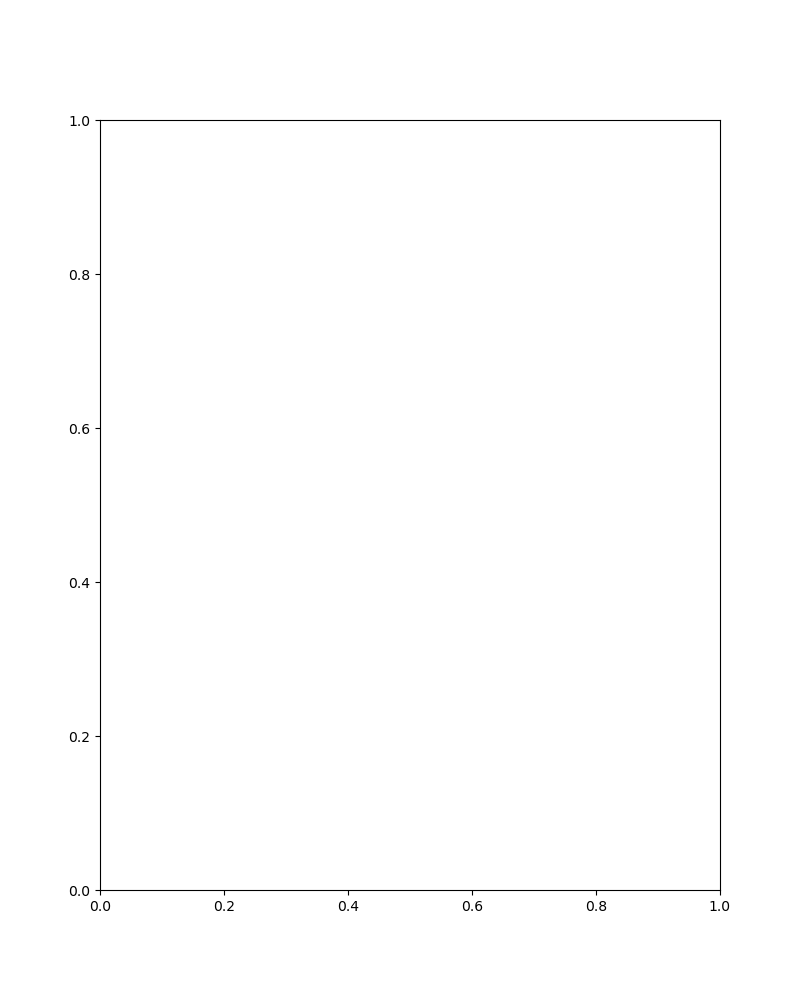

In [8]:
# --- 4b. ANALISI FFT LOG-LOG WATERFALL ---
import numpy as np
from scipy.fft import fft, fftfreq

fig_fft, ax_fft = plt.subplots(figsize=(8, 10))

fft_window_us = 300  # Finestra leggermente più ampia per migliorare la risoluzione in frequenza
fft_samples = int((fft_window_us / 1e6) * fs)

# In scala logaritmica, l'offset deve essere moltiplicativo per separare le tracce
# 10.0 significa che ogni traccia è traslata di un ordine di grandezza rispetto alla precedente
log_offset_factor = 10.0 

for i, (pick, d, name) in enumerate(zip(picks_ordered, dist_ordered, names_ordered)):
    data_idx = pick['ch'] - 2 
    if data_idx < 0 or data_idx >= len(data_chunk): continue
    
    # Estrazione segmento
    trace = data_chunk[data_idx]
    cp = int(pick['time'] * fs)
    segment = trace[cp : cp + fft_samples]
    
    if len(segment) < 64: continue # Evita segmenti troppo corti
    
    # Detrend e Finestra di Hanning per evitare leakage spettrale
    segment = (segment - np.mean(segment)) * np.hanning(len(segment))
    
    # Calcolo FFT
    n = len(segment)
    yf = fft(segment)
    xf = fftfreq(n, 1/fs)
    
    half = n // 2
    psd = 2.0/n * np.abs(yf[:half])
    freqs = xf[:half] 
    
    # Pulizia per il log: sostituiamo gli zeri con un valore minimo (noise floor)
    psd[psd <= 0] = 1e-10
    
    color = cmap(norm(d))
    
    # Moltiplichiamo per l'offset per distanziarli in scala logaritmica
    # L'ultima traccia (i=0) è in basso, la prima (i=max) in alto
    current_psd = psd * (log_offset_factor**i)
    
    ax_fft.loglog(freqs, current_psd, color=color, lw=1.2, alpha=0.8)
    
    # Etichetta: posizionata all'inizio dello spettro (es. a 10 kHz)
    ax_fft.text(800, current_psd[np.argmin(np.abs(freqs-10))], 
                f" {name}", fontsize=8, color=color, va='bottom')
    

ax_fft.set_title(f"FFT Log-Log Waterfall - Evento {res['event_id']}")
ax_fft.set_xlabel("Frequenza [kHz]")
ax_fft.set_ylabel("Ampiezza (Scaled Log-Offset)")

# Griglia specifica per log-log
ax_fft.grid(True, which="both", ls="-", alpha=0.2)

# Range tipico AE (es. da 10kHz a Nyquist)
ax_fft.set_xlim(500,1e6)

plt.tight_layout()
plt.show()

In [ ]:
min(freqs)

# Plots section

Saltando [Size: 1, Pos: [27.1, 8.5, 8.5], Drop: drop_3]: Impossibile trovare i file richiesti in: /home/oreios/Calibrations/pzt_calibration_alessia/Lower_block_results/data_ball_drop_1_[27.1, 8.5, 8.5]/drop_3
Grafico salvato con successo in: /mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/error_bars_lower_1.png


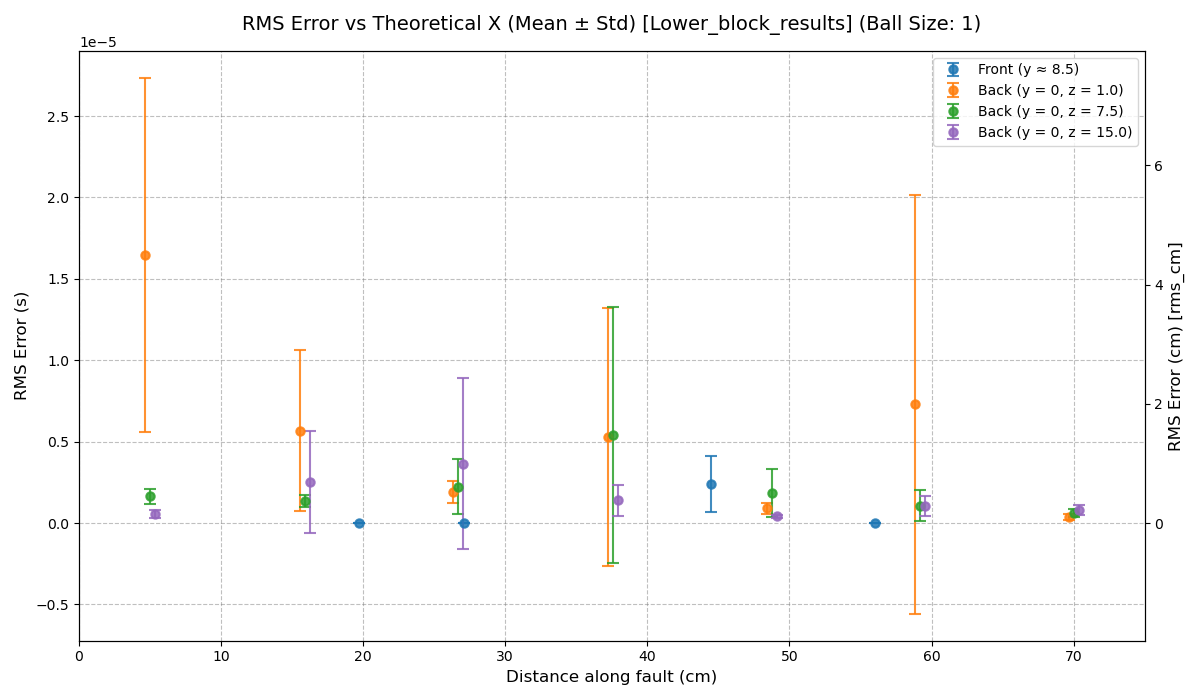

In [ ]:
def plot_block_results(directory, target_size=None):
    """
    Scans a block results directory, loads the localization result of every drop with
    `loadoutput`, aggregates the results over repeated drops that share the same theoretical
    position (x_theo, z_theo), and plots the mean RMS localization error with error bars
    (mean ± standard deviation) against the theoretical X position.

    The plot has two Y axes: the left axis shows the RMS error in seconds, the right axis
    shows the same error in centimetres. Drops are split into two groups according to the
    theoretical Y coordinate: those with y > 4.0 are plotted as "Front", those with
    y <= 4.0 as "Back". The Back group is further split by Z coordinate (one colour per Z).
    For the lower block only, the Back points of different Z values are shifted slightly
    along the X axis so that their error bars do not overlap.

    Requires os, pandas (as pd), matplotlib.pyplot (as plt) and the function `loadoutput`
    to be available.

    INPUT PARAMETERS:
    ----------------
    directory : str
        Block results directory (e.g. '.../Lower_block_results') containing the folders
        'data_ball_drop_<size>_<position>/<drop_N>/' written by `saveoutput` and `saveloc`.
        The text 'lower' or 'upper' in the path (case-insensitive) selects the X-axis range
        and whether the Z offset is applied.
    target_size : str or int, optional
        If given, only the drops of this ball size are processed; otherwise all sizes are used.
        It is also reported in the plot title.

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function saves the figure as a 300 dpi PNG in a fixed output folder and shows it.
        If no localization data is found, a message is printed and nothing is plotted.

    Raises:
    ------
    FileNotFoundError
        If `directory` does not exist.
    """
    # Stop immediately if the results directory does not exist
    if not os.path.exists(directory):
        raise FileNotFoundError(f"La directory specificata non esiste: {directory}")
        
    # List of dictionaries, one per drop; it is converted to a DataFrame later
    records = []
    
    # Scan the results directory: each 'data_ball_drop_<size>_<position>' folder holds one ball size and position
    for item in os.listdir(directory):
        if item.startswith('data_ball_drop_'):
            item_path = os.path.join(directory, item)
            if not os.path.isdir(item_path):
                continue
                
            # Recover ball size and position from the folder name: everything after the prefix
            # is split at the first underscore into <size> and <position>
            remainder = item[len('data_ball_drop_'):]
            parts = remainder.split('_', 1)
            if len(parts) != 2:
                continue
            size = parts[0]
            position = parts[1]
            
            # Apply the optional ball-size filter
            if target_size is not None and size != str(target_size):
                continue
                
            # List the drop sub-folders (names starting with 'drop') inside this size/position folder
            drop_list = [
                d for d in os.listdir(item_path)
                if os.path.isdir(os.path.join(item_path, d)) and d.startswith('drop')
            ]
            
            for dropN in drop_list:
                try:
                    # Load the saved files of this drop; only the localization dictionary
                    # (third output) is needed. Its keys are expected to include x_theo, y_theo,
                    # z_theo, rms_misfit and rms_cm.
                    _, _, localization = loadoutput(directory, position, size, dropN)
                    
                    # One record per drop: identifiers plus all localization values
                    record = {'size': size, 'position': position, 'drop': dropN}
                    record.update(localization)
                    records.append(record)
                except Exception as e:
                    # Drops with missing or unreadable files are skipped (with a message)
                    print(f"Saltando [Size: {size}, Pos: {position}, Drop: {dropN}]: {e}")
                    
    if not records:
        print("Nessun dato di localizzazione trovato nella directory specificata.")
        return

    # Tabulate all the drops and make sure the numeric columns are real numbers
    # (unparsable values become NaN)
    df = pd.DataFrame(records)
    
    df['x_theo'] = pd.to_numeric(df['x_theo'], errors='coerce')
    df['y_theo'] = pd.to_numeric(df['y_theo'], errors='coerce')
    
    # Explicit use of the theoretical Z coordinate; if it is not saved, Z is set to 0
    if 'z_theo' in df.columns:
        df['z_val'] = pd.to_numeric(df['z_theo'], errors='coerce')
    else:
        df['z_val'] = 0.0

    # RMS misfit in seconds and in centimetres
    df['rms_misfit'] = pd.to_numeric(df['rms_misfit'], errors='coerce')
    df['rms_cm'] = pd.to_numeric(df['rms_cm'], errors='coerce')

    # Split into Front (y > 4.0) and Back (y <= 4.0) groups according to the theoretical Y coordinate
    df_front = df[df['y_theo'] > 4.0]
    df_back = df[df['y_theo'] <= 4.0]

    # Aggregation function: groups the drops that share the same (x_theo, z_val) and computes
    # mean and standard deviation of the RMS error, in seconds and in cm
    def aggregate_data(sub_df):
        # Empty group: return an empty table with the expected columns
        if sub_df.empty:
            return pd.DataFrame(columns=['x_theo', 'z_val', 'rms_misfit_mean', 'rms_misfit_std', 'rms_cm_mean', 'rms_cm_std'])
        agg = sub_df.groupby(['x_theo', 'z_val']).agg({
            'rms_misfit': ['mean', 'std'],
            'rms_cm': ['mean', 'std']
        }).reset_index()
        # Flatten the two-level column names produced by the aggregation
        agg.columns = ['x_theo', 'z_val', 'rms_misfit_mean', 'rms_misfit_std', 'rms_cm_mean', 'rms_cm_std']
        # A position with a single drop has no standard deviation (NaN): set it to 0 (no error bar)
        agg['rms_misfit_std'] = agg['rms_misfit_std'].fillna(0)
        agg['rms_cm_std'] = agg['rms_cm_std'].fillna(0)
        return agg

    df_front_agg = aggregate_data(df_front)
    df_back_agg = aggregate_data(df_back)

    # Create the figure and the primary axis (ax1), used for the error in seconds
    fig, ax1 = plt.subplots(figsize=(12, 7))

    ax1.set_xlabel('Distance along fault (cm)', fontsize=12)
    ax1.set_ylabel('RMS Error (s)', fontsize=12)
    
    # Front group: mean ± std at each theoretical X position (single colour)
    if not df_front_agg.empty:
        ax1.errorbar(
            df_front_agg['x_theo'], df_front_agg['rms_misfit_mean'], 
            yerr=df_front_agg['rms_misfit_std'], 
            fmt='o', color='tab:blue', capsize=4, elinewidth=1.5, markeredgewidth=1.5,
            alpha=0.85, label='Front (y ≈ 8.5)'
        )

    # X-offset configuration for the back face of the lower block:
    # the block type is inferred from the directory name
    dir_lower = directory.lower()
    is_lower_block = 'lower' in dir_lower
    
    # Distinct Z values of the Back group (one colour and legend entry each) and the colour cycle
    unique_z_back = sorted(df_back_agg['z_val'].dropna().unique())
    color_palette = ['tab:orange', 'tab:green', 'tab:purple', 'tab:red', 'tab:brown', 'tab:pink']
    
    # Dynamic X offsets, centred on 0, for the different Z values (only for the Back group
    # of the lower block, where several Z values share the same X positions)
    z_offsets = {}
    if is_lower_block and len(unique_z_back) > 1:
        step = 0.35  # spacing (in cm on the X axis) between the error bars of adjacent Z values
        n = len(unique_z_back)
        for idx, z_val in enumerate(unique_z_back):
            z_offsets[z_val] = (idx - (n - 1) / 2) * step
    else:
        # No offset otherwise
        for z_val in unique_z_back:
            z_offsets[z_val] = 0.0

    # Back group: one series per Z value, with the X offset applied
    for i, z_val in enumerate(unique_z_back):
        sub_z = df_back_agg[df_back_agg['z_val'] == z_val]
        color = color_palette[i % len(color_palette)]
        offset = z_offsets.get(z_val, 0.0)
        
        ax1.errorbar(
            sub_z['x_theo'] + offset, sub_z['rms_misfit_mean'], 
            yerr=sub_z['rms_misfit_std'], 
            fmt='o', color=color, capsize=4, elinewidth=1.5, markeredgewidth=1.5,
            alpha=0.85, label=f'Back (y = 0, z = {z_val})'
        )

    ax1.tick_params(axis='y')
    ax1.grid(True, linestyle='--', alpha=0.5, color='gray')

    # X-axis limits depending on the block (inferred from the directory name):
    # 0-75 cm for the lower block, 0-81 cm for the upper block
    if 'lower' in dir_lower:
        ax1.set_xlim(0, 75)
    elif 'upper' in dir_lower:
        ax1.set_xlim(0, 81)

    # Create the secondary axis (ax2), sharing the X axis, for the error in centimetres
    ax2 = ax1.twinx()  
    ax2.set_ylabel('RMS Error (cm) [rms_cm]', fontsize=12)
    
    # The same data are drawn again with the values in cm, but fully transparent (alpha=0.0)
    # and without legend entries: they are invisible and only serve to set the scale of the
    # right-hand axis.
    if not df_front_agg.empty:
        ax2.errorbar(
            df_front_agg['x_theo'], df_front_agg['rms_cm_mean'], 
            yerr=df_front_agg['rms_cm_std'], 
            fmt='^', color='tab:blue', alpha=0.0, label='_nolegend_'
        )
        
    for i, z_val in enumerate(unique_z_back):
        sub_z = df_back_agg[df_back_agg['z_val'] == z_val]
        color = color_palette[i % len(color_palette)]
        offset = z_offsets.get(z_val, 0.0)
        
        ax2.errorbar(
            sub_z['x_theo'] + offset, sub_z['rms_cm_mean'], 
            yerr=sub_z['rms_cm_std'], 
            fmt='^', color=color, alpha=0.0, label='_nolegend_'
        )

    ax2.tick_params(axis='y')

    # Legend: only the visible series of the primary axis are listed (ax2 entries are hidden)
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    ax1.legend(lines_1, labels_1, loc='best', fontsize=10)

    # Title: block name taken from the last component of the directory path, plus the ball size if given
    size_title = f' (Ball Size: {target_size})' if target_size else ''
    block_name = os.path.basename(os.path.normpath(directory))
    plt.title(f'RMS Error vs Theoretical X (Mean ± Std) [{block_name}]{size_title}', fontsize=14, pad=15)
    fig.tight_layout()
    # Saving
    # Fixed output folder (created if it does not exist)
    output_dir = "/mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia"
    if not os.path.exists(output_dir):
        os.makedirs(output_dir, exist_ok=True)

    # Save as a 300 dpi PNG; the file name contains 'lower' and the ball size
    filepath = os.path.join(output_dir, f"error_bars_lower_{target_size}.png")
    plt.savefig(filepath, format="png", dpi=300, bbox_inches="tight")
    print(f"Grafico salvato con successo in: {filepath}")
    plt.show()

# --- Usage example ---
# Plot the localization error of the lower block for the drops made with the ball of size '1'
plot_block_results(
    directory='/home/oreios/Calibrations/pzt_calibration_alessia/Lower_block_results', 
    target_size='1'
)

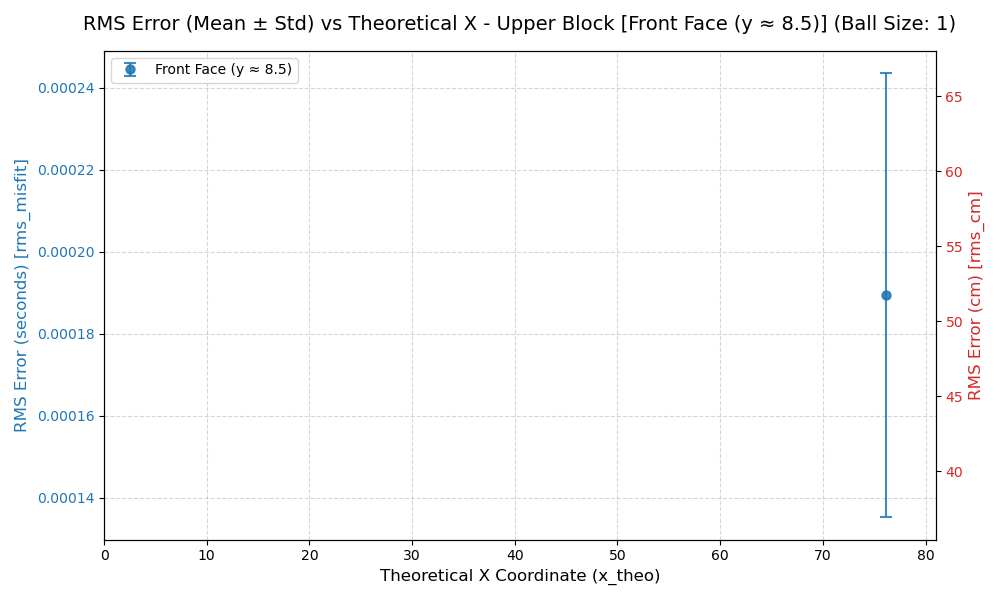

In [ ]:
def plot_single_face_dual_axis(directory, target_size=None, face='front'):
    """
    Plots the RMS localization error against the theoretical X position, with error bars
    (mean ± standard deviation over repeated drops), for ONE block directory and ONE face
    of the block ('front' or 'back').

    The error is shown in seconds on the left Y axis. The right Y axis shows the same error
    in centimetres: its data are drawn fully transparent and only serve to build the scale
    of that axis. The figure is displayed on screen but NOT saved to disk.

    Drops are assigned to a face using the theoretical Y coordinate: y > 4.0 is "front"
    and y <= 4.0 is "back". Results are aggregated by x_theo only, so drops made at the same
    X but at different Z are averaged together.

    Requires os, pandas (as pd), matplotlib.pyplot (as plt) and the function `loadoutput`
    to be available.

    INPUT PARAMETERS:
    ----------------
    directory : str
        Block results directory (e.g. '.../Upper_block_results') containing the folders
        'data_ball_drop_<size>_<position>/<drop_N>/' written by `saveoutput` and `saveloc`.
        The text 'lower' or 'upper' in the path (case-insensitive) selects the X-axis range
        and the block name shown in the title.
    target_size : str or int, optional
        If given, only the drops of this ball size are processed; otherwise all sizes are
        used. It is also reported in the plot title.
    face : str
        Face of the block to plot: 'front' (y > 4.0) or 'back' (y <= 4.0), case-insensitive.

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function only shows the figure. If no localization data is found, or no drop
        matches the selected face, a message is printed and nothing is plotted.

    Raises:
    ------
    FileNotFoundError
        If `directory` does not exist.
    ValueError
        If `face` is neither 'front' nor 'back'.
    """
    # Stop immediately if the results directory does not exist
    if not os.path.exists(directory):
        raise FileNotFoundError(f"La directory specificata non esiste: {directory}")
        
    # List of dictionaries, one per drop; it is converted to a DataFrame later
    records = []
    
    # Scan the results directory: each 'data_ball_drop_<size>_<position>' folder holds one ball size and position
    for item in os.listdir(directory):
        if item.startswith('data_ball_drop_'):
            item_path = os.path.join(directory, item)
            if not os.path.isdir(item_path):
                continue
                
            # Recover ball size and position from the folder name: everything after the prefix
            # is split at the first underscore into <size> and <position>
            remainder = item[len('data_ball_drop_'):]
            parts = remainder.split('_', 1)
            if len(parts) != 2:
                continue
            size = parts[0]
            position = parts[1]
            
            # Apply the optional ball-size filter
            if target_size is not None and size != str(target_size):
                continue
                
            # List the drop sub-folders (names starting with 'drop') inside this size/position folder
            drop_list = [
                d for d in os.listdir(item_path)
                if os.path.isdir(os.path.join(item_path, d)) and d.startswith('drop')
            ]
            
            for dropN in drop_list:
                try:
                    # Load the saved files of this drop; only the localization dictionary
                    # (third output) is needed. Its keys are expected to include x_theo, y_theo,
                    # rms_misfit and rms_cm.
                    _, _, localization = loadoutput(directory, position, size, dropN)
                    # One record per drop: identifiers plus all localization values
                    record = {'size': size, 'position': position, 'drop': dropN}
                    record.update(localization)
                    records.append(record)
                except Exception as e:
                    # Drops with missing or unreadable files are skipped silently (no message is printed)
                    pass
                    
    if not records:
        print("Nessun dato di localizzazione trovato nella directory specificata.")
        return

    # Tabulate all the drops and make sure the numeric columns are real numbers
    # (unparsable values become NaN)
    df = pd.DataFrame(records)
    df['x_theo'] = pd.to_numeric(df['x_theo'], errors='coerce')
    df['y_theo'] = pd.to_numeric(df['y_theo'], errors='coerce')
    # RMS misfit in seconds and in centimetres
    df['rms_misfit'] = pd.to_numeric(df['rms_misfit'], errors='coerce')
    df['rms_cm'] = pd.to_numeric(df['rms_cm'], errors='coerce')

    # Keep only the drops of the chosen face, selected with the theoretical Y coordinate,
    # and prepare the label used in the legend and in the title
    face_lower = face.lower()
    if face_lower == 'front':
        df_filtered = df[df['y_theo'] > 4.0]
        face_label = 'Front Face (y ≈ 8.5)'
    elif face_lower == 'back':
        df_filtered = df[df['y_theo'] <= 4.0]
        face_label = 'Back Face (y = 0)'
    else:
        raise ValueError("Il parametro 'face' deve essere 'front' o 'back'.")

    if df_filtered.empty:
        print("Nessun dato corrispondente al filtro della faccia specificato.")
        return

    # Aggregation by x_theo: mean and standard deviation of the RMS error (in seconds and in cm)
    # over all the drops made at the same theoretical X position
    agg = df_filtered.groupby('x_theo').agg({
        'rms_misfit': ['mean', 'std'],
        'rms_cm': ['mean', 'std']
    }).reset_index()
    # Flatten the two-level column names produced by the aggregation
    agg.columns = ['x_theo', 'rms_misfit_mean', 'rms_misfit_std', 'rms_cm_mean', 'rms_cm_std']
    # A position with a single drop has no standard deviation (NaN): set it to 0 (no error bar)
    agg['rms_misfit_std'] = agg['rms_misfit_std'].fillna(0)
    agg['rms_cm_std'] = agg['rms_cm_std'].fillna(0)

    # Create the figure with the primary axis (ax1), used for the error in seconds
    fig, ax1 = plt.subplots(figsize=(10, 6))

    ax1.set_xlabel('Theoretical X Coordinate (x_theo)', fontsize=12)
    ax1.set_ylabel('RMS Error (seconds) [rms_misfit]', fontsize=12, color='tab:blue')
    
    # Error bar plot of the error in seconds on the left axis: points = mean, bars = ± standard deviation
    ax1.errorbar(
        agg['x_theo'], agg['rms_misfit_mean'], 
        yerr=agg['rms_misfit_std'], 
        fmt='o', color='tab:blue', capsize=4, elinewidth=1.5, markeredgewidth=1.5,
        alpha=0.85, label=f'{face_label}'
    )
    ax1.tick_params(axis='y', labelcolor='tab:blue')

    # X-axis limits and block name depending on the block (inferred from the directory name):
    # 0-75 cm for the lower block, 0-81 cm for the upper block. For any other directory the
    # limits are left automatic and the block name is the last component of the path.
    dir_lower = directory.lower()
    if 'lower' in dir_lower:
        ax1.set_xlim(0, 75)
        block_name = 'Lower Block'
    elif 'upper' in dir_lower:
        ax1.set_xlim(0, 81)
        block_name = 'Upper Block'
    else:
        block_name = os.path.basename(os.path.normpath(directory))

    # Create the secondary axis (ax2), sharing the X axis, for the error in centimetres
    ax2 = ax1.twinx()  
    ax2.set_ylabel('RMS Error (cm) [rms_cm]', fontsize=12, color='tab:red')
    
    # Error bar plot of the error in centimetres on the right axis. It is fully transparent
    # (alpha=0.0) and has no legend entry: it is invisible and only keeps the right-hand axis scaled.
    ax2.errorbar(
        agg['x_theo'], agg['rms_cm_mean'], 
        yerr=agg['rms_cm_std'], 
        fmt='^', color='tab:red', alpha=0.0, label='_nolegend_'
    )
    ax2.tick_params(axis='y', labelcolor='tab:red')

    # Legend (only the visible series of the primary axis) and title with block, face and ball size
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    ax1.legend(lines_1, labels_1, loc='upper left', fontsize=10)

    size_title = f' (Ball Size: {target_size})' if target_size else ''
    plt.title(f'RMS Error (Mean ± Std) vs Theoretical X - {block_name} [{face_label}]{size_title}', fontsize=14, pad=15)
    
    ax1.grid(True, linestyle='--', alpha=0.5)
    fig.tight_layout()
    plt.show()

# --- Usage example ---
# Plot the localization error of the front face of the upper block for the drops made with the ball of size '1'
plot_single_face_dual_axis(
    directory='/home/oreios/Calibrations/pzt_calibration_alessia/Upper_block_results', 
    target_size='1',
    face='front'
)

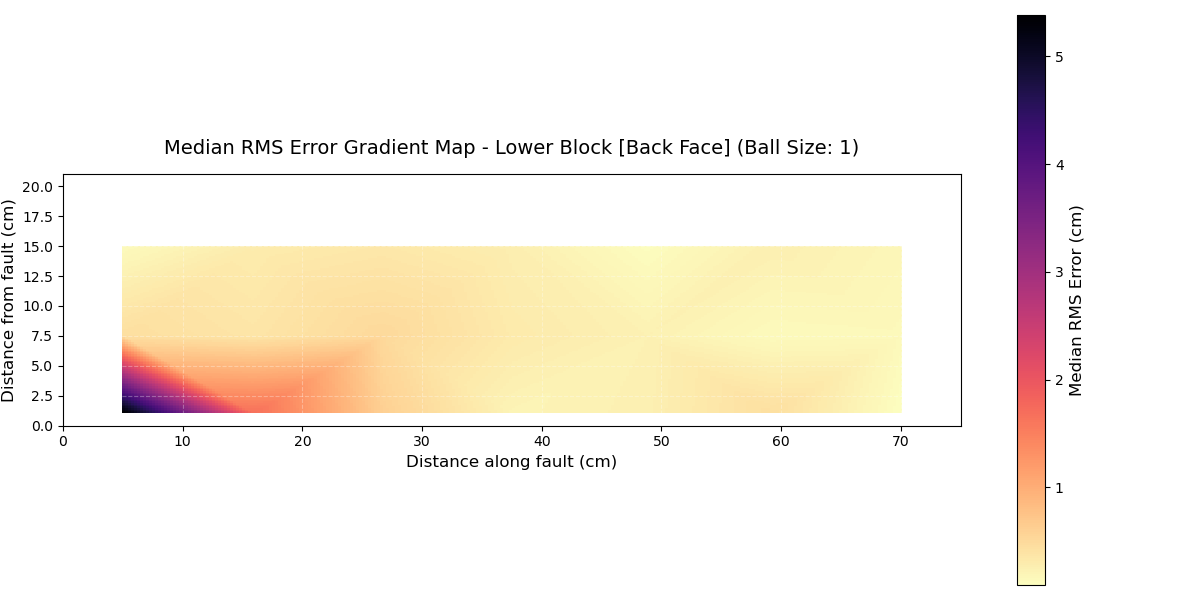

In [ ]:
def plot_face_colormap_gradient(
    directory, target_size=None, face="front", rms_metric="rms_misfit"
):
  """Plots a continuous colormap gradient of the median RMS localization error as a function

  of the theoretical X position (x-axis) and the theoretical Z position (y-axis) for a
  single face of a block, with equal aspect ratio.

  For every theoretical (x, z) position the median of the RMS error over the repeated drops
  is computed; these median values are then linearly interpolated onto a regular 300 x 150
  grid and drawn as a continuous colour map. Regions outside the convex hull of the measured
  positions cannot be interpolated and are left empty (NaN). The figure is displayed on
  screen but NOT saved to disk.

  Drops are assigned to a face using the theoretical Y coordinate: y > 4.0 is "front"
  and y <= 4.0 is "back".

  Requires os, numpy (as np), pandas (as pd), matplotlib.pyplot (as plt),
  scipy.interpolate.griddata and the function `loadoutput` to be available.

  INPUT PARAMETERS:
  ----------------
  directory : str
      Block results directory (e.g. '.../Lower_block_results') containing the folders
      'data_ball_drop_<size>_<position>/<drop_N>/' written by `saveoutput` and `saveloc`.
      The text 'lower' or 'upper' in the path (case-insensitive) selects the X-axis range
      and the block name shown in the title.
  target_size : str or int, optional
      If given, only the drops of this ball size are processed; otherwise all sizes are used.
      It is also reported in the plot title.
  face : str
      Face of the block to plot: 'front' (y > 4.0) or 'back' (y <= 4.0), case-insensitive.
  rms_metric : str
      Name of the localization column to map: 'rms_misfit' (seconds) or 'rms_cm'
      (centimetres). If the name contains 'cm' the colorbar unit is cm, otherwise s.

  OUTPUT PARAMETERS:
  -----------------
  None : void
      The function only shows the figure. If no localization data is found, or no drop
      matches the selected face, a message is printed and nothing is plotted.

  Raises:
  ------
  FileNotFoundError
      If `directory` does not exist.
  ValueError
      If `face` is neither 'front' nor 'back'.
  """
  # Stop immediately if the results directory does not exist
  if not os.path.exists(directory):
    raise FileNotFoundError(
        f"La directory specificata non esiste: {directory}"
    )

  # List of dictionaries, one per drop; it is converted to a DataFrame later
  records = []

  # Scan the results directory: each 'data_ball_drop_<size>_<position>' folder holds one ball size and position
  for item in os.listdir(directory):
    if item.startswith("data_ball_drop_"):
      item_path = os.path.join(directory, item)
      if not os.path.isdir(item_path):
        continue

      # Recover ball size and position from the folder name: everything after the prefix
      # is split at the first underscore into <size> and <position>
      remainder = item[len("data_ball_drop_") :]
      parts = remainder.split("_", 1)
      if len(parts) != 2:
        continue
      size = parts[0]
      position = parts[1]

      # Apply the optional ball-size filter
      if target_size is not None and size != str(target_size):
        continue

      # List the drop sub-folders (names starting with 'drop') inside this size/position folder
      drop_list = [
          d
          for d in os.listdir(item_path)
          if os.path.isdir(os.path.join(item_path, d)) and d.startswith("drop")
      ]

      for dropN in drop_list:
        try:
          # Load the saved files of this drop; only the localization dictionary (third output)
          # is needed. Its keys are expected to include x_theo, y_theo, z_theo, rms_misfit and rms_cm.
          _, _, localization = loadoutput(directory, position, size, dropN)
          # One record per drop: identifiers plus all localization values
          record = {"size": size, "position": position, "drop": dropN}
          record.update(localization)
          records.append(record)
        except Exception:
          # Drops with missing or unreadable files are skipped silently (no message is printed)
          pass

  if not records:
    print("Nessun dato di localizzazione trovato nella directory specificata.")
    return

  # Tabulate all the drops and make sure the numeric columns are real numbers
  # (unparsable values become NaN)
  df = pd.DataFrame(records)
  df["x_theo"] = pd.to_numeric(df["x_theo"], errors="coerce")
  df["y_theo"] = pd.to_numeric(df["y_theo"], errors="coerce")
  df["z_theo"] = pd.to_numeric(df["z_theo"], errors="coerce")
  df["rms_misfit"] = pd.to_numeric(df["rms_misfit"], errors="coerce")
  df["rms_cm"] = pd.to_numeric(df["rms_cm"], errors="coerce")

  # Keep only the drops of the chosen face, selected with the theoretical Y coordinate,
  # and prepare the label used in the title
  face_lower = face.lower()
  if face_lower == "front":
    df_filtered = df[df["y_theo"] > 4.0]
    face_label = "Front Face"
  elif face_lower == "back":
    df_filtered = df[df["y_theo"] <= 4.0]
    face_label = "Back Face"
  else:
    raise ValueError("Il parametro 'face' deve essere 'front' o 'back'.")

  # Discard drops with a missing X, Z or error value
  df_filtered = df_filtered.dropna(subset=["x_theo", "z_theo", rms_metric])

  if df_filtered.empty:
    print("Nessun dato corrispondente al filtro della faccia specificato.")
    return

  # --- MODIFICATION: aggregation by theoretical coordinates using the median RMS ---
  # One value per (x_theo, z_theo) position: the median over the repeated drops
  # (the median is less sensitive to outliers than the mean)
  agg_df = (
      df_filtered.groupby(["x_theo", "z_theo"])[rms_metric]
      .median()
      .reset_index()
  )

  # Extract the coordinates and the median values to be interpolated
  points = agg_df[["x_theo", "z_theo"]].values
  values = agg_df[rms_metric].values

  # Plot limits and block name depending on the block (inferred from the directory name):
  # 0-75 cm for the lower block, 0-81 cm for the upper block. For any other directory the
  # X range is taken from the data and the block name is the last component of the path.
  dir_lower = directory.lower()
  if "lower" in dir_lower:
    x_limits = (0, 75)
    block_name = "Lower Block"
  elif "upper" in dir_lower:
    x_limits = (0, 81)
    block_name = "Upper Block"
  else:
    x_limits = (agg_df["x_theo"].min(), agg_df["x_theo"].max())
    block_name = os.path.basename(os.path.normpath(directory))

  # Fixed Z range of the plot (cm)
  z_limits = (0, 21)

  # Create the regular grid for the gradient: 300 points along X and 150 along Z
  # (the complex step 300j means "300 points, end included")
  grid_x, grid_z = np.mgrid[
      x_limits[0] : x_limits[1] : 300j, z_limits[0] : z_limits[1] : 150j
  ]

  # Linear interpolation of the median values onto the regular grid
  # (NaN outside the convex hull of the measured positions)
  grid_v = griddata(points, values, (grid_x, grid_z), method="linear")

  # Create the figure
  fig, ax = plt.subplots(figsize=(12, 6))

  # Draw the continuous gradient with pcolormesh (reversed 'magma' colormap)
  c = ax.pcolormesh(grid_x, grid_z, grid_v, shading="auto", cmap="magma_r")

  # Colorbar: the unit is cm if the metric name contains 'cm', otherwise seconds
  unit = "cm" if "cm" in rms_metric.lower() else "s"
  cbar = plt.colorbar(c, ax=ax)
  cbar.set_label(f"Median RMS Error ({unit})", fontsize=12)

  # Set the axis limits and an equal (1:1) aspect ratio so that distances are not distorted
  ax.set_xlim(x_limits)
  ax.set_ylim(z_limits)
  ax.set_aspect("equal", adjustable="box")

  ax.set_xlabel("Distance along fault (cm)", fontsize=12)
  ax.set_ylabel("Distance from fault (cm)", fontsize=12)

  # Title with block, face and (if given) ball size
  size_title = f" (Ball Size: {target_size})" if target_size else ""
  plt.title(
      f"Median RMS Error Gradient Map - {block_name} [{face_label}]{size_title}",
      fontsize=14,
      pad=15,
  )

  # White dashed grid, visible on top of the dark colours
  ax.grid(True, linestyle="--", alpha=0.3, color="white")
  fig.tight_layout()
  plt.show()


# --- Usage example ---
# Median RMS error (in cm) map for the back face of the lower block, drops made with the ball of size '1'
plot_face_colormap_gradient(
    directory=(
        "/home/oreios/Calibrations/pzt_calibration_alessia/Lower_block_results"
    ),
    target_size="1",
    face="back",
    rms_metric="rms_cm",
)

Grafico salvato con successo in: /mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/map_back_sizes_3_and_1.png


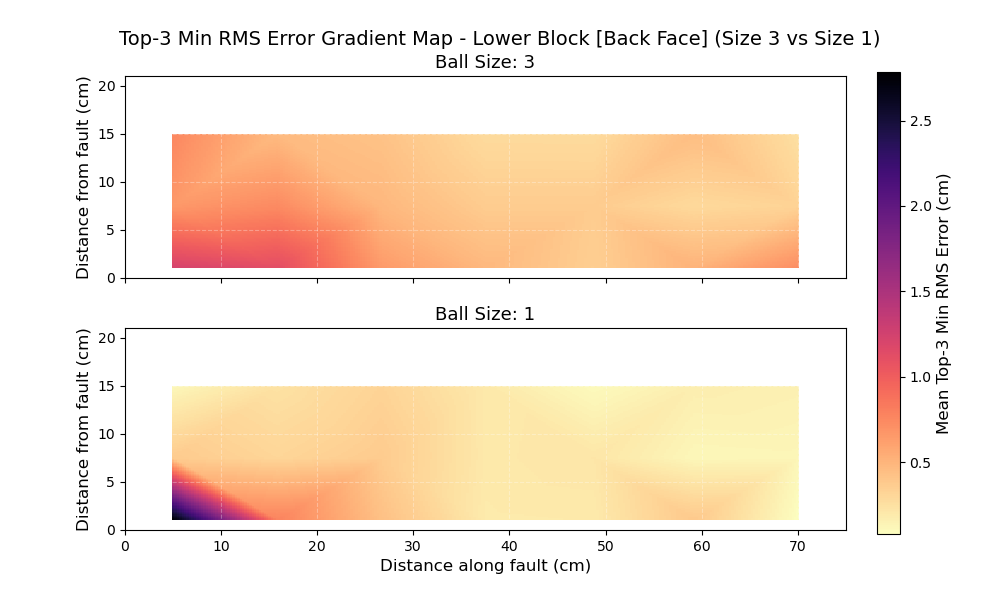

In [ ]:
def plot_face_colormap_gradient_comparison(
    directory, face="front", rms_metric="rms_misfit"
):
  """Plots continuous colormap gradients of the RMS localization error for ball size 3

  and ball size 1 as two vertically stacked subplots of a single figure, sharing the same
  colour scale so that the two maps can be compared directly.

  For every theoretical (x, z) position the value shown is the MEAN OF THE 3 SMALLEST RMS
  errors among the repeated drops at that position (a "best three" statistic, not the
  median or the mean of all drops). These values are linearly interpolated onto a regular
  300 x 150 grid; regions outside the convex hull of the measured positions are left empty
  (NaN). The figure is saved as a 300 dpi PNG and displayed on screen.

  The ball sizes ("3" and "1") are hard-coded. Drops are assigned to a face using the
  theoretical Y coordinate: y > 4.0 is "front" and y <= 4.0 is "back".

  Requires os, numpy (as np), pandas (as pd), matplotlib.pyplot (as plt),
  scipy.interpolate.griddata and the function `loadoutput` to be available.

  INPUT PARAMETERS:
  ----------------
  directory : str
      Block results directory (e.g. '.../Lower_block_results') containing the folders
      'data_ball_drop_<size>_<position>/<drop_N>/' written by `saveoutput` and `saveloc`.
      The text 'lower' or 'upper' in the path (case-insensitive) selects the X-axis range
      and the block name shown in the title.
  face : str
      Face of the block to plot: 'front' (y > 4.0) or 'back' (y <= 4.0), case-insensitive.
  rms_metric : str
      Name of the localization column to map: 'rms_misfit' (seconds) or 'rms_cm'
      (centimetres). If the name contains 'cm' the colorbar unit is cm, otherwise s.

  OUTPUT PARAMETERS:
  -----------------
  None : void
      The function saves '<output_dir>/map_<face>_sizes_3_and_1.png' (fixed output folder)
      and shows the figure. If no data is found, or no drop matches the selected face, a
      message is printed and nothing is plotted.

  Raises:
  ------
  FileNotFoundError
      If `directory` does not exist.
  ValueError
      If `face` is neither 'front' nor 'back'.
  """
  # Stop immediately if the results directory does not exist
  if not os.path.exists(directory):
    raise FileNotFoundError(
        f"La directory specificata non esiste: {directory}"
    )

  # List of dictionaries, one per drop; it is converted to a DataFrame later
  records = []

  # Scan the results directory: each 'data_ball_drop_<size>_<position>' folder holds one ball size and position
  for item in os.listdir(directory):
    if item.startswith("data_ball_drop_"):
      item_path = os.path.join(directory, item)
      if not os.path.isdir(item_path):
        continue

      # Recover ball size and position from the folder name: everything after the prefix
      # is split at the first underscore into <size> and <position>
      remainder = item[len("data_ball_drop_") :]
      parts = remainder.split("_", 1)
      if len(parts) != 2:
        continue
      size = parts[0]
      position = parts[1]

      # We keep only ball sizes 3 and 1
      if size not in ["3", "1"]:
        continue

      # List the drop sub-folders (names starting with 'drop') inside this size/position folder
      drop_list = [
          d
          for d in os.listdir(item_path)
          if os.path.isdir(os.path.join(item_path, d)) and d.startswith("drop")
      ]

      for dropN in drop_list:
        try:
          # Load the saved files of this drop; only the localization dictionary (third output)
          # is needed. Its keys are expected to include x_theo, y_theo, z_theo, rms_misfit and rms_cm.
          _, _, localization = loadoutput(directory, position, size, dropN)
          # One record per drop: identifiers plus all localization values
          record = {"size": size, "position": position, "drop": dropN}
          record.update(localization)
          records.append(record)
        except Exception:
          # Drops with missing or unreadable files are skipped silently (no message is printed)
          pass

  if not records:
    print("Nessun dato di localizzazione trovato nella directory specificata.")
    return

  # Tabulate all the drops and make sure the numeric columns are real numbers
  # (unparsable values become NaN)
  df = pd.DataFrame(records)
  df["x_theo"] = pd.to_numeric(df["x_theo"], errors="coerce")
  df["y_theo"] = pd.to_numeric(df["y_theo"], errors="coerce")
  df["z_theo"] = pd.to_numeric(df["z_theo"], errors="coerce")
  df["rms_misfit"] = pd.to_numeric(df["rms_misfit"], errors="coerce")
  df["rms_cm"] = pd.to_numeric(df["rms_cm"], errors="coerce")

  # Keep only the drops of the chosen face, selected with the theoretical Y coordinate,
  # and prepare the label used in the title
  face_lower = face.lower()
  if face_lower == "front":
    df_filtered = df[df["y_theo"] > 4.0]
    face_label = "Front Face"
  elif face_lower == "back":
    df_filtered = df[df["y_theo"] <= 4.0]
    face_label = "Back Face"
  else:
    raise ValueError("Il parametro 'face' deve essere 'front' o 'back'.")

  # Discard drops with a missing X, Z, error value or ball size
  df_filtered = df_filtered.dropna(
      subset=["x_theo", "z_theo", rms_metric, "size"]
  )

  if df_filtered.empty:
    print("Nessun dato corrispondente al filtro della faccia specificato.")
    return

  # Plot limits and block name depending on the block (inferred from the directory name):
  # 0-75 cm for the lower block, 0-81 cm for the upper block. For any other directory the
  # X range is taken from the data and the block name is the last component of the path.
  dir_lower = directory.lower()
  if "lower" in dir_lower:
    x_limits = (0, 75)
    block_name = "Lower Block"
  elif "upper" in dir_lower:
    x_limits = (0, 81)
    block_name = "Upper Block"
  else:
    x_limits = (df_filtered["x_theo"].min(), df_filtered["x_theo"].max())
    block_name = os.path.basename(os.path.normpath(directory))

  # Fixed Z range of the plot (cm)
  z_limits = (0, 21)

  # Create the regular grid for the gradient: 300 points along X and 150 along Z
  # (the complex step 300j means "300 points, end included"); shared by both ball sizes
  grid_x, grid_z = np.mgrid[
      x_limits[0] : x_limits[1] : 300j, z_limits[0] : z_limits[1] : 150j
  ]

  # Data processing: extract the interpolated grid for each ball size.
  # grid_v_dict: {size: interpolated grid, or None if there is no data for that size}
  # all_values: all the aggregated values of both sizes, used to set the common colour range
  grid_v_dict = {}
  all_values = []

  for size_val in ["3", "1"]:
    df_size = df_filtered[df_filtered["size"] == size_val]
    if df_size.empty:
      grid_v_dict[size_val] = None
      continue

    # One value per (x_theo, z_theo) position: the mean of the 3 smallest RMS errors among the
    # repeated drops at that position (if fewer than 3 drops exist, the mean of all of them).
    # Note that this selects the best drops, so it describes the best achievable accuracy
    # rather than the typical error.
    agg_df = (
        df_size.groupby(["x_theo", "z_theo"])[rms_metric]
        .apply(lambda s: s.nsmallest(3).mean())
        .reset_index()
    )

    # Coordinates and aggregated values to be interpolated
    points = agg_df[["x_theo", "z_theo"]].values
    values = agg_df[rms_metric].values

    # Linear interpolation onto the regular grid (NaN outside the convex hull of the measured positions)
    grid_v = griddata(points, values, (grid_x, grid_z), method="linear")
    grid_v_dict[size_val] = grid_v
    all_values.extend(values[~np.isnan(values)])

  if not all_values:
    print("Nessun valore valido trovato per l'interpolazione.")
    return

  # Global minimum and maximum over both ball sizes, so that both maps use the same colour scale
  vmin = min(all_values)
  vmax = max(all_values)

  # Create the figure with 2 vertical subplots (2 rows, 1 column) sharing the X axis
  fig, axes = plt.subplots(
      2, 1, figsize=(10, 6), sharex=True
  )  # Changed to 2,1 and sharex=True
  # Panel order: ball size 3 on top, ball size 1 at the bottom
  sizes_to_plot = ["3", "1"]

  # Keeps a reference to the last mesh drawn, used to build the shared colorbar
  c_mesh = None
  for ax, size_val in zip(axes, sizes_to_plot):
    grid_v = grid_v_dict.get(size_val)
    # Draw the map only if there is data for this size (otherwise the panel stays empty)
    if grid_v is not None:
      c_mesh = ax.pcolormesh(
          grid_x,
          grid_z,
          grid_v,
          shading="auto",
          cmap="magma_r",
          vmin=vmin,
          vmax=vmax,
      )
    ax.set_xlim(x_limits)
    ax.set_ylim(z_limits)
    # Equal (1:1) aspect ratio so that distances are not distorted
    ax.set_aspect("equal", adjustable="box")
    ax.set_ylabel(
        "Distance from fault (cm)", fontsize=12
    )  # Now both y-axes show the label
    ax.set_title(f"Ball Size: {size_val}", fontsize=13)
    ax.grid(True, linestyle="--", alpha=0.3, color="white")

  # Add the X-axis label only on the bottom plot
  axes[1].set_xlabel("Distance along fault (cm)", fontsize=12)

  # Vertical spacing between the two plots (currently disabled)
  #fig.subplots_adjust(hspace=0.1)  # Increase or decrease this value to change the vertical space

  # Shared colorbar (placed on the right): the unit is cm if the metric name contains 'cm', otherwise seconds
  unit = "cm" if "cm" in rms_metric.lower() else "s"
  cbar = fig.colorbar(
      c_mesh, ax=axes, orientation="vertical", fraction=0.03, pad=0.04
  )
  cbar.set_label(f"Mean Top-3 Min RMS Error ({unit})", fontsize=12)

  # Overall figure title with block and face
  plt.suptitle(
      f"Top-3 Min RMS Error Gradient Map - {block_name} [{face_label}] (Size 3 vs"
      " Size 1)",
      fontsize=14,
      y=0.95,
  )

  # Saving
  # Fixed output folder (created if it does not exist)
  output_dir = "/mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia"
  if not os.path.exists(output_dir):
    os.makedirs(output_dir, exist_ok=True)

  # Save as a 300 dpi PNG; the file name contains only the face and the two ball sizes
  filepath = os.path.join(output_dir, f"map_{face}_sizes_3_and_1.png")
  plt.savefig(filepath, format="png", dpi=300, bbox_inches="tight")
  print(f"Grafico salvato con successo in: {filepath}")
  plt.show()


# --- Usage example ---
# Comparison of the error maps (in cm) of ball sizes 3 and 1 for the back face of the lower block
plot_face_colormap_gradient_comparison(
    directory=(
        "/home/oreios/Calibrations/pzt_calibration_alessia/Lower_block_results"
    ),
    face="back",
    rms_metric="rms_cm",
)

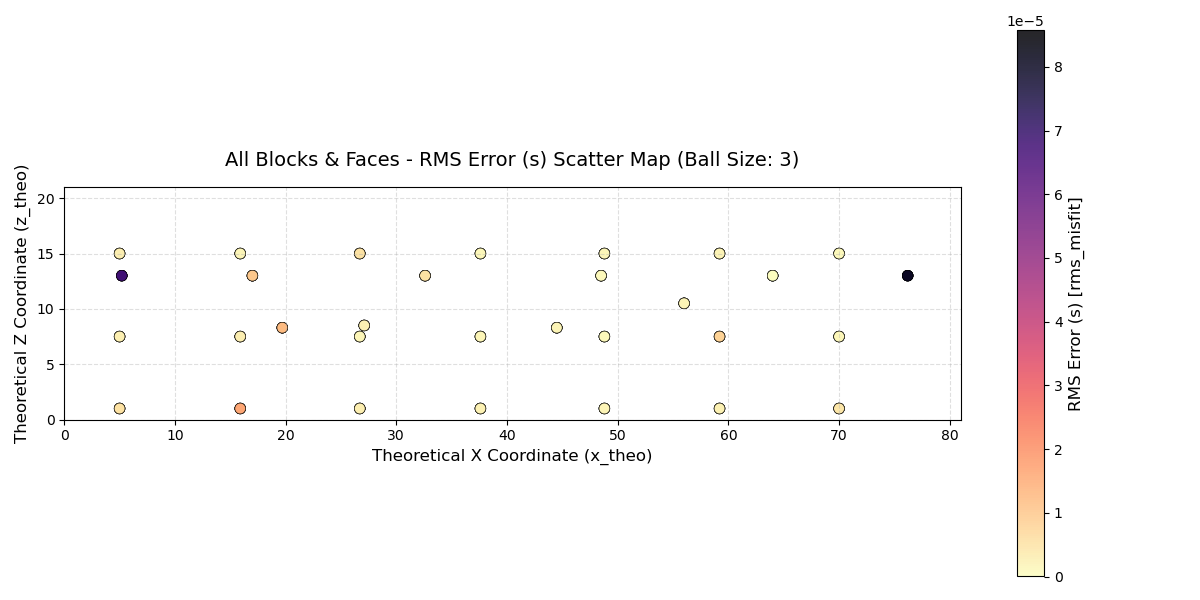

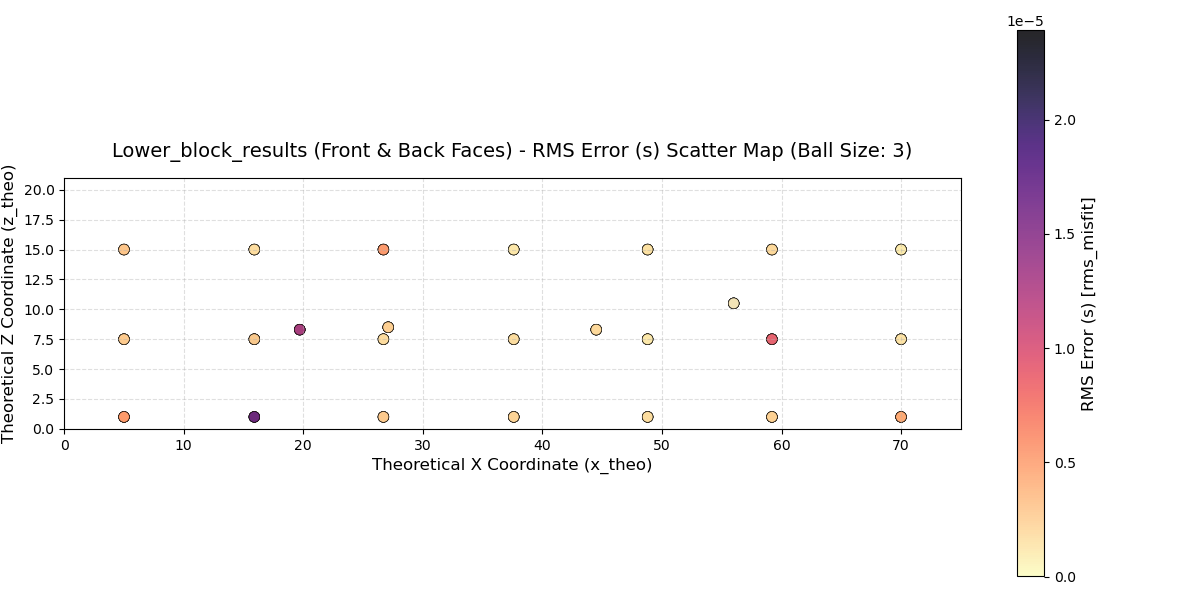

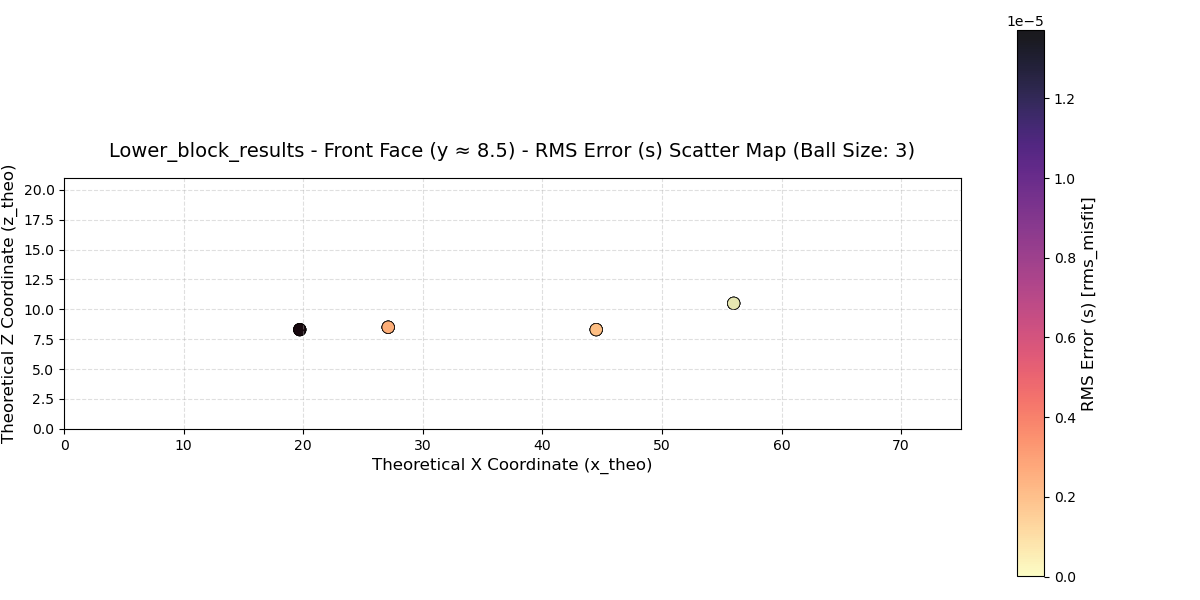

In [ ]:
def collect_block_data(directory):
    """
    Scans a block results directory and returns a pandas DataFrame with one row per drop,
    containing the localization results of all the ball sizes and positions found.

    Each row holds the block name (last component of the directory path), the ball size, the
    position string, the drop identifier and all the values of the saved localization file
    (e.g. x_theo, y_theo, z_theo, rms_misfit, rms_cm). The numeric columns are converted to
    numbers (unparsable values become NaN). Drops whose files are missing or unreadable are
    skipped silently.

    Requires os, pandas (as pd) and the function `loadoutput` to be available.

    INPUT PARAMETERS:
    ----------------
    directory : str
        Block results directory (e.g. '.../Lower_block_results') containing the folders
        'data_ball_drop_<size>_<position>/<drop_N>/' written by `saveoutput` and `saveloc`.

    OUTPUT PARAMETERS:
    -----------------
    df : pandas.DataFrame
        One row per drop. An empty DataFrame (no columns) is returned if the directory does
        not exist or no drop could be loaded.
    """
    # Return an empty table if the directory does not exist
    if not os.path.exists(directory):
        return pd.DataFrame()
        
    # List of dictionaries, one per drop; it is converted to a DataFrame later
    records = []
    # Block name taken from the last component of the directory path (e.g. 'Lower_block_results')
    block_name = os.path.basename(os.path.normpath(directory))
    
    # Scan the results directory: each 'data_ball_drop_<size>_<position>' folder holds one ball size and position
    for item in os.listdir(directory):
        if item.startswith('data_ball_drop_'):
            item_path = os.path.join(directory, item)
            if not os.path.isdir(item_path):
                continue
                
            # Recover ball size and position from the folder name: everything after the prefix
            # is split at the first underscore into <size> and <position>
            remainder = item[len('data_ball_drop_'):]
            parts = remainder.split('_', 1)
            if len(parts) != 2:
                continue
            size = parts[0]
            position = parts[1]
            
            # List the drop sub-folders (names starting with 'drop') inside this size/position folder
            drop_list = [
                d for d in os.listdir(item_path)
                if os.path.isdir(os.path.join(item_path, d)) and d.startswith('drop')
            ]
            
            for dropN in drop_list:
                try:
                    # Load the saved files of this drop; only the localization dictionary
                    # (third output) is needed
                    _, _, localization = loadoutput(directory, position, size, dropN)
                    # One record per drop: block, size, position and drop identifiers plus all localization values
                    record = {'block': block_name, 'size': size, 'position': position, 'drop': dropN}
                    record.update(localization)
                    records.append(record)
                except Exception as e:
                    # Drops with missing or unreadable files are skipped silently (no message is printed)
                    pass
                    
    # Return an empty table if no drop could be loaded
    if not records:
        return pd.DataFrame()
        
    # Tabulate all the drops and make sure the numeric columns are real numbers
    # (unparsable values become NaN)
    df = pd.DataFrame(records)
    df['x_theo'] = pd.to_numeric(df['x_theo'], errors='coerce')
    df['y_theo'] = pd.to_numeric(df['y_theo'], errors='coerce')
    df['z_theo'] = pd.to_numeric(df['z_theo'], errors='coerce')
    df['rms_misfit'] = pd.to_numeric(df['rms_misfit'], errors='coerce')
    df['rms_cm'] = pd.to_numeric(df['rms_cm'], errors='coerce')
    return df


# 1. VERSION: all the errors together (both blocks and both faces)
def plot_all_errors_combined(lower_dir, upper_dir, target_size=None, rms_metric='rms_misfit'):
    """
    Scatter map of the RMS localization error of EVERY individual drop of both blocks
    (lower and upper) and both faces, on a single plot.

    Each point is one drop, placed at its theoretical (x, z) position and coloured by the
    chosen error metric. No aggregation is applied, and neither the block nor the face is
    distinguished, so points from different blocks/faces that share the same (x, z) position
    overlap (the ones drawn last are on top). The figure is displayed but NOT saved.

    Requires pandas (as pd), matplotlib.pyplot (as plt), `collect_block_data` and
    `loadoutput` to be available.

    INPUT PARAMETERS:
    ----------------
    lower_dir : str
        Results directory of the lower block.
    upper_dir : str
        Results directory of the upper block.
    target_size : str or int, optional
        If given, only the drops of this ball size are plotted; it is also reported in the title.
    rms_metric : str
        Name of the localization column used for the colours: 'rms_misfit' (seconds) or
        'rms_cm' (centimetres). Note that the colorbar label and the title always say
        "(s)", whatever the metric.

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function only shows the figure. If no valid data is found, a message is printed
        and nothing is plotted.
    """
    # Load the drops of the two blocks and merge them in a single table
    df_lower = collect_block_data(lower_dir)
    df_upper = collect_block_data(upper_dir)
    
    df_all = pd.concat([df_lower, df_upper], ignore_index=True)
    # Optional ball-size filter
    if target_size is not None:
        df_all = df_all[df_all['size'] == str(target_size)]
        
    # Discard drops with a missing X, Z or error value
    df_all = df_all.dropna(subset=['x_theo', 'z_theo', rms_metric])
    if df_all.empty:
        print("Nessun dato trovato.")
        return

    fig, ax = plt.subplots(figsize=(12, 6))
    # One point per drop: position = theoretical (x, z), colour = RMS error
    # (reversed 'magma' colormap), black edges to separate overlapping points
    sc = ax.scatter(
        df_all['x_theo'], df_all['z_theo'], 
        c=df_all[rms_metric], cmap='magma_r', 
        s=60, edgecolors='k', linewidth=0.4, alpha=0.85
    )
    
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label(f'RMS Error (s) [{rms_metric}]', fontsize=12)
    
    # Fixed axis ranges: X up to 81 (the longer of the two blocks), Z from 0 to 21; equal aspect ratio
    ax.set_xlim(0, 81)
    ax.set_ylim(0, 21)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Theoretical X Coordinate (x_theo)', fontsize=12)
    ax.set_ylabel('Theoretical Z Coordinate (z_theo)', fontsize=12)
    
    size_str = f' (Ball Size: {target_size})' if target_size else ''
    plt.title(f'All Blocks & Faces - RMS Error (s) Scatter Map{size_str}', fontsize=14, pad=15)
    ax.grid(True, linestyle='--', alpha=0.4)
    fig.tight_layout()
    plt.show()


# 2. VERSION: one plot for each block, with both faces
def plot_block_with_both_faces(directory, target_size=None, rms_metric='rms_misfit'):
    """
    Scatter map of the RMS localization error of every individual drop of ONE block, with
    both faces (front and back) shown together.

    Each point is one drop, placed at its theoretical (x, z) position and coloured by the
    chosen error metric. No aggregation is applied and the two faces are not distinguished,
    so points of the two faces that share the same (x, z) overlap. The X range is 0-75 cm if
    the folder name contains 'lower', otherwise 0-81 cm. The figure is displayed but NOT saved.

    Requires pandas (as pd), matplotlib.pyplot (as plt), os, `collect_block_data` and
    `loadoutput` to be available.

    INPUT PARAMETERS:
    ----------------
    directory : str
        Results directory of the block to plot.
    target_size : str or int, optional
        If given, only the drops of this ball size are plotted; it is also reported in the title.
    rms_metric : str
        Name of the localization column used for the colours: 'rms_misfit' (seconds) or
        'rms_cm' (centimetres). Note that the colorbar label and the title always say "(s)".

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function only shows the figure. If no valid data is found, a message is printed
        and nothing is plotted.
    """
    # Load all the drops of the block, with the optional ball-size filter
    df = collect_block_data(directory)
    if target_size is not None:
        df = df[df['size'] == str(target_size)]
        
    # Discard drops with a missing X, Z or error value
    df = df.dropna(subset=['x_theo', 'z_theo', rms_metric])
    if df.empty:
        print(f"Nessun dato trovato per {directory}")
        return

    # Block name from the folder name, and X-axis maximum: 75 cm for the lower block, 81 cm otherwise
    block_name = os.path.basename(os.path.normpath(directory))
    x_max = 75 if 'lower' in block_name.lower() else 81

    fig, ax = plt.subplots(figsize=(12, 6))
    # One point per drop: position = theoretical (x, z), colour = RMS error
    sc = ax.scatter(
        df['x_theo'], df['z_theo'], 
        c=df[rms_metric], cmap='magma_r', 
        s=60, edgecolors='k', linewidth=0.4, alpha=0.85
    )
    
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label(f'RMS Error (s) [{rms_metric}]', fontsize=12)
    
    ax.set_xlim(0, x_max)
    ax.set_ylim(0, 21)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Theoretical X Coordinate (x_theo)', fontsize=12)
    ax.set_ylabel('Theoretical Z Coordinate (z_theo)', fontsize=12)
    
    size_str = f' (Ball Size: {target_size})' if target_size else ''
    plt.title(f'{block_name} (Front & Back Faces) - RMS Error (s) Scatter Map{size_str}', fontsize=14, pad=15)
    ax.grid(True, linestyle='--', alpha=0.4)
    fig.tight_layout()
    plt.show()


# 3. VERSION: one plot for each face of each block
def plot_single_face_scatter(directory, target_size=None, face='front', rms_metric='rms_misfit'):
    """
    Scatter map of the RMS localization error of every individual drop on ONE face of ONE block.

    Each point is one drop, placed at its theoretical (x, z) position and coloured by the
    chosen error metric (no aggregation). Drops are assigned to a face using the theoretical
    Y coordinate: y > 4.0 is "front" and y <= 4.0 is "back". The X range is 0-75 cm if the
    folder name contains 'lower', otherwise 0-81 cm. The figure is displayed but NOT saved.

    Requires pandas (as pd), matplotlib.pyplot (as plt), os, `collect_block_data` and
    `loadoutput` to be available.

    INPUT PARAMETERS:
    ----------------
    directory : str
        Results directory of the block to plot.
    target_size : str or int, optional
        If given, only the drops of this ball size are plotted; it is also reported in the title.
    face : str
        Face of the block to plot: 'front' (y > 4.0) or 'back' (y <= 4.0), case-insensitive.
    rms_metric : str
        Name of the localization column used for the colours: 'rms_misfit' (seconds) or
        'rms_cm' (centimetres). Note that the colorbar label and the title always say "(s)".

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function only shows the figure. If no valid data is found, a message is printed
        and nothing is plotted.

    Raises:
    ------
    ValueError
        If `face` is neither 'front' nor 'back'.
    """
    # Load all the drops of the block, with the optional ball-size filter
    df = collect_block_data(directory)
    if target_size is not None:
        df = df[df['size'] == str(target_size)]
        
    # Keep only the drops of the chosen face, selected with the theoretical Y coordinate,
    # and prepare the label used in the title
    face_lower = face.lower()
    if face_lower == 'front':
        df_filtered = df[df['y_theo'] > 4.0]
        face_label = 'Front Face (y ≈ 8.5)'
    elif face_lower == 'back':
        df_filtered = df[df['y_theo'] <= 4.0]
        face_label = 'Back Face (y = 0)'
    else:
        raise ValueError("Il parametro 'face' deve essere 'front' o 'back'.")

    # Discard drops with a missing X, Z or error value
    df_filtered = df_filtered.dropna(subset=['x_theo', 'z_theo', rms_metric])
    if df_filtered.empty:
        print("Nessun dato corrispondente trovato.")
        return

    # Block name from the folder name, and X-axis maximum: 75 cm for the lower block, 81 cm otherwise
    block_name = os.path.basename(os.path.normpath(directory))
    x_max = 75 if 'lower' in block_name.lower() else 81

    fig, ax = plt.subplots(figsize=(12, 6))
    # One point per drop: position = theoretical (x, z), colour = RMS error
    # (slightly larger markers than in the previous two versions)
    sc = ax.scatter(
        df_filtered['x_theo'], df_filtered['z_theo'], 
        c=df_filtered[rms_metric], cmap='magma_r', 
        s=80, edgecolors='k', linewidth=0.5, alpha=0.9
    )
    
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label(f'RMS Error (s) [{rms_metric}]', fontsize=12)
    
    ax.set_xlim(0, x_max)
    ax.set_ylim(0, 21)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Theoretical X Coordinate (x_theo)', fontsize=12)
    ax.set_ylabel('Theoretical Z Coordinate (z_theo)', fontsize=12)
    
    size_str = f' (Ball Size: {target_size})' if target_size else ''
    plt.title(f'{block_name} - {face_label} - RMS Error (s) Scatter Map{size_str}', fontsize=14, pad=15)
    ax.grid(True, linestyle='--', alpha=0.4)
    fig.tight_layout()
    plt.show()


# --- Usage examples ---
# Results directories of the two blocks
lower_dir = '/home/oreios/Calibrations/pzt_calibration_alessia/Lower_block_results'
upper_dir = '/home/oreios/Calibrations/pzt_calibration_alessia/Upper_block_results'

# 1. All the data combined (in seconds)
plot_all_errors_combined(lower_dir, upper_dir, target_size='3', rms_metric='rms_misfit')

# 2. One plot per block (both faces, in seconds)
plot_block_with_both_faces(lower_dir, target_size='3', rms_metric='rms_misfit')

# 3. One face of a specific block (in seconds)
plot_single_face_scatter(lower_dir, target_size='3', face='front', rms_metric='rms_misfit')

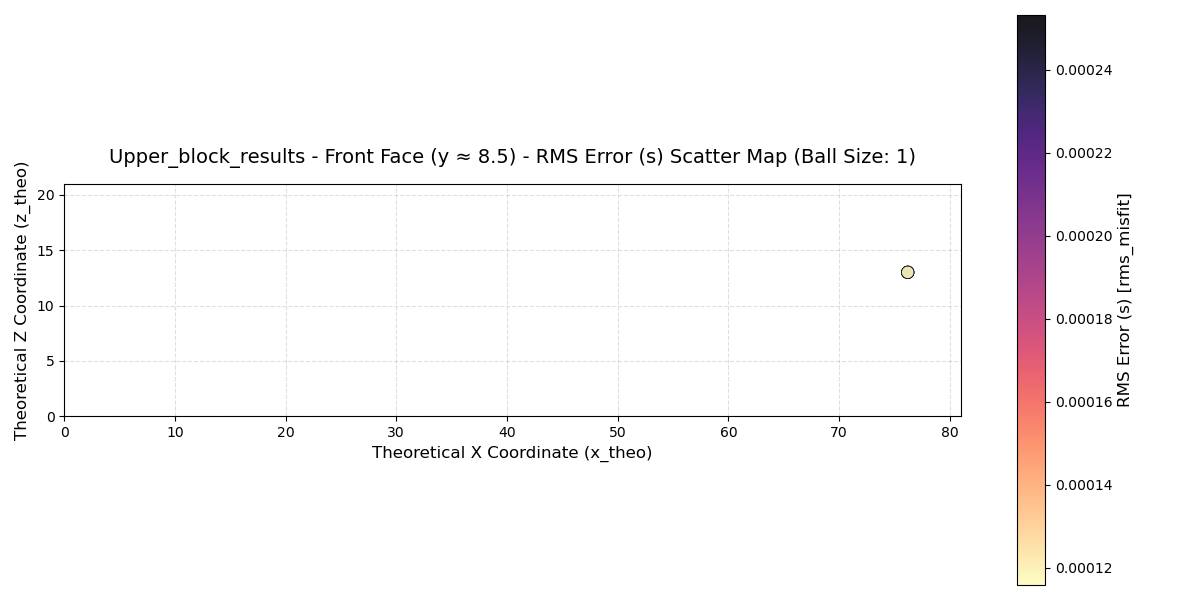

In [8]:
plot_single_face_scatter(upper_dir, target_size='1', face='front', rms_metric='rms_misfit')

In [ ]:
def plot_grouped_aggregation(
    df,
    block_name="Block",
    target_size=None,
    face=None,
    rms_metric="rms_misfit",
):
  """Aggregates the repeated drops made at identical theoretical coordinates (x_theo, z_theo)

  and plots, side by side, the Median RMS Error (accuracy) and the Error Variability given by
  the Standard Deviation (repeatability) of each position, as two coloured scatter maps.

  Each point is one theoretical drop position. The two panels have separate colour scales
  (each normalised on its own values). The figure is displayed but NOT saved, and the
  aggregated table is returned.

  Requires pandas (as pd) and matplotlib.pyplot (as plt).

  Parameters:
  -----------
  df : pd.DataFrame
      DataFrame returned by collect_block_data().
  block_name : str
      Label for plot titles (e.g., "Lower Block", "Upper Block"). If it contains 'lower'
      (case-insensitive) the X range is 0-75 cm, otherwise 0-81 cm.
  target_size : str/int, optional
      Ball size filter (e.g., '3').
  face : str, optional
      Filter by 'front' (y > 4.0), 'back' (y <= 4.0), or None (both faces; points of the two
      faces at the same (x, z) are then aggregated together). Any other value is ignored
      and both faces are used.
  rms_metric : str
      Metric column name ('rms_misfit' or 'rms_cm'). If the name contains 'cm' the unit is
      cm, otherwise seconds.

  Returns:
  --------
  agg_df : pd.DataFrame or None
      One row per (x_theo, z_theo) with the columns 'median_error', 'mean_error',
      'std_error' (0 where only one drop exists), 'max_error', 'min_error' and 'drop_count'.
      Only the median and the standard deviation are plotted. None is returned (after
      printing a message) if the input is empty or no valid data remains after filtering.
  """
  # Nothing to plot if the table is empty
  if df.empty:
    print("DataFrame is empty.")
    return

  # Work on a copy so that the caller's table is not modified
  df_filtered = df.copy()

  # 1. Filter by ball size
  if target_size is not None:
    df_filtered = df_filtered[df_filtered["size"] == str(target_size)]

  # 2. Filter by face if specified (selected with the theoretical Y coordinate)
  face_label = "Front & Back Faces"
  if face is not None:
    f_lower = face.lower()
    if f_lower == "front":
      df_filtered = df_filtered[df_filtered["y_theo"] > 4.0]
      face_label = "Front Face"
    elif f_lower == "back":
      df_filtered = df_filtered[df_filtered["y_theo"] <= 4.0]
      face_label = "Back Face"

  # Drop the rows with missing coordinates or metric
  df_filtered = df_filtered.dropna(subset=["x_theo", "z_theo", rms_metric])
  if df_filtered.empty:
    print("No valid data found matching the specified filters.")
    return

  # 3. Group by unique theoretical coordinates and compute the statistics of the repeated drops
  agg_df = (
      df_filtered.groupby(["x_theo", "z_theo"])[rms_metric]
      .agg(
          median_error="median",
          mean_error="mean",
          std_error="std",
          max_error="max",
          min_error="min",
          drop_count="count",
      )
      .reset_index()
  )

  # Fill the NaN standard deviation (for locations with only 1 drop) with 0
  agg_df["std_error"] = agg_df["std_error"].fillna(0)

  # Unit formatting: cm if the metric name contains 'cm', otherwise seconds;
  # X-axis maximum (75 cm for the lower block, 81 cm otherwise) and ball-size text for the title
  unit = "cm" if "cm" in rms_metric.lower() else "s"
  x_max = 75 if "lower" in block_name.lower() else 81
  size_str = f" (Ball Size: {target_size})" if target_size else ""

  # 4. Plotting the side-by-side analysis (two panels)
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5))

  # --- SUBPLOT 1: Median RMS Error ---
  sc1 = ax1.scatter(
      agg_df["x_theo"],
      agg_df["z_theo"],
      c=agg_df["median_error"],  # Plots Median RMS Error
      cmap="magma_r",
      s=50,
      edgecolors="k",
      linewidth=0.5,
      alpha=0.9,
  )
  cbar1 = plt.colorbar(sc1, ax=ax1)
  cbar1.set_label(f"Median RMS Error ({unit})", fontsize=11)
  ax1.set_title("1. Accuracy: Median RMS Error", fontsize=13)
  ax1.set_xlim(-1, x_max + 1)
  ax1.set_ylim(-1, 22)
  # Equal aspect ratio so that distances are not distorted
  ax1.set_aspect("equal", adjustable="box")
  ax1.set_xlabel("Distance along fault (cm)", fontsize=11)
  ax1.set_ylabel("Distance from fault (cm)", fontsize=11)
  ax1.grid(True, linestyle="--", alpha=0.4)

  # --- SUBPLOT 2: Standard Deviation (Repeatability) ---
  sc2 = ax2.scatter(
      agg_df["x_theo"],
      agg_df["z_theo"],
      c=agg_df["std_error"],
      cmap="magma_r",
      s=50,
      edgecolors="k",
      linewidth=0.5,
      alpha=0.9,
  )
  cbar2 = plt.colorbar(sc2, ax=ax2)
  cbar2.set_label(f"Standard Deviation $\\sigma$ ({unit})", fontsize=11)
  ax2.set_title(
      "2. Repeatability: Error Variability ($\sigma$)", fontsize=13
  )
  ax2.set_xlim(-1, x_max + 1)
  ax2.set_ylim(-1, 22)
  ax2.set_aspect("equal", adjustable="box")
  ax2.set_xlabel("Distance along fault (cm)", fontsize=11)
  ax2.set_ylabel("Distance from fault (cm)", fontsize=11)
  ax2.grid(True, linestyle="--", alpha=0.4)

  # Global Title
  plt.suptitle(
      f"{block_name} - {face_label} | Grouped Spatial Analysis{size_str}",
      fontsize=15,
      y=0.98,
      fontweight="bold",
  )
  fig.tight_layout()
  plt.show()

  # Return the aggregated table for further analysis
  return agg_df

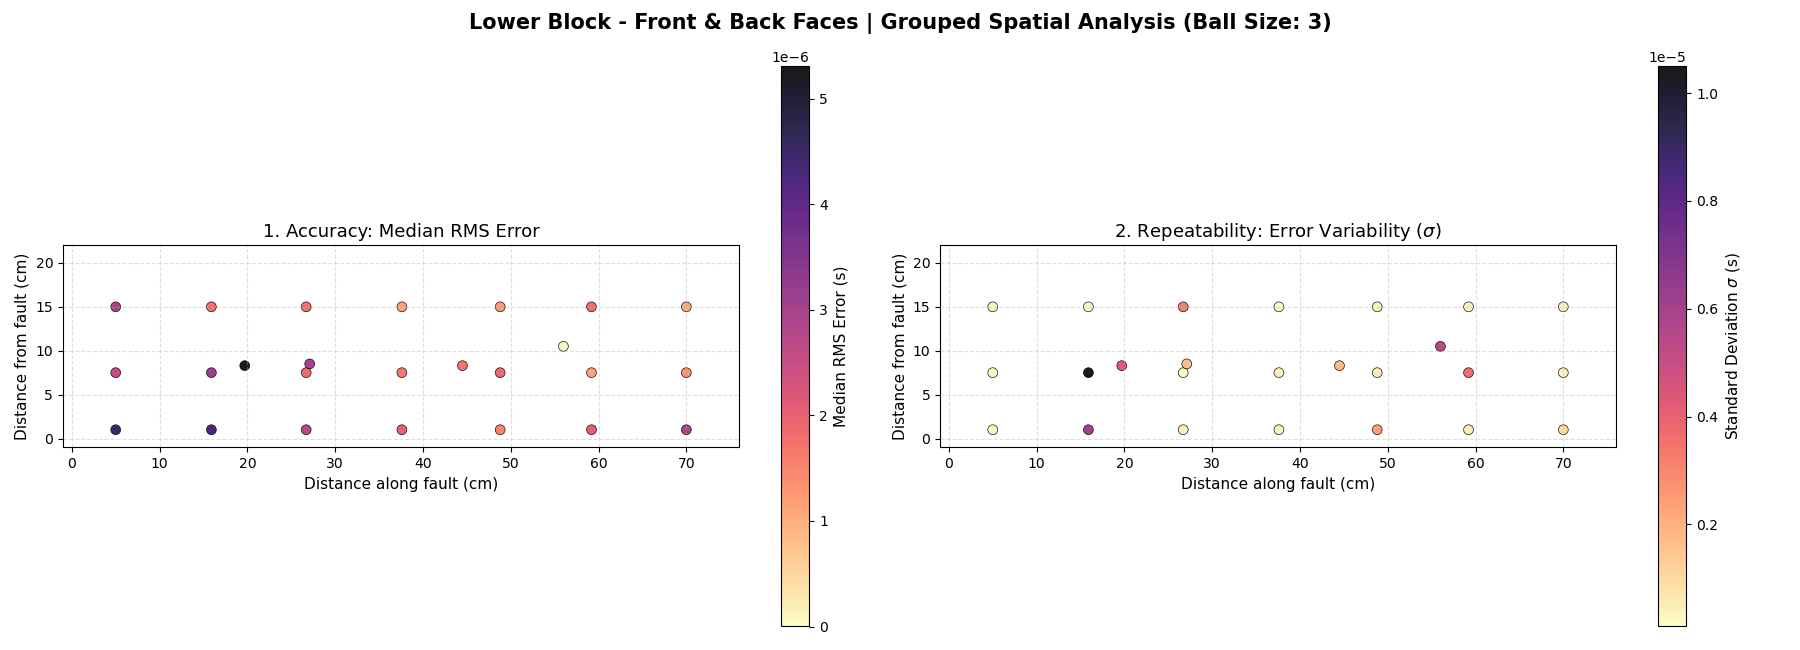

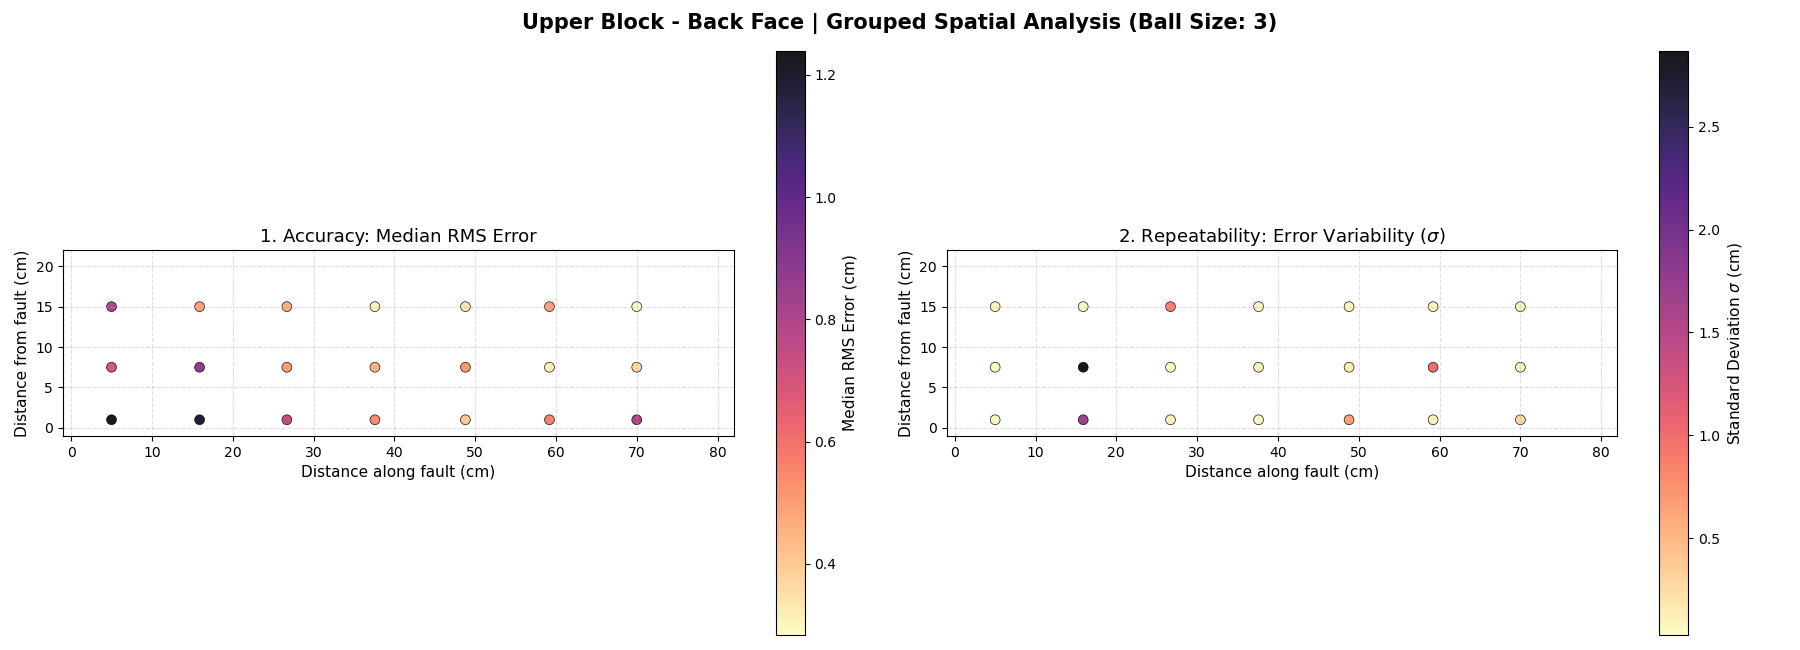

In [10]:
# Load your block data once
df_lower = collect_block_data(lower_dir)

# 1. Run grouped aggregation for the entire Lower Block (time misfit in seconds)
summary_df = plot_grouped_aggregation(
    df_lower, 
    block_name="Lower Block", 
    target_size='3', 
    face=None, 
    rms_metric='rms_misfit'
)

# 2. Run grouped aggregation for just the Front Face (spatial misfit in cm)
summary_df_front = plot_grouped_aggregation(
    df_lower, 
    block_name="Upper Block", 
    target_size='3', 
    face='back', 
    rms_metric='rms_cm'
)

In [ ]:
def plot_all_drops_aggregated(
    df_all, 
    target_size=None, 
    rms_metric='rms_misfit'
):
    """
    Combines and aggregates all the drops of both blocks and both faces into a single
    side-by-side spatial summary: the mean localization error (accuracy, left panel) and
    its standard deviation over repeated drops (repeatability, right panel).

    Each point is one theoretical drop position (x, z) on one physical surface (block + face),
    coloured by the aggregated value. Drops are assigned to a face using the theoretical Y
    coordinate: y > 4.0 is "Front" and y <= 4.0 is "Back". The two panels use separate colour
    scales, each normalised over all the points shown in that panel. The figure is displayed
    but NOT saved, and the aggregated table is returned.

    Requires numpy (as np), pandas (as pd) and matplotlib.pyplot (as plt).

    INPUT PARAMETERS:
    ----------------
    df_all : pandas.DataFrame
        Master table of all the drops, as produced by concatenating the outputs of
        `collect_block_data` for both blocks. It must contain the columns 'block', 'size',
        'x_theo', 'y_theo', 'z_theo' and the chosen RMS metric.
    target_size : str or int, optional
        If given, only the drops of this ball size are used; it is also reported in the title.
    rms_metric : str
        Name of the localization column to aggregate: 'rms_misfit' (seconds) or 'rms_cm'
        (centimetres). If the name contains 'cm' the colorbar unit is cm, otherwise s.

    OUTPUT PARAMETERS:
    -----------------
    agg_df : pandas.DataFrame or None
        One row per (block, face, x_theo, z_theo) with the columns 'mean_error',
        'std_error' (0 where only one drop exists) and 'drop_count' (number of drops).
        None is returned (after printing a message) if the input is empty or no valid data
        remains after filtering.
    """
    # Nothing to plot if the table is empty
    if df_all.empty:
        print("The provided DataFrame is empty.")
        return

    # Work on a copy so that the caller's table is not modified
    df_filtered = df_all.copy()

    # 1. Filter by ball size if specified
    if target_size is not None:
        df_filtered = df_filtered[df_filtered['size'] == str(target_size)]

    # 2. Assign the face label based on the theoretical Y coordinate (y > 4.0 -> Front, otherwise Back)
    df_filtered['face'] = np.where(df_filtered['y_theo'] > 4.0, 'Front', 'Back')

    # Drop the rows with missing essential values (X, Z or error)
    df_filtered = df_filtered.dropna(subset=['x_theo', 'z_theo', rms_metric])
    if df_filtered.empty:
        print("No valid data found matching the specified criteria.")
        return

    # 3. Group by unique theoretical spatial locations and compute the statistics of the repeated drops.
    # Including 'block' and 'face' in the grouping prevents mixing points across different physical surfaces.
    agg_df = df_filtered.groupby(['block', 'face', 'x_theo', 'z_theo'])[rms_metric].agg(
        mean_error='mean',
        std_error='std',
        drop_count='count'
    ).reset_index()

    # Fill the NaN standard deviation (locations with a single drop) with 0
    agg_df['std_error'] = agg_df['std_error'].fillna(0)

    # Metric formatting: the unit is cm if the metric name contains 'cm', otherwise seconds
    unit = 'cm' if 'cm' in rms_metric.lower() else 's'
    size_str = f" (Ball Size: {target_size})" if target_size else ""

    # 4. Figure setup: two panels side by side
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5))

    # Marker and legend label for each block/face combination. At present all the entries use the
    # same marker ('o'), so the surfaces are not visually distinguished by marker shape.
    style_map = {
        ('Lower_block_results', 'Front'): ('o', 'Lower - Front'),
        ('Lower_block_results', 'Back'):  ('o', 'Lower - Back'),
        ('Upper_block_results', 'Front'): ('o', 'Upper - Front'),
        ('Upper_block_results', 'Back'):  ('o', 'Upper - Back'),
    }

    # Colour-scale limits computed over all the subsets, so that every surface of a panel
    # is coloured on the same scale
    vmin_mean, vmax_mean = agg_df['mean_error'].min(), agg_df['mean_error'].max()
    vmin_std, vmax_std = agg_df['std_error'].min(), agg_df['std_error'].max()

    # Plot each (block, face) subset separately so that the point style matches the physical surface
    for (block_val, face_val), sub_df in agg_df.groupby(['block', 'face']):
        # Default style, used as a fallback for unexpected block names
        marker_type = 'o'
        label_str = f"{block_val} - {face_val}"
        # Look for the matching entry of style_map: the block name must contain the key's
        # block name (case-insensitive) and the face must coincide
        for key in style_map:
            if key[0].lower() in str(block_val).lower() and key[1] == face_val:
                marker_type, label_str = style_map[key]
                break

        # Panel 1: Mean Error (accuracy), coloured by the mean RMS error of each position
        sc1 = ax1.scatter(
            sub_df['x_theo'], sub_df['z_theo'],
            c=sub_df['mean_error'], cmap='magma_r', vmin=vmin_mean, vmax=vmax_mean,
            s=50, marker=marker_type,
            edgecolors='k', linewidth=0.5, alpha=0.85, label=label_str
        )

        # Panel 2: Standard Deviation (repeatability), coloured by the std of the repeated drops
        sc2 = ax2.scatter(
            sub_df['x_theo'], sub_df['z_theo'],
            c=sub_df['std_error'], cmap='magma_r', vmin=vmin_std, vmax=vmax_std,
            s=50, marker=marker_type,
            edgecolors='k', linewidth=0.5, alpha=0.85, label=label_str
        )

    # Colorbars (built from the last scatter of each panel; all subsets share the same limits)
    cbar1 = plt.colorbar(sc1, ax=ax1)
    cbar1.set_label(f'Mean RMS Error ({unit})', fontsize=11)

    cbar2 = plt.colorbar(sc2, ax=ax2)
    cbar2.set_label(f'Standard Deviation $\sigma$ ({unit})', fontsize=11)

    # Subplot formatting: titles, fixed axis ranges, equal aspect ratio, labels and grid
    for ax, title in zip([ax1, ax2], [
        '1. Spatial Accuracy (Mean RMS Error)',
        '2. Repeatability Across Drops (Std Dev $\sigma$)'
    ]):
        ax.set_title(title, fontsize=12)
        ax.set_xlim(-1, 82)
        ax.set_ylim(-1, 22)
        ax.set_aspect('equal', adjustable='box')
        ax.set_xlabel('Distance along fault (cm)', fontsize=11)
        ax.set_ylabel('Distance from fault (cm)', fontsize=11)
        ax.grid(True, linestyle='--', alpha=0.4)

    plt.suptitle(f'Global Dataset - Grouped Aggregation Summary{size_str}', fontsize=15, y=0.98, fontweight='bold')
    fig.tight_layout()
    plt.show()

    # Return the aggregated table for further analysis
    return agg_df

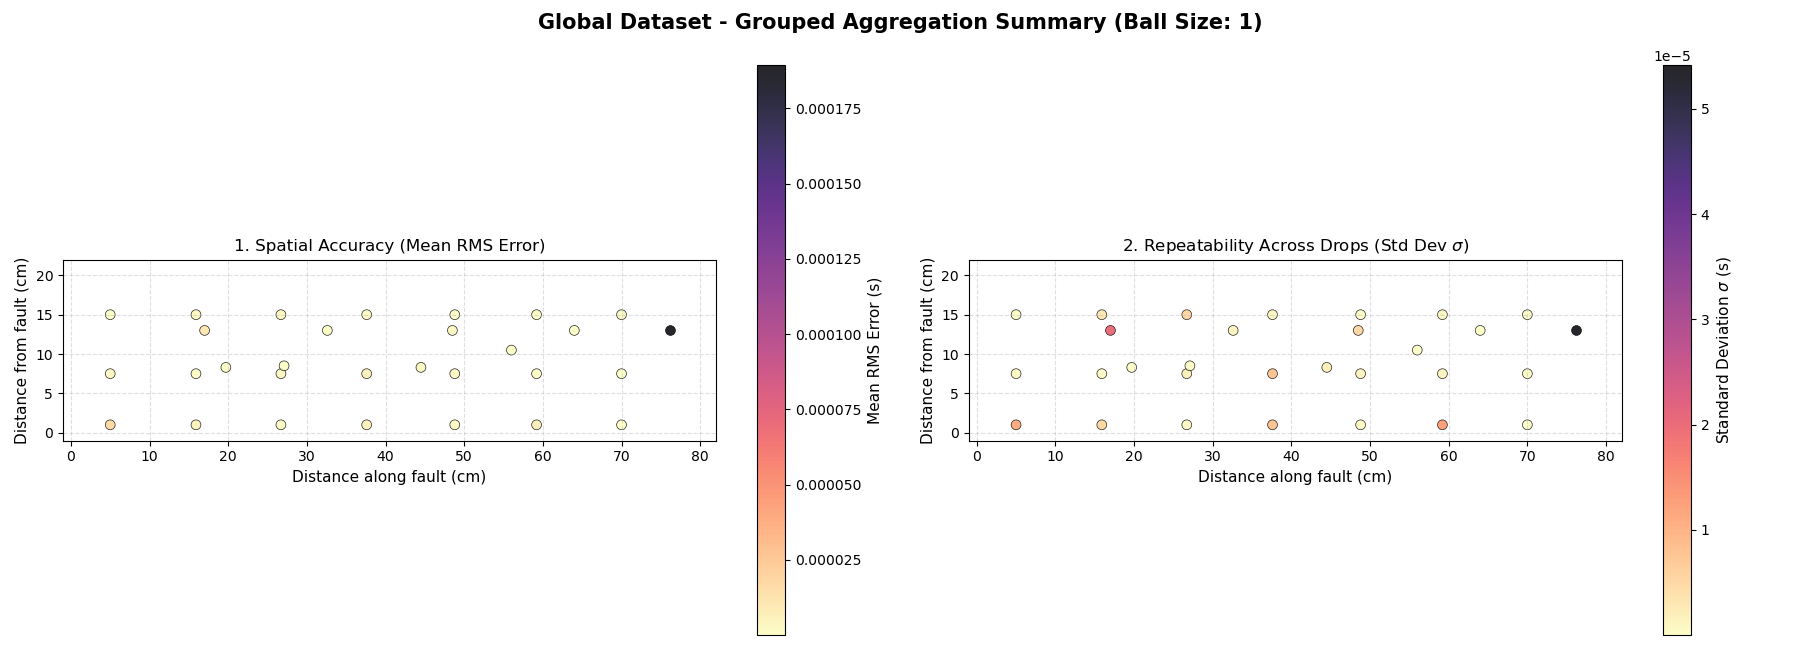

In [12]:
# Load both block datasets once
df_lower = collect_block_data(lower_dir)
df_upper = collect_block_data(upper_dir)

# Combine into a master DataFrame
df_all = pd.concat([df_lower, df_upper], ignore_index=True)

# Generate the global aggregated plot for all drops
global_summary_df = plot_all_drops_aggregated(
    df_all, 
    target_size='1', 
    rms_metric='rms_misfit'
)

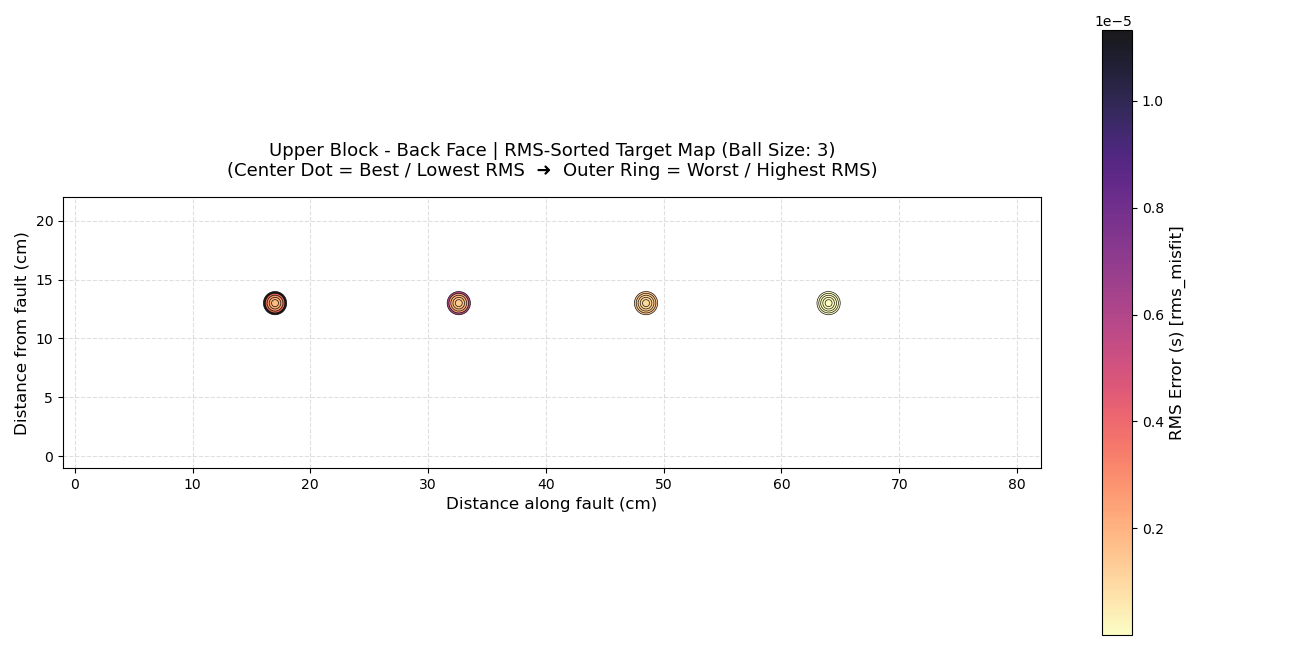

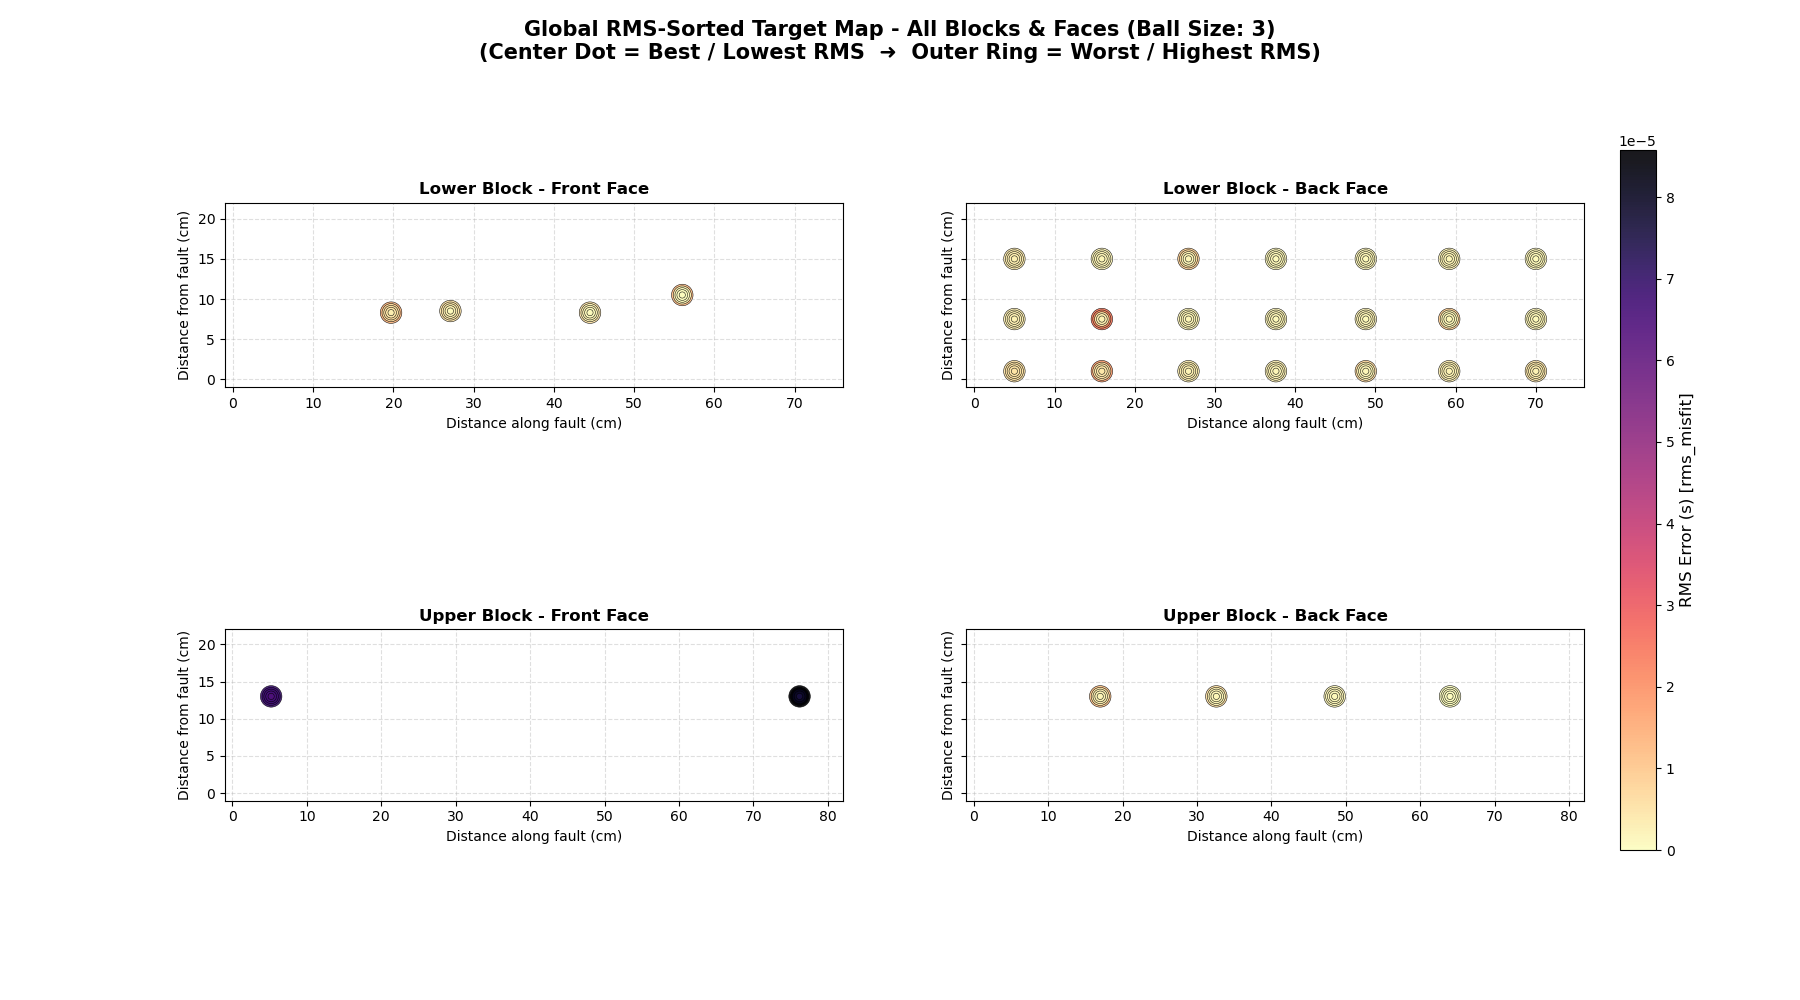

In [ ]:
def plot_concentric_sorted_by_rms(
    df_block, 
    block_name="Block", 
    target_size=None, 
    face=None, 
    rms_metric='rms_misfit'
):
    """
    Plots the repeated drops of each theoretical position as concentric rings ("target" map),
    ranked by RMS localization error:
      - Innermost center dot  = Lowest RMS (Best performance)
      - Outermost border ring = Highest RMS (Worst performance)

    For every (x_theo, z_theo) position the drops are sorted by increasing RMS error and
    ranked from 1 (best) to 5 (worst). Each rank is drawn as a marker of a different size,
    the larger ones first, so that the rings are nested around the same centre. Every marker
    is coloured by its own RMS value on a single colour scale. Only the first 5 drops of each
    position are drawn. The figure is displayed but NOT saved.

    Requires numpy (as np), pandas (as pd) and matplotlib.pyplot (as plt).

    INPUT PARAMETERS:
    ----------------
    df_block : pandas.DataFrame
        Table of the drops of ONE block, as returned by `collect_block_data`
        (columns 'size', 'x_theo', 'y_theo', 'z_theo' and the chosen RMS metric).
    block_name : str
        Label used in the title; if it contains 'lower' (case-insensitive) the X range is
        0-75 cm, otherwise 0-81 cm.
    target_size : str or int, optional
        If given, only the drops of this ball size are used; it is also reported in the title.
    face : str, optional
        'front' (y > 4.0), 'back' (y <= 4.0) or None to use both faces together (in which
        case points of the two faces at the same (x, z) overlap). Any other value is ignored
        and both faces are used.
    rms_metric : str
        Name of the localization column to plot: 'rms_misfit' (seconds) or 'rms_cm'
        (centimetres). If the name contains 'cm' the colorbar unit is cm, otherwise s.

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function only shows the figure. If the input is empty or no valid data remains
        after filtering, a message is printed and nothing is plotted.
    """
    # Nothing to plot if the table is empty
    if df_block.empty:
        print("DataFrame is empty.")
        return

    # Work on a copy so that the caller's table is not modified
    df_filtered = df_block.copy()

    # 1. Filter by ball size if specified
    if target_size is not None:
        df_filtered = df_filtered[df_filtered['size'] == str(target_size)]

    # 2. Filter by face if specified (selected with the theoretical Y coordinate)
    face_label = "Front & Back Faces"
    if face is not None:
        f_lower = face.lower()
        if f_lower == 'front':
            df_filtered = df_filtered[df_filtered['y_theo'] > 4.0]
            face_label = "Front Face"
        elif f_lower == 'back':
            df_filtered = df_filtered[df_filtered['y_theo'] <= 4.0]
            face_label = "Back Face"

    # Drop the rows with missing essential values (X, Z or error)
    df_filtered = df_filtered.dropna(subset=['x_theo', 'z_theo', rms_metric])
    if df_filtered.empty:
        print("No valid data found matching criteria.")
        return

    # 3. SORT BY RMS METRIC (ascending) AND RANK THE DROPS 1 TO 5:
    # within each (x_theo, z_theo) position, rank 1 = lowest RMS, rank 2 = second lowest, and so on
    df_filtered = df_filtered.sort_values(by=['x_theo', 'z_theo', rms_metric], ascending=True)
    df_filtered['rms_rank'] = df_filtered.groupby(['x_theo', 'z_theo']).cumcount() + 1

    # Unit (cm if the metric name contains 'cm', otherwise seconds), X-axis maximum (75 cm for the
    # lower block, 81 cm otherwise) and ball-size text for the title
    unit = 'cm' if 'cm' in rms_metric.lower() else 's'
    x_max = 75 if 'lower' in block_name.lower() else 81
    size_str = f" (Ball Size: {target_size})" if target_size else ""

    # Marker area (points^2) of each rank, from the largest (rank 5 = highest RMS) to the
    # smallest (rank 1 = lowest RMS)
    ring_sizes = {5: 280, 4: 200, 3: 130, 2: 70, 1: 25}

    fig, ax = plt.subplots(figsize=(13, 6.5))
    # Common colour scale for all the ranks
    vmin, vmax = df_filtered[rms_metric].min(), df_filtered[rms_metric].max()

    # Plot from rank 5 (largest / worst) down to rank 1 (smallest / best): the smaller markers
    # are drawn later and on top (zorder), so they appear as the inner rings
    for rank in range(5, 0, -1):
        sub_df = df_filtered[df_filtered['rms_rank'] == rank]
        
        sc = ax.scatter(
            sub_df['x_theo'], sub_df['z_theo'],
            c=sub_df[rms_metric], cmap='magma_r', vmin=vmin, vmax=vmax,
            s=ring_sizes.get(rank, 30),
            edgecolors='k', linewidth=0.5, alpha=0.9,
            zorder=6 - rank
        )

    # Colorbar (built from the last scatter; all ranks share the same limits)
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label(f'RMS Error ({unit}) [{rms_metric}]', fontsize=12)

    ax.set_xlim(-1, x_max + 1)
    ax.set_ylim(-1, 22)
    # Equal aspect ratio so that distances are not distorted
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Distance along fault (cm)', fontsize=12)
    ax.set_ylabel('Distance from fault (cm)', fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.4)

    plt.title(
        f'{block_name} - {face_label} | RMS-Sorted Target Map{size_str}\n'
        f'(Center Dot = Best / Lowest RMS  ➜  Outer Ring = Worst / Highest RMS)',
        fontsize=13, pad=15
    )
    
    fig.tight_layout()
    plt.show()

def plot_concentric_sorted_by_rms_all(
    df_all, 
    target_size=None, 
    rms_metric='rms_misfit'
):
    """
    Plots the RMS-sorted concentric-ring maps of all 4 surfaces (Lower block Front/Back and
    Upper block Front/Back) in a 2 x 2 grid, on a single common colour scale.

    The ranking is the same as in `plot_concentric_sorted_by_rms` (rank 1 = lowest RMS at a
    position = inner dot, rank 5 = highest RMS = outer ring), but it is computed separately
    for each surface and position. Only the first 5 drops of each position are drawn. The
    figure is displayed but NOT saved.

    Requires numpy (as np), pandas (as pd) and matplotlib.pyplot (as plt).

    INPUT PARAMETERS:
    ----------------
    df_all : pandas.DataFrame
        Master table of all the drops of both blocks (e.g. the concatenated outputs of
        `collect_block_data`), with the columns 'block', 'size', 'x_theo', 'y_theo', 'z_theo'
        and the chosen RMS metric. The block names must contain 'Lower_block_results' or
        'Upper_block_results' (case-insensitive) to be assigned to a panel.
    target_size : str or int, optional
        If given, only the drops of this ball size are used; it is also reported in the title.
    rms_metric : str
        Name of the localization column to plot: 'rms_misfit' (seconds) or 'rms_cm' (centimetres).

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function only shows the figure. Panels without data are titled "(No Data)". If the
        input is empty or no valid data remains after filtering, a message is printed and
        nothing is plotted.
    """
    # Nothing to plot if the table is empty
    if df_all.empty:
        print("Master DataFrame is empty.")
        return

    # Work on a copy so that the caller's table is not modified
    df_filtered = df_all.copy()

    # Optional ball-size filter
    if target_size is not None:
        df_filtered = df_filtered[df_filtered['size'] == str(target_size)]

    # Assign the face label based on the theoretical Y coordinate (y > 4.0 -> Front, otherwise Back)
    df_filtered['face'] = np.where(df_filtered['y_theo'] > 4.0, 'Front', 'Back')

    # Drop the rows with missing essential values (X, Z or error)
    df_filtered = df_filtered.dropna(subset=['x_theo', 'z_theo', rms_metric])
    if df_filtered.empty:
        print("No valid data found matching criteria.")
        return

    # Sort by RMS ascending within each surface and location, then rank the drops 1 to 5
    # (rank 1 = lowest RMS) separately for every (block, face, x_theo, z_theo)
    df_filtered = df_filtered.sort_values(by=['block', 'face', 'x_theo', 'z_theo', rms_metric], ascending=True)
    df_filtered['rms_rank'] = df_filtered.groupby(['block', 'face', 'x_theo', 'z_theo']).cumcount() + 1

    # Unit (cm if the metric name contains 'cm', otherwise seconds), title text and marker areas per rank
    # (smaller than in the single-panel version because the panels are smaller)
    unit = 'cm' if 'cm' in rms_metric.lower() else 's'
    size_str = f" (Ball Size: {target_size})" if target_size else ""
    ring_sizes = {5: 240, 4: 170, 3: 110, 2: 60, 1: 20}

    # 2 x 2 grid of panels sharing the Y axis
    fig, axes = plt.subplots(2, 2, figsize=(18, 10), sharey=True)
    # Panel layout: (block name to match, face, axes, panel title, X-axis maximum in cm)
    panels = [
        ('Lower_block_results', 'Front', axes[0, 0], 'Lower Block - Front Face', 75),
        ('Lower_block_results', 'Back',  axes[0, 1], 'Lower Block - Back Face',  75),
        ('Upper_block_results', 'Front', axes[1, 0], 'Upper Block - Front Face', 81),
        ('Upper_block_results', 'Back',  axes[1, 1], 'Upper Block - Back Face',  81),
    ]

    # Common colour scale for all the panels
    vmin, vmax = df_filtered[rms_metric].min(), df_filtered[rms_metric].max()

    for block_key, face_key, ax, title, x_max in panels:
        # Select the drops of this surface: block name containing the key (case-insensitive) and matching face
        sub_df = df_filtered[
            (df_filtered['block'].str.contains(block_key, case=False, na=False)) & 
            (df_filtered['face'] == face_key)
        ]

        # Mark the panel as empty if this surface has no data
        if sub_df.empty:
            ax.set_title(f'{title} (No Data)', fontsize=11)
            continue

        # Draw from rank 5 (largest / worst) to rank 1 (smallest / best), so that the best drops end up on top
        for rank in range(5, 0, -1):
            rank_df = sub_df[sub_df['rms_rank'] == rank]
            sc = ax.scatter(
                rank_df['x_theo'], rank_df['z_theo'],
                c=rank_df[rms_metric], cmap='magma_r', vmin=vmin, vmax=vmax,
                s=ring_sizes.get(rank, 20),
                edgecolors='k', linewidth=0.4, alpha=0.9,
                zorder=6 - rank
            )

        ax.set_title(title, fontsize=12, fontweight='bold')
        ax.set_xlim(-1, x_max + 1)
        ax.set_ylim(-1, 22)
        ax.set_aspect('equal', adjustable='box')
        ax.set_xlabel('Distance along fault (cm)', fontsize=10)
        ax.set_ylabel('Distance from fault (cm)', fontsize=10)
        ax.grid(True, linestyle='--', alpha=0.4)

    # Leave room on the right for a single colorbar shared by the four panels
    fig.subplots_adjust(right=0.88)
    cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
    cbar = fig.colorbar(sc, cax=cbar_ax)
    cbar.set_label(f'RMS Error ({unit}) [{rms_metric}]', fontsize=12)

    plt.suptitle(
        f'Global RMS-Sorted Target Map - All Blocks & Faces{size_str}\n'
        f'(Center Dot = Best / Lowest RMS  ➜  Outer Ring = Worst / Highest RMS)',
        fontsize=15, y=0.98, fontweight='bold'
    )
    
    plt.show()

# --- Usage examples ---
# (df_upper and df_all must already exist, e.g. built from `collect_block_data`)
# Single-panel map for the back face of the upper block, ball size 3, error in seconds
plot_concentric_sorted_by_rms(
    df_block=df_upper, 
    block_name="Upper Block", 
    target_size='3', 
    face='back', 
    rms_metric='rms_misfit'
)

# 4. Global 2x2 Grid for ALL 4 surfaces (Lower Front/Back + Upper Front/Back)
plot_concentric_sorted_by_rms_all(
    df_all=df_all, 
    target_size='3', 
    rms_metric='rms_misfit'
)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
import os

# NOTE: this function has the same name as the one in concentric_sorted_by_rms_commented.py,
# but it is a different version (rings by drop number + histograms, figure saved to disk).
# Do not load both in the same session, because the later definition would overwrite the earlier one.
def plot_concentric_and_hist(
    df_block, 
    block_name="Block", 
    target_size=None, 
    face=None, 
    rms_metric='rms_misfit',
    single_histogram_row=False
):
    """
    Plots the repeated drops of each theoretical position as concentric rings (top panel),
    with bar histograms of the RMS error of the individual drops underneath. The histogram
    rows have zero vertical space between them and share the X axis, strictly aligned with
    the X axis of the ring map above.

    Ring map (top): at each (x_theo, z_theo) position the drops are numbered 1 to 5 in the
    order in which they appear in the table, and drawn as nested markers of decreasing size:
    the largest ring is drop 5 and the innermost dot is drop 1. Every marker is coloured by
    its own RMS value on a single colour scale shared with the histograms. 5 drops of each
    position are drawn.

    Histograms (bottom): for each drop number a bar is drawn at the X position of the drop,
    shifted horizontally by (drop number - 3) cm so that the 5 bars of a position sit side by
    side, with height equal to the RMS error and colour from the same colour scale.
    By default there is one histogram row for each distinct Z value (highest Z at the top,
    lowest at the bottom). If single_histogram_row=True, all the Z levels are combined in a
    single row (bars with the same X and drop number but different Z then overlap).

    The figure is saved as a 300 dpi PNG in a fixed output folder and displayed.

    Requires numpy (as np), pandas (as pd), matplotlib (pyplot, cm, colors, GridSpec) and os.

    INPUT PARAMETERS:
    ----------------
    df_block : pandas.DataFrame
        Table of the drops of ONE block, as returned by `collect_block_data`
        (columns 'size', 'x_theo', 'y_theo', 'z_theo' and the chosen RMS metric).
    block_name : str
        Label used in the title and in the file name; if it contains 'lower'
        (case-insensitive) the X range is 0-75 cm, otherwise 0-81 cm.
    target_size : str or int, optional
        If given, only the drops of this ball size are used; it is also reported in the title
        and in the file name.
    face : str, optional
        'front' (y > 4.0), 'back' (y <= 4.0) or None to use both faces together. Any other
        value is ignored and both faces are used.
    rms_metric : str
        Name of the localization column to plot: 'rms_misfit' (seconds) or 'rms_cm'
        (centimetres). If the name contains 'cm' the colorbar unit is cm, otherwise s.
    single_histogram_row : bool
        If True, a single histogram row combines all the Z levels; if False (default) there
        is one row per Z level.

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function saves '<output_dir>/rms_ball_drop_<block_name>_<face>_<target_size>.png'
        (fixed output folder) and shows the figure. If the input is empty or no valid data
        remains after filtering, a message is printed and nothing is plotted.
    """
    # Nothing to plot if the table is empty
    if df_block.empty:
        print("DataFrame is empty.")
        return

    # Work on a copy so that the caller's table is not modified
    df_filtered = df_block.copy()

    # 1. Filter by ball size if specified
    if target_size is not None:
        df_filtered = df_filtered[df_filtered['size'] == str(target_size)]

    # 2. Filter by face if specified (selected with the theoretical Y coordinate)
    face_label = "Front & Back Faces"
    if face is not None:
        f_lower = face.lower()
        if f_lower == 'front':
            df_filtered = df_filtered[df_filtered['y_theo'] > 4.0]
            face_label = "Front Face"
        elif f_lower == 'back':
            df_filtered = df_filtered[df_filtered['y_theo'] <= 4.0]
            face_label = "Back Face"

    # Drop the rows with missing essential values (X, Z or error)
    df_filtered = df_filtered.dropna(subset=['x_theo', 'z_theo', rms_metric])
    if df_filtered.empty:
        print("No valid data found matching criteria.")
        return

    # Number the drops 1, 2, 3, ... within each (x_theo, z_theo) position, following the row order of the table
    df_filtered['drop_num'] = df_filtered.groupby(['x_theo', 'z_theo']).cumcount() + 1

    # Unit (cm if the metric name contains 'cm', otherwise seconds), X-axis maximum (75 cm for the
    # lower block, 81 cm otherwise) and ball-size text for the title
    unit = 'cm' if 'cm' in rms_metric.lower() else 's'
    x_max = 75 if 'lower' in block_name.lower() else 81
    size_str = f" (Ball Size: {target_size})" if target_size else ""

    # Marker area (points^2) of each drop number: drop 5 is the largest ring, drop 1 the innermost dot
    ring_sizes = {5: 1400, 4: 1000, 3: 650, 2: 350, 1: 125}

    # Sort unique_z in descending order so the highest Z is at the top and the lowest Z is at the bottom
    unique_z = sorted(df_filtered['z_theo'].unique(), reverse=True)
    
    # If single_histogram_row is True, force the number of histogram rows to 1
    num_z_rows = 1 if single_histogram_row else len(unique_z)

    # Figure configuration: the height grows with the number of histogram rows
    fig_height = 6.5 + (2.5 if single_histogram_row else 2.5 * num_z_rows)
    fig = plt.figure(figsize=(13, fig_height))
    # One row for the ring map (relative height 3) plus the histogram rows (1.5 or 1.2 each),
    # with hspace=0.0 so that the subplots touch each other
    gs = GridSpec(nrows=num_z_rows + 1, ncols=1, height_ratios=[3] + [1.5 if single_histogram_row else 1.2] * num_z_rows, hspace=0.0, figure=fig)

    # Common colour scale (and colormap) for the rings, the bars and the colorbar
    vmin, vmax = df_filtered[rms_metric].min(), df_filtered[rms_metric].max()
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    colormap = cm.magma_r

    # --- TOP PANEL: map of the concentric targets ---
    ax_map = fig.add_subplot(gs[0])

    # Draw from drop 5 (largest) to drop 1 (smallest) so that the smaller markers end up on top
    for d_num in range(5, 0, -1):
        sub_df = df_filtered[df_filtered['drop_num'] == d_num]
        sc = ax_map.scatter(
            sub_df['x_theo'], sub_df['z_theo'],
            c=sub_df[rms_metric], cmap=colormap, norm=norm,
            s=ring_sizes.get(d_num, 30),
            edgecolors='k', linewidth=0.5, alpha=0.9,
            zorder=6 - d_num
        )

    # Colorbar placed on the right, in a dedicated axes
    cbar_ax = fig.add_axes([0.88, 0.15, 0.02, 0.7])
    cbar = plt.colorbar(sc, cax=cbar_ax)
    cbar.set_label(f'RMS Error ({unit}) [{rms_metric}]', fontsize=11)

    ax_map.set_xlim(-1, x_max + 1)
    ax_map.set_ylim(-1, 22)
    # Equal aspect ratio so that distances are not distorted
    ax_map.set_aspect('equal', adjustable='box')
    ax_map.set_ylabel('Distance from fault (cm)', fontsize=11)
    ax_map.grid(True, linestyle='--', alpha=0.4)

    # Hide the X tick labels of the map (the shared X axis is labelled on the bottom histogram)
    plt.setp(ax_map.get_xticklabels(), visible=False)

    ax_map.set_title(
        f"{block_name}\n{face_label} | Target Map by Drop Sequence{size_str}\n"
        f"(Rings ordered by Drop Number 1 to 5)",
        fontsize=12, pad=12
    )

    # --- BOTTOM PANELS: histograms ---
    # Width of each bar in X units (cm); the 5 bars of a position are shifted by multiples of this width
    bar_width = 1.0
    # First histogram axes, used as the reference for sharing the X axis in the multi-row mode
    ax_first = None

    if single_histogram_row:
        # Single bottom subplot that collects the data of all the drops and all the Z levels
        ax_hist = fig.add_subplot(gs[1], sharex=ax_map)
        
        for d_num in range(1, 6):
            drop_df = df_filtered[df_filtered['drop_num'] == d_num]
            if drop_df.empty:
                continue
            
            # Shift the bar horizontally by (drop number - 3) bar widths, so that drop 3 is
            # centred on the theoretical X position and the 5 bars sit side by side
            x_shifted = drop_df['x_theo'] + (d_num - 3) * bar_width
            # Bar colours taken from the same colormap and normalisation as the map
            bar_colors = colormap(norm(drop_df[rms_metric]))
            
            ax_hist.bar(
                x_shifted, drop_df[rms_metric],
                width=bar_width, color=bar_colors, alpha=0.9, edgecolor='black', linewidth=0.5
            )

        ax_hist.set_ylabel('RMS Error', fontsize=9)
        ax_hist.grid(True, linestyle='--', alpha=0.3)
        ax_hist.set_xlim(-1, x_max + 1)
        ax_hist.set_xlabel('Distance along fault (X) [cm]', fontsize=10)

    else:
        # Multi-row mode: one histogram row for each distinct Z level (sorted from the highest to the lowest)
        for r_idx, z_val in enumerate(unique_z):
            # All the rows share the X axis: the first one with the map, the others with the first row
            if r_idx == 0:
                ax_hist = fig.add_subplot(gs[r_idx + 1], sharex=ax_map)
                ax_first = ax_hist
            else:
                ax_hist = fig.add_subplot(gs[r_idx + 1], sharex=ax_first)

            # Drops measured at this Z level only
            z_df = df_filtered[df_filtered['z_theo'] == z_val]

            for d_num in range(1, 6):
                drop_df = z_df[z_df['drop_num'] == d_num]
                if drop_df.empty:
                    continue
                
                # Same horizontal shift and colour mapping as in the single-row mode
                x_shifted = drop_df['x_theo'] + (d_num - 3) * bar_width
                bar_colors = colormap(norm(drop_df[rms_metric]))
                
                ax_hist.bar(
                    x_shifted, drop_df[rms_metric],
                    width=bar_width, color=bar_colors, alpha=0.9, edgecolor='black', linewidth=0.5
                )

            # The Y label of each row identifies its Z level
            ax_hist.set_ylabel(f'Z={z_val}cm', fontsize=9)
            ax_hist.grid(True, linestyle='--', alpha=0.3)
            ax_hist.set_xlim(-1, x_max + 1)

            # Show the X tick labels and the X label only on the bottom row
            if r_idx < num_z_rows - 1:
                plt.setp(ax_hist.get_xticklabels(), visible=False)
                ax_hist.tick_params(labelbottom=False)
            else:
                ax_hist.set_xlabel('Distance along fault (X) [cm]', fontsize=10)

    # Leave room on the right for the colorbar
    fig.subplots_adjust(right=0.85)
    
    # Saving in standard PNG format at 300 DPI (fixed output folder, created if it does not exist)
    output_dir = '/mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia'
    if not os.path.exists(output_dir):
        os.makedirs(output_dir, exist_ok=True)
        
    # The file name contains the block name, the face argument (None if not given) and the ball size
    filepath = os.path.join(output_dir, f"rms_ball_drop_{block_name}_{face}_{target_size}.png")
    plt.savefig(filepath, format='png', dpi=300, bbox_inches='tight')
    print(f"Grafico salvato con successo in: {filepath}")
    plt.show()

Grafico salvato con successo in: /mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/rms_ball_drop_Lower Block_front_1.png


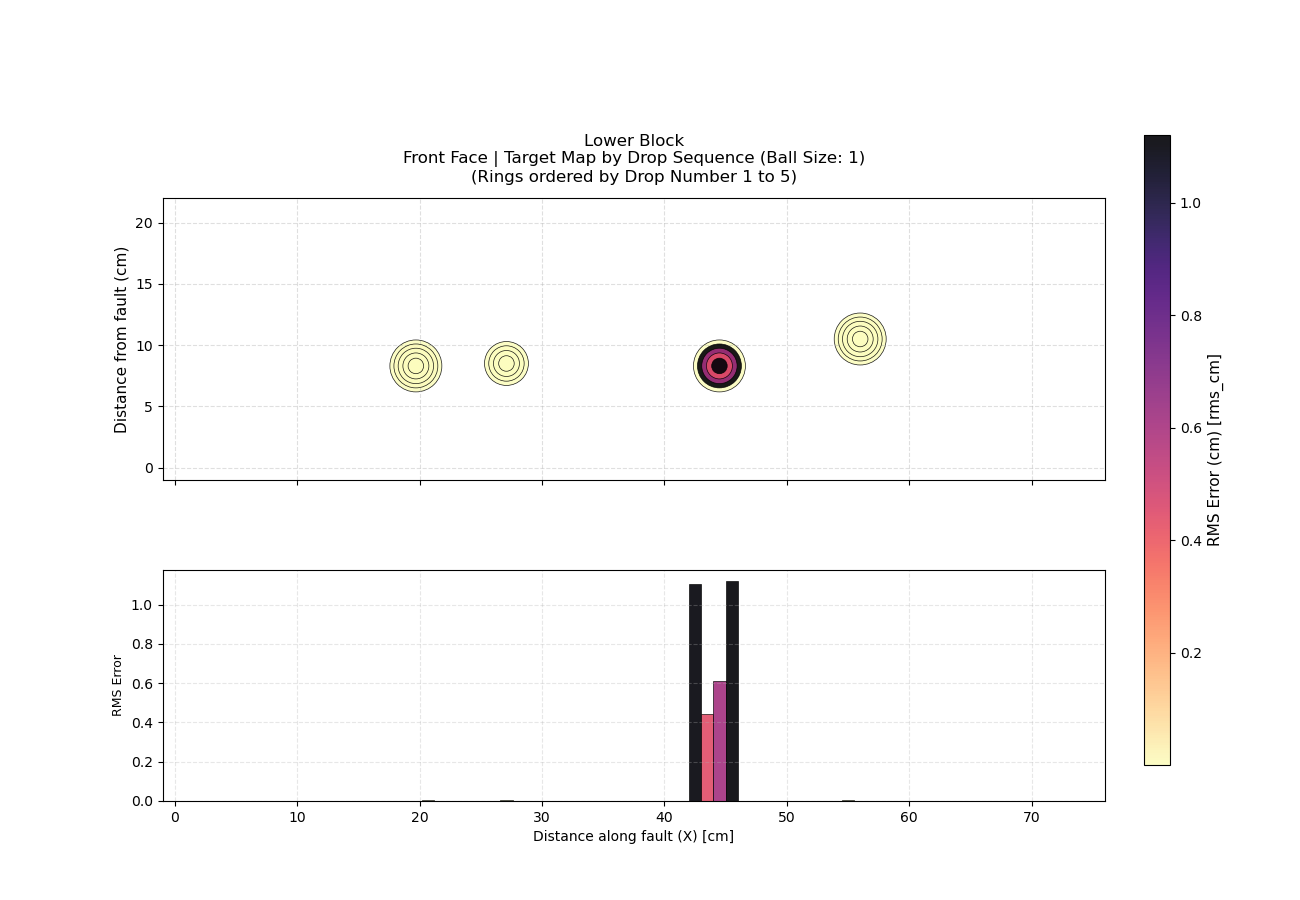

Grafico salvato con successo in: /mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/rms_ball_drop_Lower Block_back_1.png


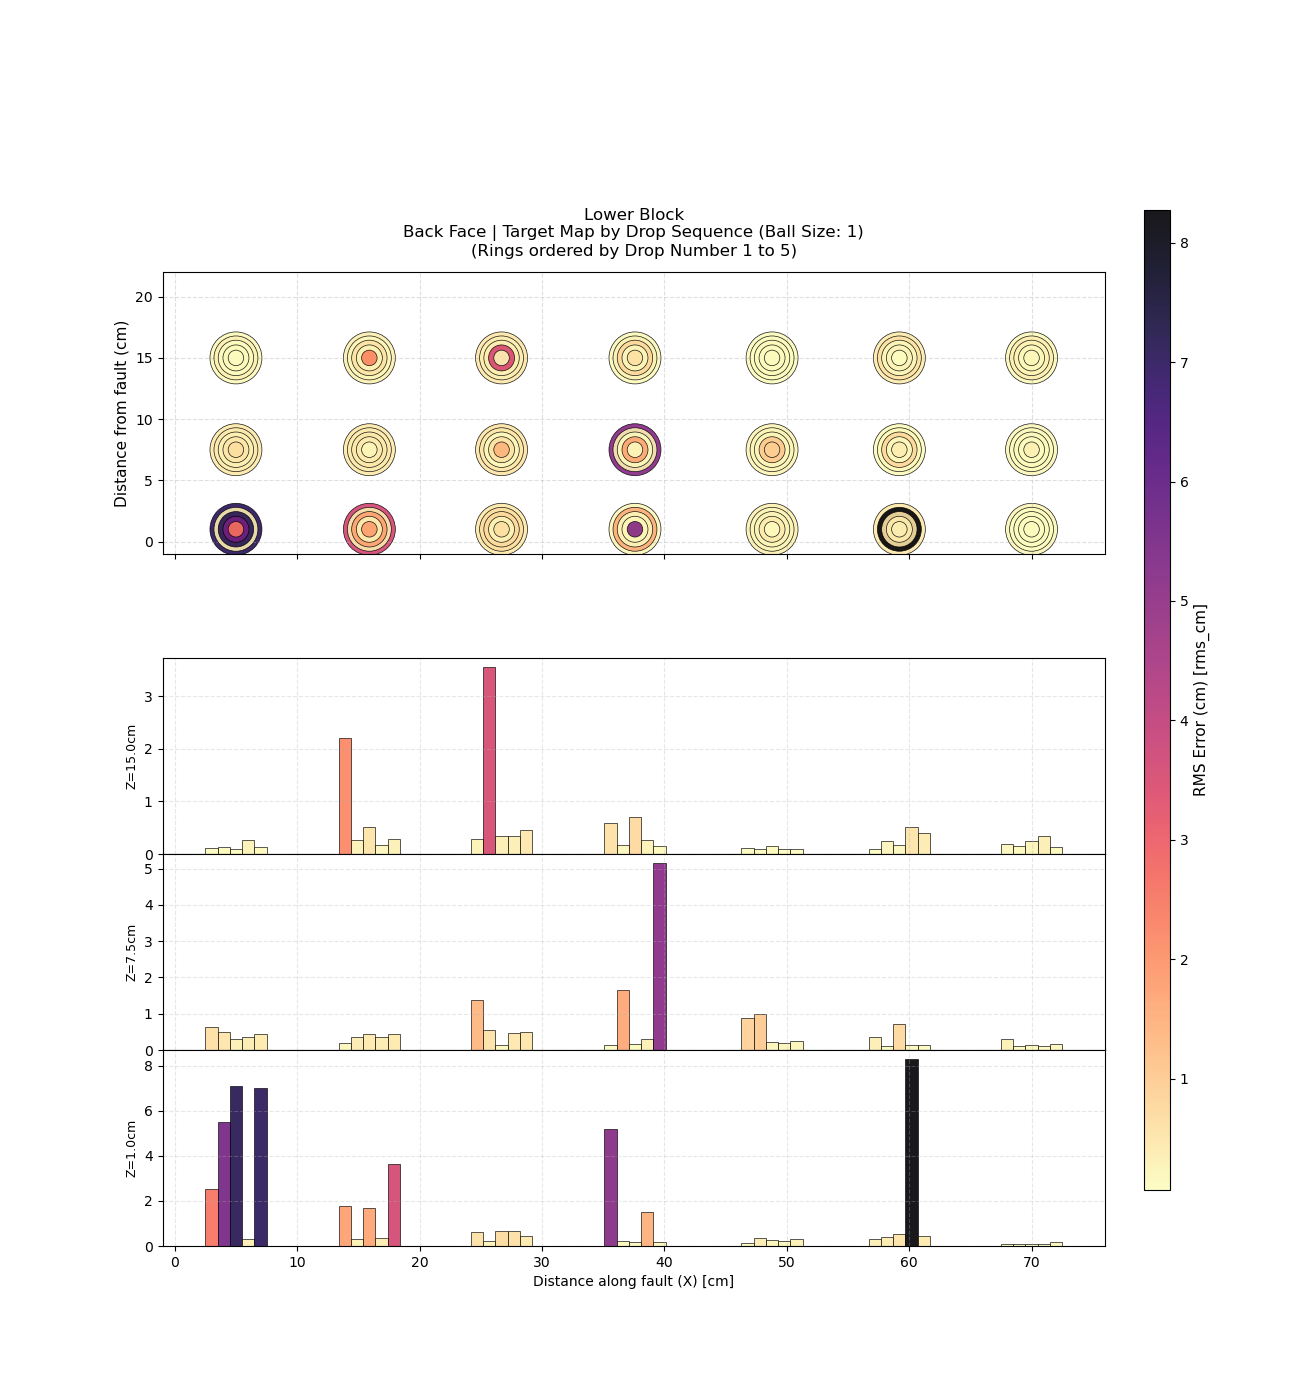

Grafico salvato con successo in: /mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/rms_ball_drop_Upper Block_front_1.png


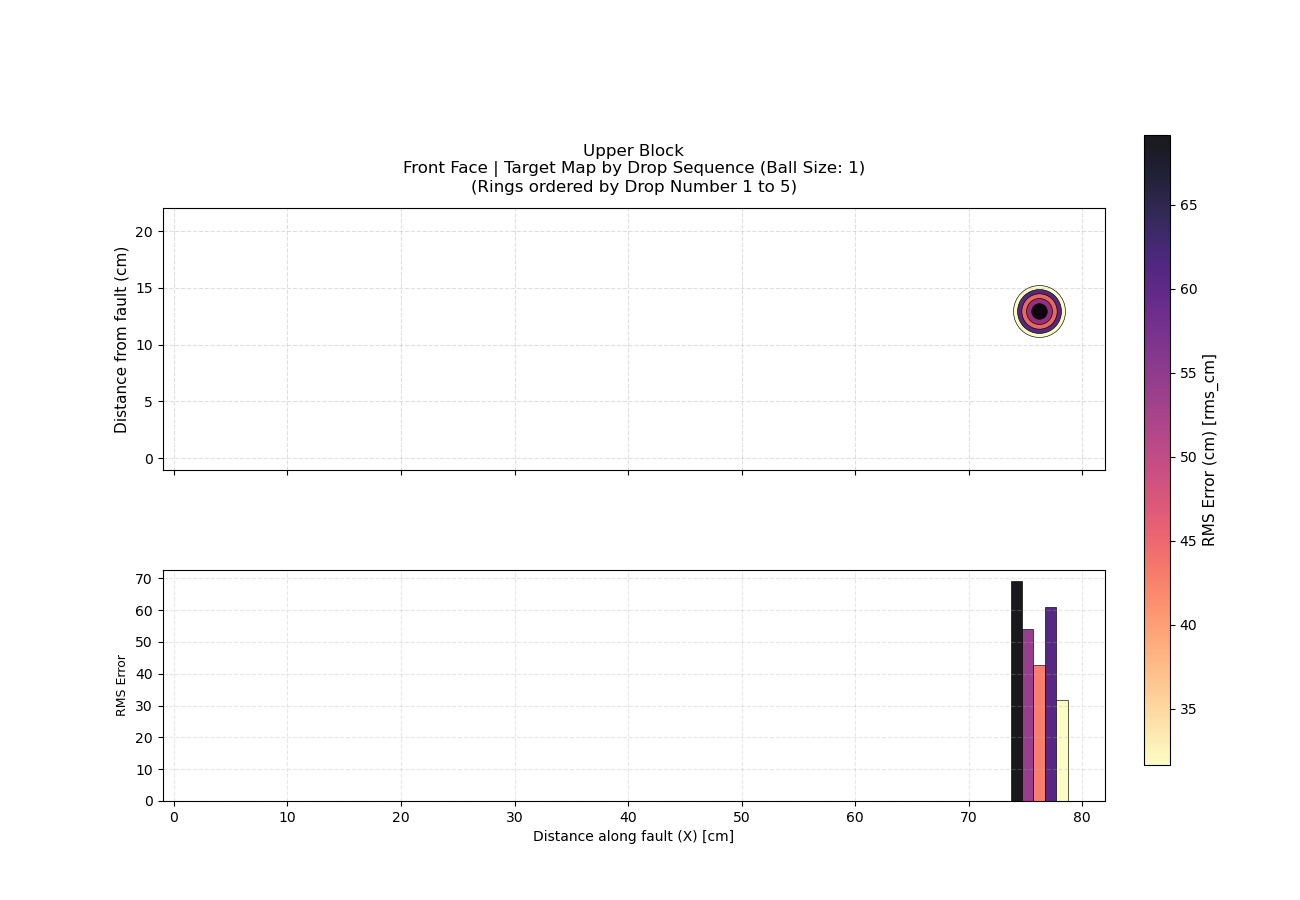

Grafico salvato con successo in: /mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/rms_ball_drop_Upper Block_back_1.png


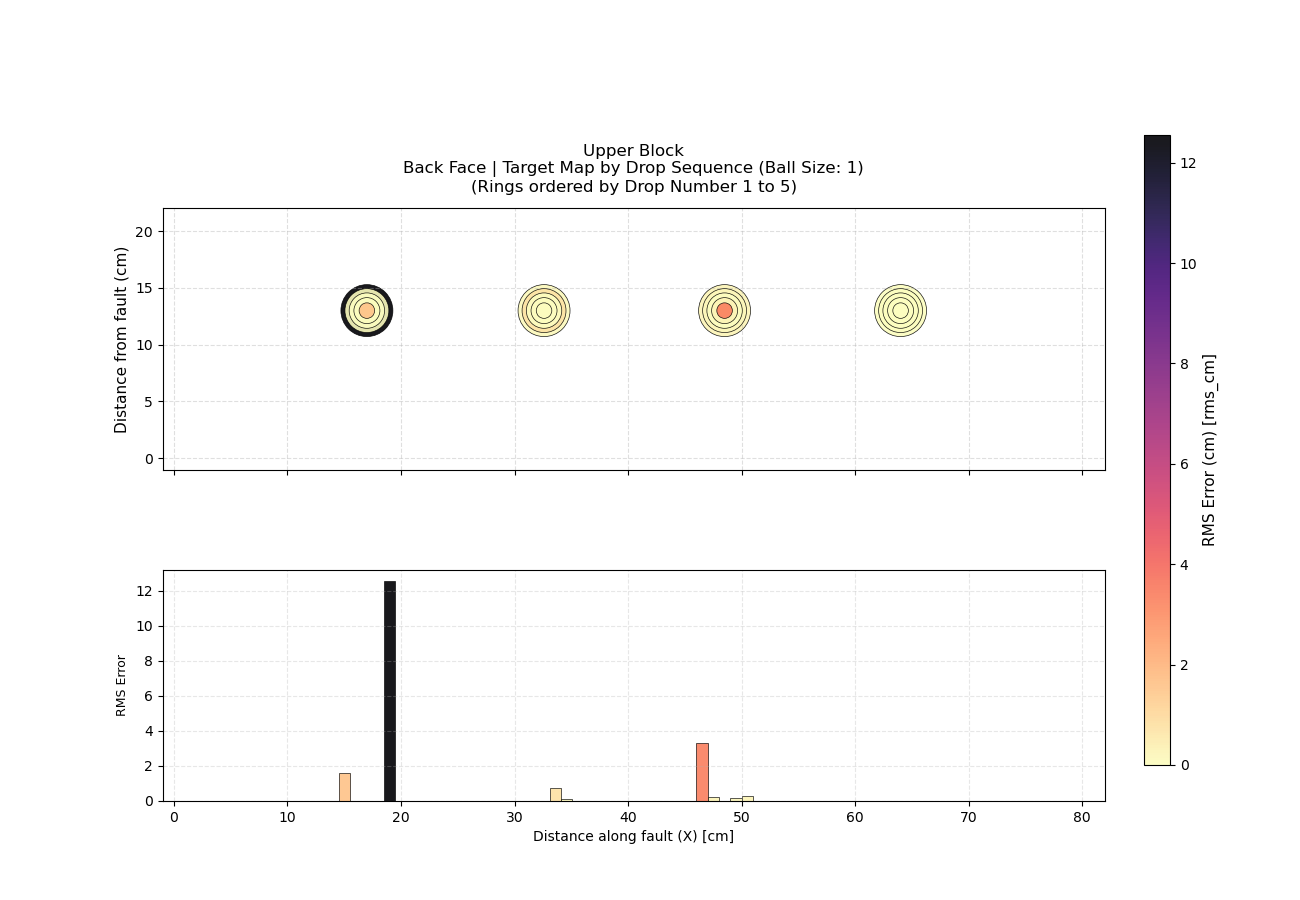

In [29]:
# Define your blocks and faces to loop through
blocks = [
    {"df": df_lower, "name": "Lower Block"},
    {"df": df_upper, "name": "Upper Block"},
]

faces = ["front", "back"]

# Loop through each combination
for block in blocks:
  for face in faces:
    # Set single_histogram_row to False only for Lower Block and back face
    if block["name"] == "Lower Block" and face == "back":
      single_histogram_row = False
    else:
      single_histogram_row = True

    # Call the plotting function
    plot_concentric_sorted_by_rms(
        df_block=block["df"],
        block_name=block["name"],
        target_size="1",
        face=face,
        rms_metric="rms_cm",
        single_histogram_row=single_histogram_row,
    )

In [ ]:
def plot_all_drops_scatter(
    df_all, 
    rms_metric='rms_misfit',
    exclude_single_surface=None
):
    """
    Plots the mean RMS localization error, with error bars, against the theoretical X
    position for every combination of block and face on a single plot, distinguishing
    between ball sizes 1 and 3.

    Statistics are computed in two steps:
      1. For each (block, face, ball size, x_theo, z_theo) position, the mean and the standard
         deviation of the RMS error over the repeated drops.
      2. For each (block, face, ball size, x_theo), the positions at the different Z levels
         are combined: the plotted value is the plain average of the per-Z means, and the
         error bar is the root-mean-square (quadratic mean) of the per-Z standard deviations.
         The error bar therefore describes the typical repeatability of the individual
         positions and does not include the differences between Z levels.

    Colour identifies the surface (block + face): Lower Front = blue, Lower Back = orange,
    Upper Front = green, Upper Back = red. Marker fill identifies the ball size: size 1 =
    filled, size 3 = open. Small horizontal offsets (jitter) are applied to separate the
    series that share the same X position. Drops are assigned to a face using the theoretical
    Y coordinate: y > 4.0 is "Front" and y <= 4.0 is "Back". A block is "Lower" if its name
    contains 'lower' (case-insensitive), otherwise "Upper".

    The figure is saved as a 300 dpi PNG with a FIXED file name ('error_bars_no_upper_front.png'),
    whatever the arguments, and displayed.

    Requires numpy (as np), pandas (as pd), matplotlib.pyplot (as plt) and os
    (the `import os` is not included in this snippet and must be available).

    Parameters:
    -----------
    df_all : DataFrame
        Master dataframe containing all drops across blocks, faces, and ball sizes
        (columns 'block', 'size', 'x_theo', 'y_theo', 'z_theo' and the chosen RMS metric).
    rms_metric : str
        Metric column to plot on the y-axis ('rms_misfit' or 'rms_cm').
        If the name contains 'cm' the unit is cm, otherwise seconds.
    exclude_single_surface : tuple of (str, str) or None
        Specify (block_name, face_name) to exclude one specific surface.
        Example: ('Lower', 'Back') or ('Upper', 'Front').

    Returns:
    --------
    agg : pandas.DataFrame or None
        Table with the mean ('mean_err') and standard deviation ('std_err') of each
        (block_clean, face, size, x_theo, z_theo) position (step 1 above). None is returned
        (after printing a message) if the input is empty or no valid data remains.
    """
    # Nothing to plot if the table is empty
    if df_all.empty:
        print("The provided DataFrame is empty.")
        return None

    # Work on a copy so that the caller's table is not modified
    df = df_all.copy()

    # 1. Data cleaning & Face/Block assignment
    # Make sure the coordinates and the error are real numbers (unparsable values become NaN);
    # if 'z_theo' is missing, Z defaults to 0
    df['x_theo'] = pd.to_numeric(df['x_theo'], errors='coerce')
    df['y_theo'] = pd.to_numeric(df['y_theo'], errors='coerce')
    df['z_theo'] = pd.to_numeric(df.get('z_theo', 0), errors='coerce')
    # Ball size as a clean string (e.g. '1', '3')
    df['size'] = df['size'].astype(str).str.strip()
    df[rms_metric] = pd.to_numeric(df[rms_metric], errors='coerce')

    # Face from the theoretical Y coordinate, and block name simplified to 'Lower Block' / 'Upper Block'
    df['face'] = np.where(df['y_theo'] > 4.0, 'Front', 'Back')
    df['block_clean'] = np.where(
        df['block'].str.contains('lower', case=False, na=False), 
        'Lower Block', 
        'Upper Block'
    )

    # 2. Exclude strictly one face of one block if specified
    if exclude_single_surface is not None:
        excl_block, excl_face = exclude_single_surface
        # Mask of the rows belonging to the surface to remove (block name contained, face equal)
        drop_mask = (
            df['block_clean'].str.contains(str(excl_block), case=False, na=False) &
            (df['face'].str.lower() == str(excl_face).lower())
        )
        df = df[~drop_mask]

    # Drop the rows with missing essential values (X, Z or error)
    df_clean = df.dropna(subset=['x_theo', 'z_theo', rms_metric])

    if df_clean.empty:
        print("No valid data found after applying filters.")
        return None

    # 3. Aggregate mean & standard deviation per position, including the ball size in the grouping
    agg = df_clean.groupby(['block_clean', 'face', 'size', 'x_theo', 'z_theo'])[rms_metric].agg(
        mean_err='mean',
        std_err='std'
    ).reset_index()

    # Fill the NaN standard deviation (positions with a single drop) with 0
    agg['std_err'] = agg['std_err'].fillna(0)

    # 4. Configurations for surfaces and ball sizes
    # For each surface: colour and horizontal offset (cm) used to separate the four series at the same X
    surfaces_config = [
        {'block': 'Lower Block', 'face': 'Front', 'color': '#1f77b4', 'offset': -0.30},
        {'block': 'Lower Block', 'face': 'Back',  'color': '#ff7f0e', 'offset': -0.10},
        {'block': 'Upper Block', 'face': 'Front', 'color': '#2ca02c', 'offset':  0.10},
        {'block': 'Upper Block', 'face': 'Back',  'color': '#d62728', 'offset':  0.30},
    ]

    # For each ball size: marker fill style, legend text, extra horizontal offset (cm) and marker edge width
    size_config = {
        '1': {'fillstyle': 'full',  'label_suffix': 'Size 1 (Filled)', 'size_offset': 0.00, 'mew': 1.0},
        '3': {'fillstyle': 'none',  'label_suffix': 'Size 3 (Open)',   'size_offset': 0.12, 'mew': 1.8}
    }

    # Unit (cm if the metric name contains 'cm', otherwise seconds) and the title text for an excluded surface
    unit = 'cm' if 'cm' in rms_metric.lower() else 's'
    excl_str = f" [Excl. {exclude_single_surface[0]} - {exclude_single_surface[1]} Face]" if exclude_single_surface else ""

    # 5. Plot Setup
    fig, ax = plt.subplots(figsize=(15, 7))

    # One series for every combination of surface and ball size
    for config in surfaces_config:
        b_label = config['block']
        f_label = config['face']
        
        for size_key in sorted(agg['size'].unique()):
            # Positions of this surface and ball size
            sub_df = agg[
                (agg['block_clean'] == b_label) & 
                (agg['face'] == f_label) &
                (agg['size'] == size_key)
            ]

            # Skip combinations without data
            if sub_df.empty:
                continue

            # Aggregate across the Z levels for each X coordinate: average of the per-Z means,
            # and root-mean-square of the per-Z standard deviations
            sub_x_agg = sub_df.groupby('x_theo').agg(
                mean_err=('mean_err', 'mean'),
                std_err=('std_err', lambda x: np.sqrt(np.mean(x**2)))
            ).reset_index()

            # Retrieve the styling of this ball size (generic defaults for any other size)
            sz_cfg = size_config.get(size_key, {
                'fillstyle': 'full', 
                'label_suffix': f'Size {size_key}', 
                'size_offset': 0.0, 
                'mew': 1.0
            })

            # X positions shifted by the surface offset plus the ball-size offset (jitter, to avoid overlaps)
            x_jittered = sub_x_agg['x_theo'] + config['offset'] + sz_cfg['size_offset']

            # Pure scatter with error bars: points = mean, bars = ± (RMS of the) standard deviation
            ax.errorbar(
                x_jittered, 
                sub_x_agg['mean_err'],
                yerr=sub_x_agg['std_err'],
                fmt='o',
                fillstyle=sz_cfg['fillstyle'],
                linestyle='none',
                color=config['color'],
                capsize=4,
                elinewidth=1.2,
                markeredgewidth=sz_cfg['mew'],
                markersize=7,
                alpha=0.85,
                label=f"{b_label} - {f_label} Face [{sz_cfg['label_suffix']}]"
            )

    # 6. Formatting
    ax.set_xlabel('Distance along fault (cm)', fontsize=11)
    ax.set_ylabel(f'Mean RMS Error ({unit})', fontsize=11)
    ax.set_title(
        f'Spatial RMS Error {excl_str}', 
        fontsize=13, 
        fontweight='bold', 
        pad=12
    )
    
    ax.set_xlim(-2, 83)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(title="Surface / Size", loc="best", fontsize=9, title_fontsize=10)

    fig.tight_layout()
    # Saving
    # Fixed output folder (created if it does not exist)
    output_dir = "/mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia"
    if not os.path.exists(output_dir):
        os.makedirs(output_dir, exist_ok=True)

    # Save as a 300 dpi PNG; the file name is fixed and does not depend on the arguments
    filepath = os.path.join(output_dir, f"error_bars_no_upper_front.png")
    plt.savefig(filepath, format="png", dpi=300, bbox_inches="tight")
    print(f"Grafico salvato con successo in: {filepath}")
    plt.show()

    return agg

# --- Usage example ---
# Mean error (in cm) of all the surfaces and both ball sizes, excluding the front face of the upper block
df_summary = plot_all_drops_scatter(
    df_all=df_all, 
    rms_metric='rms_cm',
    exclude_single_surface= ('Upper', 'front')
)

NameError: name 'df_all' is not defined